In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits"
)

ROIS = ["V1", "V2", "V3", "hV4"]

for sub in range(1, 9):
    subject = f"S{sub:02d}"
    folder = ROOT / subject / "FAST_CROSS_SESSION"

    print("\n" + "=" * 90)
    print(subject, ":", folder)
    print("=" * 90)

    if not folder.exists():
        print("FOLDER MISSING")
        continue

    for roi in ROIS:
        # We specifically want the final pcaHL 95% result,
        # not the pca0 files visible in the screenshot.
        matches = sorted([
            p for p in folder.iterdir()
            if p.is_file()
            and roi in p.name
            and "pcaHL" in p.name
            and "pca95" in p.name
        ])

        print(f"\n{roi}: {len(matches)} candidate(s)")
        for p in matches:
            print("   ", p.name)


S01 : /content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION

V1: 2 candidate(s)
    S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_2x2_cross_session.h5py
    S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py

V2: 1 candidate(s)
    S01_V2_texture_pyramid_OLS_4ori_4sf_pcaHL_V2_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py

V3: 1 candidate(s)
    S01_V3_texture_pyramid_OLS_4ori_4sf_pcaHL_V3_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py

hV4: 1 candidate(s)
    S01_hV4_texture_pyramid_OLS_4ori_4sf_pcaHL_hV4_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py

S02 : /content/drive/MyDrive/V2_drift/texturemodel/model_fits/S02/FAST_CROSS_SESSION

V1: 1 candidate(s)
    S02_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py

V2: 1 candidate(s)
    S02_V2_texture_pyramid_OLS_4ori_4sf_pcaHL_V2_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py

V3: 1 candida

In [ ]:
from pathlib import Path
import h5py
import numpy as np

ROOT = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits"
)

example = (
    ROOT
    / "S01"
    / "FAST_CROSS_SESSION"
    / "S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py"
)

print("FILE:")
print(example)
print("\n" + "=" * 100)

with h5py.File(example, "r") as f:

    print("\nATTRIBUTES")
    print("-" * 100)
    for key, value in f.attrs.items():
        print(f"{key}: {value}")

    print("\nDATASETS")
    print("-" * 100)

    def show(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(
                f"{name:<60} "
                f"shape={str(obj.shape):<25} "
                f"dtype={obj.dtype}"
            )

    f.visititems(show)

FILE:
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION/S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py


ATTRIBUTES
----------------------------------------------------------------------------------------------------
average_image_reps: 0
created_time: 2026-08-06 07:10:53
diagonal_definition: same-session model evaluated on all trials from its training session
fitting_types: ['texture_pyramid']
last_completed_train_session: 29
last_update_time: 2026-08-06 13:04:17
model_name: texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs
pca_pct_var: 95
pyr_pca_type: pcaHL
ridge: 0
roi_name: V1
saved_prfs_fn: /content/drive/MyDrive/V2_drift/prf_indices/subj01_normalized_final_best_prf_indices_V1.npy
set_lambda_per_group: 0
subject: 1
up_to_sess: 30
which_prf_grid: 5
zscore_betas_within_sess: 0
zscore_features: 0

DATASETS
-----------------------------------------------------------------------------------------

In [ ]:
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

ROOT = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits"
)

SUBJECTS = range(1, 9)
ROIS = ["V1", "V2", "V3", "hV4"]

rows = []

for sub in SUBJECTS:
    subject = f"S{sub:02d}"
    folder = ROOT / subject / "FAST_CROSS_SESSION"

    for roi in ROIS:

        pattern = (
            f"{subject}_{roi}_texture_pyramid_OLS_4ori_4sf_"
            f"pcaHL_{roi}_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py"
        )

        fn = folder / pattern

        if not fn.exists():
            rows.append({
                "subject": subject,
                "roi": roi,
                "status": "MISSING",
            })
            continue

        with h5py.File(fn, "r") as f:

            r2 = np.asarray(f["val_r2"])[..., 0]
            cc = np.asarray(f["val_cc"])[..., 0]

            completed = np.asarray(
                f["completed_train_sessions"],
                dtype=bool
            )

            n_sessions_train, n_sessions_test, n_vox = r2.shape

            # ---------------------------------------------------------
            # Basic validity
            # ---------------------------------------------------------
            finite_r2 = np.isfinite(r2)
            finite_cc = np.isfinite(cc)

            # A voxel is considered represented if it has at least
            # one finite R2 value anywhere in the session matrix.
            voxel_has_any_r2 = np.any(
                finite_r2,
                axis=(0, 1)
            )

            # ---------------------------------------------------------
            # Diagonal vs off-diagonal
            # ---------------------------------------------------------
            diag_r2 = np.stack(
                [r2[s, s, :] for s in range(n_sessions_train)],
                axis=0
            )

            offdiag_mask = ~np.eye(
                n_sessions_train,
                dtype=bool
            )

            offdiag_r2 = r2[offdiag_mask, :]

            # ROI-level matrix:
            # median across voxels, matching the SP-style summary.
            roi_matrix = np.nanmedian(
                r2,
                axis=2
            )

            # ---------------------------------------------------------
            # Drift using ALL OFF-DIAGONAL train/test cells
            # ---------------------------------------------------------
            train_idx, test_idx = np.where(offdiag_mask)

            lag = np.abs(train_idx - test_idx)

            metric = roi_matrix[
                train_idx,
                test_idx
            ]

            valid = (
                np.isfinite(metric)
                & np.isfinite(lag)
            )

            if valid.sum() > 2:
                rho, _ = spearmanr(
                    lag[valid],
                    metric[valid]
                )

                slope = np.polyfit(
                    lag[valid],
                    metric[valid],
                    1
                )[0]
            else:
                rho = np.nan
                slope = np.nan

            # ---------------------------------------------------------
            # Directional asymmetry
            # compare train i -> test j against train j -> test i
            # ---------------------------------------------------------
            upper = np.triu_indices(
                n_sessions_train,
                k=1
            )

            a = roi_matrix[upper]
            b = roi_matrix.T[upper]

            valid_ab = (
                np.isfinite(a)
                & np.isfinite(b)
            )

            if valid_ab.any():
                mean_abs_asym = np.nanmean(
                    np.abs(
                        a[valid_ab] -
                        b[valid_ab]
                    )
                )
            else:
                mean_abs_asym = np.nan

            rows.append({
                "subject": subject,
                "roi": roi,
                "status": "OK",

                "n_train_sessions": n_sessions_train,
                "n_test_sessions": n_sessions_test,
                "n_voxels": n_vox,

                "completed_train_sessions":
                    int(completed.sum()),

                "finite_r2_pct":
                    100 * finite_r2.mean(),

                "finite_cc_pct":
                    100 * finite_cc.mean(),

                "voxels_with_any_r2":
                    int(voxel_has_any_r2.sum()),

                "median_diag_r2":
                    float(np.nanmedian(diag_r2)),

                "median_offdiag_r2":
                    float(np.nanmedian(offdiag_r2)),

                "min_r2":
                    float(np.nanmin(r2)),

                "max_r2":
                    float(np.nanmax(r2)),

                "spearman_rho_r2_vs_lag":
                    float(rho),

                "slope_r2_vs_lag":
                    float(slope),

                "mean_abs_directional_asymmetry":
                    float(mean_abs_asym),
            })

qc = pd.DataFrame(rows)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

display(qc)

,subject,roi,status,n_train_sessions,n_test_sessions,n_voxels,completed_train_sessions,finite_r2_pct,finite_cc_pct,voxels_with_any_r2,median_diag_r2,median_offdiag_r2,min_r2,max_r2,spearman_rho_r2_vs_lag,slope_r2_vs_lag,mean_abs_directional_asymmetry
0,S01,V1,OK,30,30,1350,30,100.000000,100.000000,1350,0.176912,-0.159414,-26049400.0,0.568226,-0.215417,-0.002213,0.086272
1,S01,V2,OK,30,30,1433,30,100.000000,100.000000,1433,0.132988,-0.214028,-21554684.0,0.460972,-0.186874,-0.001898,0.083966
2,S01,V3,OK,30,30,1187,30,100.000000,100.000000,1187,0.121189,-0.217472,-23597792.0,0.396539,-0.267780,-0.002536,0.078773
3,S01,hV4,OK,30,30,687,30,100.000000,100.000000,687,0.094681,-0.230084,-12452715.0,0.357547,-0.300093,-0.002580,0.072696
4,S02,V1,OK,30,30,1102,30,100.000000,100.000000,1102,0.183539,-0.180630,-23493852.0,0.537364,-0.199194,-0.001851,0.087552
5,S02,V2,OK,30,30,1075,30,100.000000,100.000000,1075,0.111595,-0.229627,-17452240.0,0.472797,-0.225407,-0.001984,0.078682
6,S02,V3,OK,30,30,1097,30,100.000000,100.000000,1097,0.114172,-0.242987,-18754872.0,0.389375,-0.291458,-0.002797,0.074517
7,S02,hV4,OK,30,30,483,30,100.000000,100.000000,483,0.114617,-0.252918,-28798606.0,0.402159,-0.247040,-0.003163,0.090990
8,S03,V1,OK,30,30,1254,30,100.000000,100.000000,1254,0.145505,-0.200265,-34645972.0,0.526218,-0.160875,-0.002416,0.114616
9,S03,V2,OK,30,30,1141,30,100.000000,100.000000,1141,0.118270,-0.234589,-31654826.0,0.505075,-0.153625,-0.002108,0.114143


In [ ]:
print("\nFILES")
print(qc["status"].value_counts(dropna=False))

print("\nSESSION COMPLETENESS")
display(
    qc[
        [
            "subject",
            "roi",
            "n_train_sessions",
            "n_test_sessions",
            "completed_train_sessions",
        ]
    ]
)

print("\nVOXEL COUNTS")
display(
    qc.pivot(
        index="subject",
        columns="roi",
        values="n_voxels"
    )
)

print("\nFINITE R2 (%)")
display(
    qc.pivot(
        index="subject",
        columns="roi",
        values="finite_r2_pct"
    )
)

print("\nMEDIAN DIAGONAL R2")
display(
    qc.pivot(
        index="subject",
        columns="roi",
        values="median_diag_r2"
    )
)

print("\nMEDIAN OFF-DIAGONAL R2")
display(
    qc.pivot(
        index="subject",
        columns="roi",
        values="median_offdiag_r2"
    )
)

print("\nOBSERVED SPEARMAN RHO: R2 vs SESSION LAG")
display(
    qc.pivot(
        index="subject",
        columns="roi",
        values="spearman_rho_r2_vs_lag"
    )
)

print("\nOBSERVED SLOPE: R2 vs SESSION LAG")
display(
    qc.pivot(
        index="subject",
        columns="roi",
        values="slope_r2_vs_lag"
    )
)


FILES
status
OK    32
Name: count, dtype: int64

SESSION COMPLETENESS


,subject,roi,n_train_sessions,n_test_sessions,completed_train_sessions
0,S01,V1,30,30,30
1,S01,V2,30,30,30
2,S01,V3,30,30,30
3,S01,hV4,30,30,30
4,S02,V1,30,30,30
5,S02,V2,30,30,30
6,S02,V3,30,30,30
7,S02,hV4,30,30,30
8,S03,V1,30,30,30
9,S03,V2,30,30,30



VOXEL COUNTS


roi,V1,V2,V3,hV4
subject,,,,
S01,1350,1433,1187,687
S02,1102,1075,1097,483
S03,1254,1141,928,426
S04,877,863,808,475
S05,1113,1081,925,542
S06,1127,1180,1201,477
S07,1142,986,726,397
S08,1074,1033,889,495



FINITE R2 (%)


...

roi,V1,V2,V3,hV4
subject,,,,
S01,-0.159414,-0.214028,-0.217472,-0.230084
S02,-0.180630,-0.229627,-0.242987,-0.252918
S03,-0.200265,-0.234589,-0.248447,-0.247421
S04,-0.178416,-0.207225,-0.230963,-0.232733
S05,-0.210573,-0.240612,-0.268176,-0.256819
S06,-0.203949,-0.228405,-0.243678,-0.234599
S07,-0.209303,-0.228827,-0.240995,-0.232257
S08,-0.268273,-0.264083,-0.285787,-0.299628



OBSERVED SPEARMAN RHO: R2 vs SESSION LAG


roi,V1,V2,V3,hV4
subject,,,,
S01,-0.215417,-0.186874,-0.267780,-0.300093
S02,-0.199194,-0.225407,-0.291458,-0.247040
S03,-0.160875,-0.153625,-0.153901,-0.157037
S04,-0.142182,-0.129861,-0.182143,-0.124657
S05,-0.094733,-0.190518,-0.208001,-0.270750
S06,-0.083734,-0.137003,-0.114895,-0.139363
S07,-0.127543,-0.242288,-0.161164,-0.096208
S08,-0.183689,-0.184798,-0.229953,-0.179182



OBSERVED SLOPE: R2 vs SESSION LAG


roi,V1,V2,V3,hV4
subject,,,,
S01,-0.002213,-0.001898,-0.002536,-0.002580
S02,-0.001851,-0.001984,-0.002797,-0.003163
S03,-0.002416,-0.002108,-0.001930,-0.001960
S04,-0.001409,-0.001464,-0.002102,-0.001544
S05,-0.000896,-0.002465,-0.003045,-0.003900
S06,-0.000619,-0.001230,-0.000830,-0.001252
S07,-0.001350,-0.002500,-0.001477,-0.000876
S08,-0.002585,-0.002587,-0.003838,-0.002910


In [ ]:
# Locate the few non-finite R2 values in S06
for roi in ["V1", "V2", "V3", "hV4"]:

    fn = (
        ROOT / "S06" / "FAST_CROSS_SESSION" /
        f"S06_{roi}_texture_pyramid_OLS_4ori_4sf_"
        f"pcaHL_{roi}_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py"
    )

    with h5py.File(fn, "r") as f:
        r2 = np.asarray(f["val_r2"])[..., 0]

    bad = np.argwhere(~np.isfinite(r2))

    print(f"\n{roi}: {len(bad)} non-finite values")

    if len(bad):
        print("affected voxels:", len(np.unique(bad[:, 2])))
        print("affected train sessions:", np.unique(bad[:, 0]))
        print("affected test sessions:", np.unique(bad[:, 1]))
        print("first 10 [train, test, voxel]:")
        print(bad[:10])


V1: 180 non-finite values
affected voxels: 6
affected train sessions: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29]
affected test sessions: [3]
first 10 [train, test, voxel]:
[[   0    3  821]
 [   0    3  905]
 [   0    3  906]
 [   0    3  992]
 [   0    3  993]
 [   0    3 1067]
 [   1    3  821]
 [   1    3  905]
 [   1    3  906]
 [   1    3  992]]

V2: 540 non-finite values
affected voxels: 18
affected train sessions: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29]
affected test sessions: [3]
first 10 [train, test, voxel]:
[[   0    3  771]
 [   0    3  772]
 [   0    3  832]
 [   0    3  833]
 [   0    3  922]
 [   0    3  929]
 [   0    3  930]
 [   0    3 1017]
 [   0    3 1018]
 [   0    3 1030]]

V3: 30 non-finite values
affected voxels: 1
affected train sessions: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29]
affected test sessions: [3]


In [ ]:
for roi in ["V1", "V2", "V3"]:

    fn = (
        ROOT / "S06" / "FAST_CROSS_SESSION" /
        f"S06_{roi}_texture_pyramid_OLS_4ori_4sf_"
        f"pcaHL_{roi}_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py"
    )

    with h5py.File(fn, "r") as f:
        r2 = np.asarray(f["val_r2"])[..., 0]
        cc = np.asarray(f["val_cc"])[..., 0]

    bad_r2 = ~np.isfinite(r2)

    affected_vox = np.unique(
        np.argwhere(bad_r2)[:, 2]
    )

    print("\n" + "=" * 70)
    print("S06", roi)
    print("=" * 70)

    print("NaN R2:", np.isnan(r2).sum())
    print("+Inf R2:", np.isposinf(r2).sum())
    print("-Inf R2:", np.isneginf(r2).sum())

    print("\nAffected voxel indices:")
    print(affected_vox)

    print("\nFor test session 4:")
    for v in affected_vox:
        print(
            f"voxel {v:4d}: "
            f"R2 finite={np.isfinite(r2[:, 3, v]).sum()}/30, "
            f"CC finite={np.isfinite(cc[:, 3, v]).sum()}/30, "
            f"CC values={cc[:, 3, v]}"
        )


S06 V1
NaN R2: 180
+Inf R2: 0
-Inf R2: 0

Affected voxel indices:
[ 821  905  906  992  993 1067]

For test session 4:
voxel  821: R2 finite=0/30, CC finite=0/30, CC values=[nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan]
voxel  905: R2 finite=0/30, CC finite=0/30, CC values=[nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan]
voxel  906: R2 finite=0/30, CC finite=0/30, CC values=[nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan]
voxel  992: R2 finite=0/30, CC finite=0/30, CC values=[nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan]
voxel  993: R2 finite=0/30, CC finite=0/30, CC values=[nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan 

# ROBUSTNESS CHECK — NUMERICAL CONDITIONING

In [ ]:
# ============================================================
# BUILD pRF CONDITIONING SUMMARY FOR ALL 8 SUBJECTS
#
# PURPOSE:
# Create the subject-level prf_summary.csv files needed for
# the final conditioning robustness analysis.
#
# No regression is run.
# No plots are created.
#
# Output:
#   S01_pcaHL0/prf_summary.csv
#   ...
#   S08_pcaHL0/prf_summary.csv
# ============================================================

import os
import h5py
import numpy as np
import pandas as pd

from pathlib import Path


# ============================================================
# CONFIG
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/V2_drift"
)

SUBJECTS = [
    1, 2, 3, 4,
    5, 6, 7, 8
]

PCA_TYPE = "pcaHL"
PCA_PCT = 0

SD_THRESHOLDS = [
    1e-6,
    1e-8,
    1e-10,
    1e-12,
]


# ============================================================
# HELPERS
# ============================================================

def svd_diagnostics(
    X,
    standardize=False
):

    X = np.asarray(
        X,
        dtype=np.float64
    )

    row_ok = np.all(
        np.isfinite(X),
        axis=1
    )

    X = X[
        row_ok
    ]

    if X.shape[0] == 0:

        return {
            "condition": np.nan,
            "sigma_min": np.nan,
            "rank": 0,
        }


    # center
    Xc = (
        X
        -
        np.mean(
            X,
            axis=0,
            keepdims=True
        )
    )


    # remove exactly constant columns
    norms = np.linalg.norm(
        Xc,
        axis=0
    )

    good = (
        np.isfinite(norms)
        &
        (norms > 0)
    )

    Xc = Xc[
        :,
        good
    ]


    if Xc.shape[1] == 0:

        return {
            "condition": np.inf,
            "sigma_min": 0,
            "rank": 0,
        }


    if standardize:

        sd = np.std(
            Xc,
            axis=0,
            ddof=0
        )

        good_sd = (
            np.isfinite(sd)
            &
            (sd > 0)
        )

        Xc = Xc[
            :,
            good_sd
        ]

        sd = sd[
            good_sd
        ]

        Xc = (
            Xc
            /
            sd[
                None,
                :
            ]
        )


    S = np.linalg.svd(
        Xc,
        compute_uv=False,
        full_matrices=False
    )


    sigma_max = float(
        S[0]
    )

    sigma_min = float(
        S[-1]
    )


    tol = (
        max(
            Xc.shape
        )
        *
        np.finfo(
            np.float64
        ).eps
        *
        sigma_max
    )


    rank = int(
        np.sum(
            S > tol
        )
    )


    cond = (
        sigma_max
        /
        sigma_min
        if sigma_min > 0
        else np.inf
    )


    return {
        "condition": cond,
        "sigma_min": sigma_min,
        "rank": rank,
    }


def correlation_diagnostics(
    X
):

    X = np.asarray(
        X,
        dtype=np.float64
    )

    row_ok = np.all(
        np.isfinite(X),
        axis=1
    )

    X = X[
        row_ok
    ]


    sd = np.std(
        X,
        axis=0,
        ddof=0
    )

    good = (
        np.isfinite(sd)
        &
        (sd > 0)
    )

    X = X[
        :,
        good
    ]


    if X.shape[1] < 2:

        return (
            np.nan,
            0,
            0
        )


    C = np.corrcoef(
        X,
        rowvar=False
    )


    upper = np.triu_indices(
        C.shape[0],
        k=1
    )


    vals = np.abs(
        C[
            upper
        ]
    )


    vals = vals[
        np.isfinite(
            vals
        )
    ]


    if len(vals) == 0:

        return (
            np.nan,
            0,
            0
        )


    return (
        float(
            np.max(
                vals
            )
        ),
        int(
            np.sum(
                vals > 0.99
            )
        ),
        int(
            np.sum(
                vals > 0.999
            )
        ),
    )


# ============================================================
# MAIN SUBJECT LOOP
# ============================================================

summary_rows_all_subjects = []


for SUBJECT in SUBJECTS:

    print("\n" + "=" * 110)
    print(
        f"SUBJECT {SUBJECT}"
    )
    print("=" * 110)


    # --------------------------------------------------------
    # FILES
    # --------------------------------------------------------

    FEATURE_FILE = (
        ROOT
        / "features"
        / "pyramid_texture"
        / "PCA_pcaHL_v0"
        / f"S{SUBJECT}_4ori_4sf_pcaHL_concat_v0pct_grid5.h5py"
    )


    GLOBAL_STATS_FILE = (
        ROOT
        / "texturemodel"
        / "drift_results"
        / "global_feature_zscore"
        / f"S{SUBJECT:02d}_pcaHL0_4ori_4sf_grid5_wholedata_fixed_mean_std.npz"
    )


    OUT_DIR = (
        ROOT
        / "texturemodel"
        / "drift_results"
        / "pre_regression_diagnostics"
        / f"S{SUBJECT:02d}_pcaHL0"
    )

    OUT_DIR.mkdir(
        parents=True,
        exist_ok=True
    )


    assert FEATURE_FILE.exists(), FEATURE_FILE
    assert GLOBAL_STATS_FILE.exists(), GLOBAL_STATS_FILE


    # --------------------------------------------------------
    # IMAGE ORDER
    # --------------------------------------------------------

    G = np.load(
        GLOBAL_STATS_FILE,
        allow_pickle=True
    )


    image_order = np.asarray(
        G[
            "image_order"
        ],
        dtype=int
    ).reshape(-1)


    unique_imgs, inverse = np.unique(
        image_order,
        return_inverse=True
    )


    print(
        "Whole-data rows:",
        len(
            image_order
        )
    )

    print(
        "Unique images:",
        len(
            unique_imgs
        )
    )


    # --------------------------------------------------------
    # pRF GRID
    #
    # The nsd_grid5 candidate grid is the same 1456 pRF model
    # grid, so use the coordinates already available from S01
    # only for x/y/sigma labels.
    #
    # Better: load them directly from any FAST file for this
    # subject.
    # --------------------------------------------------------

    FAST_DIR = (
        ROOT
        / "texturemodel"
        / "model_fits"
        / f"S{SUBJECT:02d}"
        / "FAST_CROSS_SESSION"
    )


    fast_candidates = list(
        FAST_DIR.glob(
            "*30x30_cross_session.h5py"
        )
    )


    if len(
        fast_candidates
    ) == 0:

        raise FileNotFoundError(
            f"No 30x30 FAST file found for S{SUBJECT:02d}"
        )


    with h5py.File(
        fast_candidates[0],
        "r"
    ) as f:

        prf_models = np.asarray(
            f[
                "prf_models"
            ],
            dtype=np.float64
        )


    prf_models = np.squeeze(
        prf_models
    )


    print(
        "pRF model shape:",
        prf_models.shape
    )


    assert (
        prf_models.shape[0]
        ==
        1456
    )


    prf_x = prf_models[
        :,
        0
    ]

    prf_y = prf_models[
        :,
        1
    ]

    prf_sigma = prf_models[
        :,
        2
    ]


    prf_ecc = np.sqrt(
        prf_x**2
        +
        prf_y**2
    )


    # --------------------------------------------------------
    # FEATURE FILE SHAPE
    # --------------------------------------------------------

    with h5py.File(
        FEATURE_FILE,
        "r"
    ) as f:

        X = f[
            "features"
        ]

        n_images, n_features, n_prfs = (
            X.shape
        )


    print(
        "Feature matrix:",
        (
            n_images,
            n_features,
            n_prfs
        )
    )


    assert n_features == 49
    assert n_prfs == 1456


    # --------------------------------------------------------
    # OUTPUT
    # --------------------------------------------------------

    prf_rows = []


    # ========================================================
    # LOOP OVER 1456 pRFs
    # ========================================================

    with h5py.File(
        FEATURE_FILE,
        "r"
    ) as f:

        X = f[
            "features"
        ]


        for prf in range(
            n_prfs
        ):


            if (
                prf % 100 == 0
                or
                prf == n_prfs - 1
            ):

                print(
                    f"pRF {prf + 1}/{n_prfs}"
                )


            # --------------------------------------------
            # 49 low-level TS features
            # --------------------------------------------

            arr_unique = np.asarray(
                X[
                    unique_imgs,
                    :,
                    prf
                ],
                dtype=np.float64
            )


            # Restore the whole-data row distribution
            arr = arr_unique[
                inverse
            ]


            # --------------------------------------------
            # Feature SD
            # --------------------------------------------

            feature_sd = np.nanstd(
                arr,
                axis=0,
                ddof=0
            )


            finite_sd = feature_sd[
                np.isfinite(
                    feature_sd
                )
            ]


            # --------------------------------------------
            # SVD conditioning
            # --------------------------------------------

            raw_diag = svd_diagnostics(
                arr,
                standardize=False
            )


            std_diag = svd_diagnostics(
                arr,
                standardize=True
            )


            # --------------------------------------------
            # Collinearity
            # --------------------------------------------

            (
                max_corr,
                n99,
                n999
            ) = correlation_diagnostics(
                arr
            )


            # --------------------------------------------
            # Store
            # --------------------------------------------

            row = {

                "prf":
                    prf,

                "prf_x":
                    prf_x[
                        prf
                    ],

                "prf_y":
                    prf_y[
                        prf
                    ],

                "prf_sigma":
                    prf_sigma[
                        prf
                    ],

                "prf_ecc":
                    prf_ecc[
                        prf
                    ],

                "min_feature_sd":
                    np.nanmin(
                        finite_sd
                    ),

                "median_feature_sd":
                    np.nanmedian(
                        finite_sd
                    ),

                "raw_condition":
                    raw_diag[
                        "condition"
                    ],

                "log10_raw_condition":
                    (
                        np.log10(
                            raw_diag[
                                "condition"
                            ]
                        )
                        if np.isfinite(
                            raw_diag[
                                "condition"
                            ]
                        )
                        else np.inf
                    ),

                "standardized_condition":
                    std_diag[
                        "condition"
                    ],

                "log10_standardized_condition":
                    (
                        np.log10(
                            std_diag[
                                "condition"
                            ]
                        )
                        if np.isfinite(
                            std_diag[
                                "condition"
                            ]
                        )
                        else np.inf
                    ),

                "raw_sigma_min":
                    raw_diag[
                        "sigma_min"
                    ],

                "standardized_sigma_min":
                    std_diag[
                        "sigma_min"
                    ],

                "raw_rank":
                    raw_diag[
                        "rank"
                    ],

                "standardized_rank":
                    std_diag[
                        "rank"
                    ],

                "max_abs_feature_corr":
                    max_corr,

                "n_feature_pairs_abs_r_gt_099":
                    n99,

                "n_feature_pairs_abs_r_gt_0999":
                    n999,
            }


            for thr in SD_THRESHOLDS:

                row[
                    f"n_features_sd_lt_{thr:.0e}"
                ] = int(
                    np.sum(
                        finite_sd
                        <
                        thr
                    )
                )


            prf_rows.append(
                row
            )


    # ========================================================
    # SAVE SUBJECT
    # ========================================================

    prf_summary = pd.DataFrame(
        prf_rows
    )


    output_file = (
        OUT_DIR
        / "prf_summary.csv"
    )


    prf_summary.to_csv(
        output_file,
        index=False
    )


    print(
        "\nSaved:"
    )

    print(
        output_file
    )


    # --------------------------------------------------------
    # Small QC summary
    # --------------------------------------------------------

    subject_summary = {

        "subject":
            SUBJECT,

        "n_prfs":
            len(
                prf_summary
            ),

        "median_log10_raw_condition":
            np.nanmedian(
                prf_summary[
                    "log10_raw_condition"
                ]
            ),

        "median_log10_standardized_condition":
            np.nanmedian(
                prf_summary[
                    "log10_standardized_condition"
                ]
            ),

        "median_min_feature_sd":
            np.nanmedian(
                prf_summary[
                    "min_feature_sd"
                ]
            ),

        "median_n_features_sd_lt_1e-08":
            np.nanmedian(
                prf_summary[
                    "n_features_sd_lt_1e-08"
                ]
            ),

        "median_n_pairs_abs_r_gt_099":
            np.nanmedian(
                prf_summary[
                    "n_feature_pairs_abs_r_gt_099"
                ]
            ),
    }


    summary_rows_all_subjects.append(
        subject_summary
    )


# ============================================================
# ALL-SUBJECT QC
# ============================================================

all_subject_summary = pd.DataFrame(
    summary_rows_all_subjects
)


print("\n" + "=" * 110)
print("ALL SUBJECTS — pRF CONDITIONING QC")
print("=" * 110)

display(
    all_subject_summary
)


summary_file = (
    ROOT
    / "texturemodel"
    / "drift_results"
    / "pre_regression_diagnostics"
    / "all_subjects_prf_conditioning_summary.csv"
)


all_subject_summary.to_csv(
    summary_file,
    index=False
)


print("\nSaved summary:")
print(summary_file)

print("\nDONE.")


SUBJECT 1
Whole-data rows: 9209
Unique images: 9209
pRF model shape: (1456, 3)
Feature matrix: (10000, 49, 1456)
pRF 1/1456
pRF 101/1456
pRF 201/1456
pRF 301/1456
pRF 401/1456
pRF 501/1456
pRF 601/1456
pRF 701/1456
pRF 801/1456
pRF 901/1456
pRF 1001/1456
pRF 1101/1456
pRF 1201/1456
pRF 1301/1456
pRF 1401/1456
pRF 1456/1456

Saved:
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/pre_regression_diagnostics/S01_pcaHL0/prf_summary.csv

SUBJECT 2
Whole-data rows: 9209
Unique images: 9209
pRF model shape: (1456, 3)
Feature matrix: (10000, 49, 1456)
pRF 1/1456
pRF 101/1456
pRF 201/1456
pRF 301/1456
pRF 401/1456
pRF 501/1456
pRF 601/1456
pRF 701/1456
pRF 801/1456
pRF 901/1456
pRF 1001/1456
pRF 1101/1456
pRF 1201/1456
pRF 1301/1456
pRF 1401/1456
pRF 1456/1456

Saved:
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/pre_regression_diagnostics/S02_pcaHL0/prf_summary.csv

SUBJECT 3
Whole-data rows: 9209
Unique images: 9209
pRF model shape: (1456, 3)
Feature matrix: (10000, 49

,subject,n_prfs,median_log10_raw_condition,median_log10_standardized_condition,median_min_feature_sd,median_n_features_sd_lt_1e-08,median_n_pairs_abs_r_gt_099
0,1,1456,9.570689,2.866118,6.072131e-07,0.0,6.0
1,2,1456,9.604234,2.838310,6.159200e-07,0.0,6.0
2,3,1456,9.594311,2.868967,6.098827e-07,0.0,5.0
3,4,1456,9.640759,2.844944,6.060343e-07,0.0,6.0
4,5,1456,9.590354,2.850523,5.967479e-07,0.0,6.0
5,6,1456,9.595587,2.874701,5.974487e-07,0.0,5.0
6,7,1456,9.552419,2.826772,6.022834e-07,0.0,5.0
7,8,1456,9.572668,2.843103,6.080533e-07,0.0,5.0



Saved summary:
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/pre_regression_diagnostics/all_subjects_prf_conditioning_summary.csv

DONE.


In [ ]:
# ============================================================
# FINAL ROBUSTNESS CHECK:
# IS THE FINAL TS pcaHL95 DRIFT RESULT ROBUST TO
# REMOVING POORLY-CONDITIONED VOXELS?
#
# Runs:
#   8 subjects x V1/V2/V3/hV4
#
# For each Subject x ROI:
#   1. Load the existing 30x30 FAST cross-session cvR² file
#   2. Map each voxel -> its fixed pRF
#   3. Attach the subject-specific RAW pRF condition number
#   4. Remove the worst-conditioned:
#         0%, 5%, 10%, 20%, 30%, 40%, 50%
#   5. Recompute the ROI 30x30 matrix as the MEDIAN across
#      remaining voxels
#   6. Recompute Spearman(cvR², session lag)
#
# This therefore tests the SAME final single-voxel drift result
# used in the main analysis.
#
# No models are refit.
# ============================================================

import os
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.stats import spearmanr, sem

# ============================================================
# SETTINGS
# ============================================================

# Reuse notebook settings if they already exist
try:
    ROOT
except NameError:
    ROOT = Path("/content/drive/MyDrive/V2_drift/texturemodel")

ROOT = Path(ROOT)

FIT_ROOT = ROOT / "model_fits"
DRIFT_DIR = ROOT / "drift_results"

SUBJECTS = [1, 2, 3, 4, 5, 6, 7, 8]
ROIS_ROBUST = ["V1", "V2", "V3", "hV4"]

N_SESSIONS_ROBUST = 30

PCA_TYPE_ROBUST = "pcaHL"
PCA_PCT_ROBUST = 95

# Percent of WORST-conditioned voxels to remove
REMOVE_LEVELS = [0, 5, 10, 20, 30, 40, 50]

# Primary metric
CORR_METHOD_ROBUST = "spearman"

# ------------------------------------------------------------
# Subject-level pre-regression diagnostics.
#
# Expected:
# pre_regression_diagnostics/
#     S01_pcaHL0/prf_summary.csv
#     S02_pcaHL0/prf_summary.csv
#     ...
#     S08_pcaHL0/prf_summary.csv
#
# Important:
# The conditioning is a property of feature x pRF, so the same
# subject-level pRF diagnostic can be mapped to V1/V2/V3/hV4.
# ------------------------------------------------------------

PRF_DIAG_ROOT = (
    DRIFT_DIR
    / "pre_regression_diagnostics"
)

OUT_DIR_ROBUST = (
    DRIFT_DIR
    / "conditioning_robustness_all_subjects_rois"
)

OUT_DIR_ROBUST.mkdir(
    parents=True,
    exist_ok=True
)

print("=" * 110)
print("FINAL CONDITIONING ROBUSTNESS ANALYSIS")
print("=" * 110)

print("Subjects:", SUBJECTS)
print("ROIs:", ROIS_ROBUST)
print("Removal levels:", REMOVE_LEVELS)


# ============================================================
# HELPERS
# ============================================================

def find_fast_file(subject, roi):

    fast_dir = (
        FIT_ROOT
        / f"S{subject:02d}"
        / "FAST_CROSS_SESSION"
    )

    if not fast_dir.exists():
        raise FileNotFoundError(
            f"FAST folder missing: {fast_dir}"
        )

    candidates = []

    for fn in fast_dir.glob("*.h5py"):

        name = fn.name

        if (
            f"S{subject:02d}_{roi}_" in name
            and f"{PCA_TYPE_ROBUST}_{roi}_pca{PCA_PCT_ROBUST}_" in name
            and "30x30_cross_session" in name
        ):
            candidates.append(fn)

    if len(candidates) == 0:
        raise FileNotFoundError(
            f"No 30x30 FAST file found for S{subject:02d} {roi}"
        )

    if len(candidates) > 1:

        candidates = sorted(
            candidates,
            key=lambda x: x.stat().st_mtime
        )

        print(
            f"WARNING S{subject:02d} {roi}: "
            f"{len(candidates)} files found; using newest."
        )

    return candidates[-1]


def load_subject_prf_diagnostics(subject):

    fn = (
        PRF_DIAG_ROOT
        / f"S{subject:02d}_pcaHL0"
        / "prf_summary.csv"
    )

    if not fn.exists():

        raise FileNotFoundError(
            "\nMissing subject pRF diagnostic:\n"
            f"{fn}\n\n"
            "Run the pre-regression pcaHL0 conditioning diagnostic "
            f"for S{subject:02d} first."
        )

    df = pd.read_csv(fn)

    if "prf" not in df.columns:
        raise KeyError(
            f"'prf' column missing from {fn}"
        )

    if "log10_raw_condition" not in df.columns:
        raise KeyError(
            f"'log10_raw_condition' missing from {fn}"
        )

    df = df.set_index(
        "prf",
        drop=False
    )

    assert df.index.is_unique

    return df


def normalize_val_r2_shape(
    val_r2,
    n_voxels
):

    R = np.squeeze(
        val_r2
    )

    if R.ndim != 3:
        raise ValueError(
            f"Unexpected val_r2 shape after squeeze: {R.shape}"
        )

    # train x test x voxel
    if (
        R.shape[0] == N_SESSIONS_ROBUST
        and
        R.shape[1] == N_SESSIONS_ROBUST
        and
        R.shape[2] == n_voxels
    ):
        return R

    # voxel x train x test
    if (
        R.shape[0] == n_voxels
        and
        R.shape[1] == N_SESSIONS_ROBUST
        and
        R.shape[2] == N_SESSIONS_ROBUST
    ):
        return np.transpose(
            R,
            (1, 2, 0)
        )

    # train x voxel x test
    if (
        R.shape[0] == N_SESSIONS_ROBUST
        and
        R.shape[1] == n_voxels
        and
        R.shape[2] == N_SESSIONS_ROBUST
    ):
        return np.transpose(
            R,
            (0, 2, 1)
        )

    raise ValueError(
        f"Could not infer val_r2 axes: {R.shape}"
    )


# ============================================================
# SESSION-LAG MATRIX
# ============================================================

sessions = np.arange(
    N_SESSIONS_ROBUST
)

lag_matrix = np.abs(
    sessions[:, None]
    -
    sessions[None, :]
)

offdiag_mask = (
    lag_matrix > 0
)

lags_offdiag = lag_matrix[
    offdiag_mask
].astype(float)


# ============================================================
# DRIFT FROM ROI MATRIX
#
# IMPORTANT:
# This matches the main analysis logic:
#
# 1. median across voxels for every train x test cell
# 2. use all off-diagonal matrix entries
# 3. correlate GOF with session lag
# ============================================================

def compute_roi_drift(
    R,
    keep_voxels
):

    keep_voxels = np.asarray(
        keep_voxels,
        dtype=bool
    )

    if np.sum(keep_voxels) == 0:

        return {
            "rho": np.nan,
            "p": np.nan,
            "slope": np.nan,
            "matrix": None,
            "lag_values": None,
            "lag_curve": None,
        }

    # --------------------------------------------
    # Median across remaining voxels
    # --------------------------------------------

    roi_matrix = np.nanmedian(
        R[:, :, keep_voxels],
        axis=2
    )

    values = roi_matrix[
        offdiag_mask
    ].astype(float)

    good = (
        np.isfinite(values)
        &
        np.isfinite(lags_offdiag)
    )

    if np.sum(good) < 3:

        rho = np.nan
        p = np.nan
        slope = np.nan

    else:

        rho, p = spearmanr(
            lags_offdiag[good],
            values[good]
        )

        slope = np.polyfit(
            lags_offdiag[good],
            values[good],
            1
        )[0]

    # --------------------------------------------
    # Lag curve for plotting
    # --------------------------------------------

    lag_values = np.arange(
        1,
        N_SESSIONS_ROBUST
    )

    lag_curve = []

    for lag in lag_values:

        mask = (
            lag_matrix == lag
        )

        vals = roi_matrix[
            mask
        ]

        vals = vals[
            np.isfinite(vals)
        ]

        if len(vals) == 0:
            lag_curve.append(np.nan)
        else:
            lag_curve.append(
                np.nanmean(vals)
            )

    lag_curve = np.asarray(
        lag_curve,
        dtype=float
    )

    return {
        "rho": rho,
        "p": p,
        "slope": slope,
        "matrix": roi_matrix,
        "lag_values": lag_values,
        "lag_curve": lag_curve,
    }


# ============================================================
# MAIN LOOP
# ============================================================

result_rows = []

lag_curve_store = {}

file_check_rows = []


for subject in SUBJECTS:

    print("\n" + "=" * 110)
    print(f"SUBJECT {subject}")
    print("=" * 110)

    # --------------------------------------------
    # One conditioning table per subject
    # --------------------------------------------

    prf_diag = load_subject_prf_diagnostics(
        subject
    )

    print(
        "pRF diagnostic:",
        len(prf_diag),
        "pRFs"
    )

    for roi in ROIS_ROBUST:

        print(
            f"\n--- S{subject:02d} {roi} ---"
        )

        FAST_FILE = find_fast_file(
            subject,
            roi
        )

        print(
            "FAST:",
            FAST_FILE.name
        )

        with h5py.File(
            FAST_FILE,
            "r"
        ) as f:

            val_r2 = np.asarray(
                f["val_r2"]
            )

            fixed_prf = np.asarray(
                f["fixed_best_model_each_voxel"]
            ).squeeze()

            # Optional consistency check
            best_prf_by_session = np.asarray(
                f["best_prf_models"]
            ).squeeze()

            zscore_features_attr = int(
                f.attrs.get(
                    "zscore_features",
                    -1
                )
            )

            pca_pct_attr = int(
                f.attrs.get(
                    "pca_pct_var",
                    -1
                )
            )

            roi_attr = f.attrs.get(
                "roi_name",
                ""
            )

            subject_attr = int(
                f.attrs.get(
                    "subject",
                    -1
                )
            )

        fixed_prf = np.asarray(
            fixed_prf
        ).reshape(-1).astype(int)

        n_voxels = len(
            fixed_prf
        )

        R = normalize_val_r2_shape(
            val_r2,
            n_voxels
        )

        # --------------------------------------------
        # Metadata checks
        # --------------------------------------------

        assert subject_attr == subject

        assert str(roi_attr) == roi

        assert pca_pct_attr == PCA_PCT_ROBUST

        assert zscore_features_attr == 0, (
            f"S{subject:02d} {roi}: "
            f"expected zscore_features=0, "
            f"found {zscore_features_attr}"
        )

        # --------------------------------------------
        # pRF mapping validity
        # --------------------------------------------

        if not np.all(
            np.isin(
                fixed_prf,
                prf_diag.index.values
            )
        ):

            bad = np.unique(
                fixed_prf[
                    ~np.isin(
                        fixed_prf,
                        prf_diag.index.values
                    )
                ]
            )

            raise ValueError(
                f"S{subject:02d} {roi}: "
                f"pRFs missing from diagnostic table: {bad[:20]}"
            )

        # --------------------------------------------
        # Check fixed pRF agreement
        # --------------------------------------------

        best_prf_by_session = np.asarray(
            best_prf_by_session
        )

        if (
            best_prf_by_session.ndim == 2
            and
            best_prf_by_session.shape
            ==
            (
                N_SESSIONS_ROBUST,
                n_voxels
            )
        ):

            agreement = np.mean(
                best_prf_by_session.astype(int)
                ==
                fixed_prf[None, :]
            )

        else:

            agreement = np.nan

        print(
            "voxels:",
            n_voxels,
            "| unique pRFs:",
            len(np.unique(fixed_prf)),
            "| pRF agreement:",
            agreement
        )

        # --------------------------------------------
        # Attach conditioning to voxels
        # --------------------------------------------

        voxel_condition = np.asarray(
            [
                prf_diag.loc[
                    int(prf),
                    "log10_raw_condition"
                ]
                for prf in fixed_prf
            ],
            dtype=float
        )

        finite_condition = np.isfinite(
            voxel_condition
        )

        print(
            "finite conditioning:",
            np.sum(finite_condition),
            "/",
            n_voxels
        )

        # --------------------------------------------
        # Loop over exclusion thresholds
        # --------------------------------------------

        for remove_pct in REMOVE_LEVELS:

            if remove_pct == 0:

                keep = finite_condition.copy()

                cutoff = np.inf

            else:

                cutoff = np.nanpercentile(
                    voxel_condition[
                        finite_condition
                    ],
                    100 - remove_pct
                )

                keep = (
                    finite_condition
                    &
                    (
                        voxel_condition
                        <=
                        cutoff
                    )
                )

            summary = compute_roi_drift(
                R,
                keep
            )

            result_rows.append({

                "subject":
                    subject,

                "roi":
                    roi,

                "remove_worst_pct":
                    remove_pct,

                "n_voxels_original":
                    n_voxels,

                "n_voxels_remaining":
                    int(
                        np.sum(
                            keep
                        )
                    ),

                "condition_cutoff":
                    cutoff,

                "median_condition_remaining":
                    np.nanmedian(
                        voxel_condition[
                            keep
                        ]
                    ),

                "drift_spearman_rho":
                    summary[
                        "rho"
                    ],

                "drift_spearman_p":
                    summary[
                        "p"
                    ],

                "drift_linear_slope":
                    summary[
                        "slope"
                    ],
            })

            lag_curve_store[
                (
                    subject,
                    roi,
                    remove_pct
                )
            ] = (
                summary[
                    "lag_values"
                ],
                summary[
                    "lag_curve"
                ]
            )

        file_check_rows.append({

            "subject":
                subject,

            "roi":
                roi,

            "n_voxels":
                n_voxels,

            "n_unique_prfs":
                len(
                    np.unique(
                        fixed_prf
                    )
                ),

            "fixed_prf_agreement":
                agreement,

            "zscore_features":
                zscore_features_attr,

            "pca_pct_var":
                pca_pct_attr,

            "fast_file":
                str(
                    FAST_FILE
                ),
        })


results_df = pd.DataFrame(
    result_rows
)

file_check_df = pd.DataFrame(
    file_check_rows
)


# ============================================================
# BASIC CHECKS
# ============================================================

print("\n" + "=" * 110)
print("FILE / MAPPING CHECK")
print("=" * 110)

display(
    file_check_df
)


print("\n" + "=" * 110)
print("SUBJECT x ROI x CONDITIONING-FILTER RESULTS")
print("=" * 110)

display(
    results_df
)


# ============================================================
# ROI SUMMARY ACROSS SUBJECTS
# ============================================================

summary_rows = []


for roi in ROIS_ROBUST:

    for remove_pct in REMOVE_LEVELS:

        tmp = results_df[
            (
                results_df[
                    "roi"
                ]
                ==
                roi
            )
            &
            (
                results_df[
                    "remove_worst_pct"
                ]
                ==
                remove_pct
            )
        ]

        vals = tmp[
            "drift_spearman_rho"
        ].to_numpy(
            dtype=float
        )

        vals = vals[
            np.isfinite(
                vals
            )
        ]

        slopes = tmp[
            "drift_linear_slope"
        ].to_numpy(
            dtype=float
        )

        slopes = slopes[
            np.isfinite(
                slopes
            )
        ]

        summary_rows.append({

            "roi":
                roi,

            "remove_worst_pct":
                remove_pct,

            "n_subjects":
                len(
                    vals
                ),

            "mean_drift_rho":
                np.nanmean(
                    vals
                ),

            "median_drift_rho":
                np.nanmedian(
                    vals
                ),

            "sem_drift_rho":
                (
                    sem(
                        vals,
                        nan_policy="omit"
                    )
                    if len(vals) > 1
                    else np.nan
                ),

            "mean_drift_slope":
                np.nanmean(
                    slopes
                ),

            "median_drift_slope":
                np.nanmedian(
                    slopes
                ),
        })


roi_summary_df = pd.DataFrame(
    summary_rows
)


print("\n" + "=" * 110)
print("ROI SUMMARY ACROSS 8 SUBJECTS")
print("=" * 110)

display(
    roi_summary_df
)


# ============================================================
# CHANGE RELATIVE TO ORIGINAL 0% RESULT
#
# This is useful for the thesis:
# how much does the drift estimate actually move?
# ============================================================

baseline = (
    results_df[
        results_df[
            "remove_worst_pct"
        ]
        ==
        0
    ][
        [
            "subject",
            "roi",
            "drift_spearman_rho",
        ]
    ]
    .rename(
        columns={
            "drift_spearman_rho":
                "baseline_drift_rho"
        }
    )
)


results_df = results_df.merge(
    baseline,
    on=[
        "subject",
        "roi"
    ],
    how="left"
)


results_df[
    "delta_drift_rho_vs_baseline"
] = (
    results_df[
        "drift_spearman_rho"
    ]
    -
    results_df[
        "baseline_drift_rho"
    ]
)


print("\n" + "=" * 110)
print("CHANGE IN DRIFT RELATIVE TO ORIGINAL FIT")
print("=" * 110)

display(
    results_df[
        [
            "subject",
            "roi",
            "remove_worst_pct",
            "baseline_drift_rho",
            "drift_spearman_rho",
            "delta_drift_rho_vs_baseline",
            "n_voxels_remaining",
        ]
    ]
)


# ============================================================
# FIGURE 1:
# ROBUSTNESS BY ROI
#
# Mean across subjects ± SEM
# ============================================================

plt.figure(
    figsize=(8, 6)
)


for roi in ROIS_ROBUST:

    tmp = roi_summary_df[
        roi_summary_df[
            "roi"
        ]
        ==
        roi
    ].sort_values(
        "remove_worst_pct"
    )

    plt.errorbar(
        tmp[
            "remove_worst_pct"
        ],
        tmp[
            "mean_drift_rho"
        ],
        yerr=tmp[
            "sem_drift_rho"
        ],
        marker="o",
        capsize=3,
        label=roi
    )


plt.axhline(
    0,
    linewidth=1
)

plt.xlabel(
    "% worst-conditioned voxels removed"
)

plt.ylabel(
    "Mean subject Spearman(cvR², session lag)"
)

plt.title(
    "TS pcaHL95 drift robustness to numerical conditioning"
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# FIGURE 2:
# EACH SUBJECT — ORIGINAL vs FILTERED
#
# 0%, 10%, 30%, 50%
# ============================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(11, 8),
    sharex=True,
    sharey=True
)

axes = axes.ravel()


for ax, roi in zip(
    axes,
    ROIS_ROBUST
):

    for subject in SUBJECTS:

        tmp = results_df[
            (
                results_df[
                    "subject"
                ]
                ==
                subject
            )
            &
            (
                results_df[
                    "roi"
                ]
                ==
                roi
            )
            &
            (
                results_df[
                    "remove_worst_pct"
                ]
                .isin(
                    [
                        0,
                        10,
                        30,
                        50
                    ]
                )
            )
        ].sort_values(
            "remove_worst_pct"
        )

        ax.plot(
            tmp[
                "remove_worst_pct"
            ],
            tmp[
                "drift_spearman_rho"
            ],
            marker="o",
            alpha=0.6,
            linewidth=1
        )

    ax.axhline(
        0,
        linewidth=1
    )

    ax.set_title(
        roi
    )

    ax.set_xlabel(
        "% worst-conditioned removed"
    )

    ax.set_ylabel(
        "Spearman(cvR², lag)"
    )


plt.suptitle(
    "Subject-level conditioning robustness",
    y=1.02
)

plt.tight_layout()

plt.show()


# ============================================================
# FIGURE 3:
# BASELINE vs REMOVE WORST 30%
#
# If points lie near identity, the subject x ROI drift pattern
# is highly robust.
# ============================================================

base30 = (
    results_df[
        results_df[
            "remove_worst_pct"
        ]
        .isin(
            [
                0,
                30
            ]
        )
    ]
    .pivot(
        index=[
            "subject",
            "roi"
        ],
        columns="remove_worst_pct",
        values="drift_spearman_rho"
    )
    .dropna()
)


if (
    0 in base30.columns
    and
    30 in base30.columns
):

    x = base30[
        0
    ].to_numpy(
        dtype=float
    )

    y = base30[
        30
    ].to_numpy(
        dtype=float
    )

    rho_30, p_30 = spearmanr(
        x,
        y
    )

    plt.figure(
        figsize=(6, 6)
    )

    plt.scatter(
        x,
        y,
        s=45
    )

    lo = min(
        np.nanmin(x),
        np.nanmin(y)
    )

    hi = max(
        np.nanmax(x),
        np.nanmax(y)
    )

    plt.plot(
        [lo, hi],
        [lo, hi],
        linestyle="--"
    )

    plt.xlabel(
        "Original drift rho"
    )

    plt.ylabel(
        "Drift rho after removing worst 30%"
    )

    plt.title(
        "Preservation of Subject × ROI drift estimates\n"
        f"Spearman rho={rho_30:.3f}, p={p_30:.3g}"
    )

    plt.tight_layout()

    plt.show()

    print(
        "\nOriginal vs remove-30% correlation:",
        rho_30,
        "p =",
        p_30
    )


# ============================================================
# FIGURE 4:
# ROI PATTERN AT SELECTED FILTER LEVELS
#
# This directly asks whether the hierarchical pattern among
# V1/V2/V3/hV4 is preserved.
# ============================================================

plt.figure(
    figsize=(8, 6)
)


x_roi = np.arange(
    len(
        ROIS_ROBUST
    )
)


for remove_pct in [
    0,
    10,
    30,
    50
]:

    vals = []

    for roi in ROIS_ROBUST:

        row = roi_summary_df[
            (
                roi_summary_df[
                    "roi"
                ]
                ==
                roi
            )
            &
            (
                roi_summary_df[
                    "remove_worst_pct"
                ]
                ==
                remove_pct
            )
        ]

        vals.append(
            float(
                row[
                    "mean_drift_rho"
                ].iloc[0]
            )
        )

    plt.plot(
        x_roi,
        vals,
        marker="o",
        label=f"remove worst {remove_pct}%"
    )


plt.axhline(
    0,
    linewidth=1
)

plt.xticks(
    x_roi,
    ROIS_ROBUST
)

plt.ylabel(
    "Mean subject Spearman(cvR², lag)"
)

plt.xlabel(
    "ROI"
)

plt.title(
    "Is the cross-ROI drift pattern robust to conditioning?"
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# OPTIONAL REPEATED-MEASURES ROI TEST
#
# Same logic at each exclusion level:
# does the ROI effect remain?
# ============================================================

print("\n" + "=" * 110)
print("REPEATED-MEASURES ROI EFFECT BY CONDITIONING FILTER")
print("=" * 110)


try:

    from statsmodels.stats.anova import AnovaRM

    anova_rows = []

    for remove_pct in REMOVE_LEVELS:

        tmp = results_df[
            results_df[
                "remove_worst_pct"
            ]
            ==
            remove_pct
        ][
            [
                "subject",
                "roi",
                "drift_spearman_rho"
            ]
        ].dropna()

        # Require complete 8 x 4 repeated-measures design
        counts = tmp.groupby(
            "subject"
        )[
            "roi"
        ].nunique()

        complete_subjects = counts[
            counts
            ==
            len(
                ROIS_ROBUST
            )
        ].index

        tmp = tmp[
            tmp[
                "subject"
            ].isin(
                complete_subjects
            )
        ]

        if len(
            complete_subjects
        ) < 2:

            continue

        fit = AnovaRM(
            data=tmp,
            depvar="drift_spearman_rho",
            subject="subject",
            within=[
                "roi"
            ]
        ).fit()

        tab = fit.anova_table

        F = float(
            tab.loc[
                "roi",
                "F Value"
            ]
        )

        pval = float(
            tab.loc[
                "roi",
                "Pr > F"
            ]
        )

        num_df = float(
            tab.loc[
                "roi",
                "Num DF"
            ]
        )

        den_df = float(
            tab.loc[
                "roi",
                "Den DF"
            ]
        )

        anova_rows.append({

            "remove_worst_pct":
                remove_pct,

            "n_subjects":
                len(
                    complete_subjects
                ),

            "F":
                F,

            "df_num":
                num_df,

            "df_den":
                den_df,

            "p":
                pval,
        })


    anova_df = pd.DataFrame(
        anova_rows
    )

    display(
        anova_df
    )

except Exception as e:

    print(
        "Repeated-measures ANOVA skipped:"
    )

    print(
        e
    )

    anova_df = pd.DataFrame()


# ============================================================
# SAVE EVERYTHING
# ============================================================

results_file = (
    OUT_DIR_ROBUST
    / "subject_roi_conditioning_robustness.csv"
)

summary_file = (
    OUT_DIR_ROBUST
    / "roi_conditioning_robustness_summary.csv"
)

check_file = (
    OUT_DIR_ROBUST
    / "fast_file_and_prf_mapping_check.csv"
)

anova_file = (
    OUT_DIR_ROBUST
    / "roi_effect_conditioning_robustness.csv"
)


results_df.to_csv(
    results_file,
    index=False
)

roi_summary_df.to_csv(
    summary_file,
    index=False
)

file_check_df.to_csv(
    check_file,
    index=False
)

if len(
    anova_df
) > 0:

    anova_df.to_csv(
        anova_file,
        index=False
    )


print("\n" + "=" * 110)
print("SAVED")
print("=" * 110)

print(results_file)
print(summary_file)
print(check_file)

if len(
    anova_df
) > 0:
    print(anova_file)


print("\nDONE.")

# SP 4 levels vs TS, across all 8 subjects × V1/V2/V3/hV4 × within-session R² and Pearson.

In [6]:
from pathlib import Path
import pickle
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# =============================================================================
# CONFIG
# =============================================================================

SP_ROOT = Path(
    "/content/drive/MyDrive/V1_Drift/repDrift_expand"
)

TS_ROOT = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits"
)

SUBJECTS = list(range(1, 9))
ROIS = ["V1", "V2", "V3", "hV4"]

N_SESSIONS = 30


# =============================================================================
# HELPER: LOAD SP SUBJECT
# =============================================================================

def load_sp_subject(subject):

    fn = SP_ROOT / f"regressSessCombineROI_sub{subject}.pkl"

    if not fn.exists():
        raise FileNotFoundError(
            f"SP file not found:\n{fn}"
        )

    with open(fn, "rb") as f:
        data = pickle.load(f)

    return fn, data


# =============================================================================
# HELPER: FIND TS FILE
# =============================================================================

def get_ts_file(subject, roi):

    subject_name = f"S{subject:02d}"

    folder = (
        TS_ROOT
        / subject_name
        / "FAST_CROSS_SESSION"
    )

    exact_name = (
        f"{subject_name}_{roi}_"
        f"texture_pyramid_OLS_4ori_4sf_"
        f"pcaHL_{roi}_pca95_"
        f"use_nsd_grid5_pRFs_"
        f"30x30_cross_session.h5py"
    )

    fn = folder / exact_name

    if not fn.exists():

        # fallback search, in case filename differs slightly
        candidates = list(
            folder.glob(
                f"*{roi}*pcaHL*{roi}*pca95*30x30_cross_session.h5py"
            )
        )

        if len(candidates) == 1:
            fn = candidates[0]

        elif len(candidates) == 0:
            raise FileNotFoundError(
                f"No TS file found for S{subject:02d} {roi}\n"
                f"Expected:\n{fn}"
            )

        else:
            raise RuntimeError(
                f"Multiple TS files found for S{subject:02d} {roi}:\n"
                + "\n".join(str(x) for x in candidates)
            )

    return fn


# =============================================================================
# HELPER: SP R2 WITHIN-SESSION
# =============================================================================

def extract_sp_r2_within(arr, n_sessions=30):
    """
    Extract SP within-session R².

    Expected roiNsdOriR2within structure is typically:
        (31, voxels)

    where:
        rows 0:30 = sessions 1:30
        row 30    = appended across-session summary

    Returns:
        (30, voxels)
    """

    arr = np.asarray(arr)
    arr = np.squeeze(arr)

    if arr.ndim != 2:
        raise ValueError(
            f"Unexpected roiNsdOriR2within shape: {arr.shape}"
        )

    # Expected orientation:
    # sessions x voxels
    if arr.shape[0] in [n_sessions, n_sessions + 1]:
        out = arr[:n_sessions, :]

    # Defensive alternative:
    # voxels x sessions
    elif arr.shape[1] in [n_sessions, n_sessions + 1]:
        out = arr[:, :n_sessions].T

    else:
        raise ValueError(
            "Could not identify session dimension for "
            f"roiNsdOriR2within: {arr.shape}"
        )

    assert out.shape[0] == n_sessions

    return out


# =============================================================================
# HELPER: SP PEARSON WITHIN-SESSION
# =============================================================================

def extract_sp_corr_within(arr, n_sessions=30):
    """
    roiNsdOriCorr observed structure:
        (31, voxels, 30)

    Interpretation:
        axis 0 = fitted/train session (+ appended mean row)
        axis 1 = voxel
        axis 2 = evaluation/test session

    Within-session Pearson:
        [session, voxel, same session]

    Returns:
        (30, voxels)
    """

    arr = np.asarray(arr)
    arr = np.squeeze(arr)

    if arr.ndim != 3:
        raise ValueError(
            f"Unexpected roiNsdOriCorr shape: {arr.shape}"
        )

    # Expected:
    # (30 or 31, voxels, 30)
    if (
        arr.shape[0] in [n_sessions, n_sessions + 1]
        and
        arr.shape[2] == n_sessions
    ):

        arr = arr[:n_sessions, :, :]

        out = np.stack(
            [
                arr[s, :, s]
                for s in range(n_sessions)
            ],
            axis=0
        )

    else:
        raise ValueError(
            "Unexpected roiNsdOriCorr dimensions. "
            f"Got {arr.shape}; expected approximately "
            f"(31, voxels, {n_sessions})."
        )

    assert out.shape[0] == n_sessions

    return out


# =============================================================================
# HELPER: TS WITHIN-SESSION
# =============================================================================

def extract_ts_diagonal(arr, n_sessions=30):
    """
    TS val_r2 / val_cc:
        train_session x test_session x voxel

    Returns diagonal:
        session x voxel
    """

    arr = np.asarray(arr)
    arr = np.squeeze(arr)

    if arr.ndim != 3:
        raise ValueError(
            f"Unexpected TS array shape: {arr.shape}"
        )

    if (
        arr.shape[0] < n_sessions
        or
        arr.shape[1] < n_sessions
    ):
        raise ValueError(
            f"TS array does not contain {n_sessions}x{n_sessions} sessions: "
            f"{arr.shape}"
        )

    out = np.stack(
        [
            arr[s, s, :]
            for s in range(n_sessions)
        ],
        axis=0
    )

    return out


# =============================================================================
# RUN ALL SUBJECTS × ROIS
# =============================================================================

session_rows = []

# Optional storage of raw session × voxel arrays
raw_data = {}


for subject in SUBJECTS:

    print("\n")
    print("=" * 100)
    print(f"SUBJECT {subject}")
    print("=" * 100)

    sp_file, sp = load_sp_subject(subject)

    print("SP:", sp_file.name)

    # -------------------------------------------------------------------------
    # IMPORTANT CHECK
    # We expect the combined analysis arrays to contain exactly:
    # V1, V2, V3, hV4
    # -------------------------------------------------------------------------

    n_sp_rois_r2 = len(sp["roiNsdOriR2within"])
    n_sp_rois_cc = len(sp["roiNsdOriCorr"])

    print(
        "Number of combined SP ROI entries:",
        f"R2={n_sp_rois_r2}, Pearson={n_sp_rois_cc}"
    )

    if n_sp_rois_r2 != 4 or n_sp_rois_cc != 4:
        raise ValueError(
            "\nExpected 4 combined ROI entries in the SP arrays "
            "(V1, V2, V3, hV4), "
            f"but found R2={n_sp_rois_r2}, Pearson={n_sp_rois_cc}.\n"
            "Stopping rather than assuming an incorrect ROI mapping."
        )

    # Combined arrays:
    # 0 = V1
    # 1 = V2
    # 2 = V3
    # 3 = hV4

    for roi_idx, roi in enumerate(ROIS):

        print("\n" + "-" * 80)
        print(f"S{subject:02d} — {roi}")
        print("-" * 80)

        # =====================================================================
        # SP R2
        # =====================================================================

        sp_r2_raw = np.asarray(
            sp["roiNsdOriR2within"][roi_idx]
        )

        print(
            "SP roiNsdOriR2within raw:",
            sp_r2_raw.shape
        )

        sp_r2 = extract_sp_r2_within(
            sp_r2_raw,
            N_SESSIONS
        )


        # =====================================================================
        # SP PEARSON
        # =====================================================================

        sp_cc_raw = np.asarray(
            sp["roiNsdOriCorr"][roi_idx]
        )

        print(
            "SP roiNsdOriCorr raw:",
            sp_cc_raw.shape
        )

        sp_cc = extract_sp_corr_within(
            sp_cc_raw,
            N_SESSIONS
        )


        # =====================================================================
        # TS
        # =====================================================================

        ts_file = get_ts_file(
            subject,
            roi
        )

        print(
            "TS:",
            ts_file.name
        )

        with h5py.File(ts_file, "r") as f:

            ts_r2_raw = np.asarray(
                f["val_r2"]
            )

            ts_cc_raw = np.asarray(
                f["val_cc"]
            )

        print(
            "TS val_r2 raw:",
            ts_r2_raw.shape
        )

        print(
            "TS val_cc raw:",
            ts_cc_raw.shape
        )


        # =====================================================================
        # TS DIAGONALS
        # =====================================================================

        # Remove final singleton model dimension
        if ts_r2_raw.ndim == 4:
            ts_r2_raw = ts_r2_raw[..., 0]

        if ts_cc_raw.ndim == 4:
            ts_cc_raw = ts_cc_raw[..., 0]

        ts_r2 = extract_ts_diagonal(
            ts_r2_raw,
            N_SESSIONS
        )

        ts_cc = extract_ts_diagonal(
            ts_cc_raw,
            N_SESSIONS
        )


        # =====================================================================
        # FINAL SHAPES
        # =====================================================================

        print(
            "\nFinal within-session arrays:"
        )

        print(
            "  SP R2      :",
            sp_r2.shape
        )

        print(
            "  TS R2      :",
            ts_r2.shape
        )

        print(
            "  SP Pearson :",
            sp_cc.shape
        )

        print(
            "  TS Pearson :",
            ts_cc.shape
        )


        # =====================================================================
        # STORE RAW ARRAYS
        # =====================================================================

        raw_data[(subject, roi)] = {

            "SP_R2": sp_r2,
            "TS_R2": ts_r2,

            "SP_Pearson": sp_cc,
            "TS_Pearson": ts_cc,

            "SP_file": str(sp_file),
            "TS_file": str(ts_file)
        }


        # =====================================================================
        # SESSION-LEVEL SUMMARY
        #
        # Main statistic:
        # median across voxels for each session
        # =====================================================================

        for sess in range(N_SESSIONS):

            sp_r2_s = sp_r2[sess, :]
            ts_r2_s = ts_r2[sess, :]

            sp_cc_s = sp_cc[sess, :]
            ts_cc_s = ts_cc[sess, :]

            session_rows.append({

                "subject": subject,
                "roi": roi,
                "session": sess + 1,

                # -------------------------------------------------------------
                # R2
                # -------------------------------------------------------------

                "SP_median_R2":
                    np.nanmedian(sp_r2_s),

                "TS_median_R2":
                    np.nanmedian(ts_r2_s),

                "SP_mean_R2":
                    np.nanmean(sp_r2_s),

                "TS_mean_R2":
                    np.nanmean(ts_r2_s),

                "TS_minus_SP_R2":
                    np.nanmedian(ts_r2_s)
                    -
                    np.nanmedian(sp_r2_s),


                # -------------------------------------------------------------
                # PEARSON
                # -------------------------------------------------------------

                "SP_median_Pearson":
                    np.nanmedian(sp_cc_s),

                "TS_median_Pearson":
                    np.nanmedian(ts_cc_s),

                "SP_mean_Pearson":
                    np.nanmean(sp_cc_s),

                "TS_mean_Pearson":
                    np.nanmean(ts_cc_s),

                "TS_minus_SP_Pearson":
                    np.nanmedian(ts_cc_s)
                    -
                    np.nanmedian(sp_cc_s),


                # -------------------------------------------------------------
                # FINITE VOXEL COUNTS
                # -------------------------------------------------------------

                "SP_nvox_R2":
                    np.sum(np.isfinite(sp_r2_s)),

                "TS_nvox_R2":
                    np.sum(np.isfinite(ts_r2_s)),

                "SP_nvox_Pearson":
                    np.sum(np.isfinite(sp_cc_s)),

                "TS_nvox_Pearson":
                    np.sum(np.isfinite(ts_cc_s)),
            })


# =============================================================================
# SESSION-LEVEL DATAFRAME
# =============================================================================

within_df = pd.DataFrame(
    session_rows
)

print("\n")
print("=" * 100)
print("SESSION-LEVEL RESULTS")
print("=" * 100)

print(
    "Expected rows:",
    8 * 4 * 30
)

print(
    "Actual rows:",
    len(within_df)
)

assert len(within_df) == 8 * 4 * 30

display(within_df)



SUBJECT 1
SP: regressSessCombineROI_sub1.pkl
Number of combined SP ROI entries: R2=4, Pearson=4

--------------------------------------------------------------------------------
S01 — V1
--------------------------------------------------------------------------------
SP roiNsdOriR2within raw: (31, 1350)
SP roiNsdOriCorr raw: (31, 1350, 30)
TS: S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py
TS val_r2 raw: (30, 30, 1350, 1)
TS val_cc raw: (30, 30, 1350, 1)

Final within-session arrays:
  SP R2      : (30, 1350)
  TS R2      : (30, 1350)
  SP Pearson : (30, 1350)
  TS Pearson : (30, 1350)

--------------------------------------------------------------------------------
S01 — V2
--------------------------------------------------------------------------------
SP roiNsdOriR2within raw: (31, 1433)
SP roiNsdOriCorr raw: (31, 1433, 30)
TS: S01_V2_texture_pyramid_OLS_4ori_4sf_pcaHL_V2_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py
TS val_r2 ra

,subject,roi,session,SP_median_R2,TS_median_R2,SP_mean_R2,TS_mean_R2,TS_minus_SP_R2,SP_median_Pearson,TS_median_Pearson,SP_mean_Pearson,TS_mean_Pearson,TS_minus_SP_Pearson,SP_nvox_R2,TS_nvox_R2,SP_nvox_Pearson,TS_nvox_Pearson
0,1,V1,1,0.134795,0.191548,0.143714,0.197295,0.056753,0.367487,0.437662,0.360900,0.432928,0.070176,1350,1350,1345,1350
1,1,V1,2,0.118202,0.179036,0.131602,0.188354,0.060834,0.344166,0.423127,0.346287,0.423387,0.078961,1350,1350,1345,1350
2,1,V1,3,0.125352,0.179197,0.140846,0.194305,0.053845,0.354246,0.423316,0.355555,0.428311,0.069071,1350,1350,1345,1350
3,1,V1,4,0.131989,0.183369,0.143021,0.193852,0.051380,0.364258,0.428216,0.359597,0.428623,0.063958,1350,1350,1345,1350
4,1,V1,5,0.109875,0.165522,0.121884,0.176340,0.055647,0.332058,0.406844,0.333565,0.410761,0.074787,1350,1350,1345,1350
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
955,8,hV4,26,0.044805,0.091358,0.051985,0.095886,0.046553,0.211671,0.302254,0.219657,0.306061,0.090583,495,495,495,495
956,8,hV4,27,0.039650,0.090147,0.050239,0.097616,0.050497,0.199123,0.300245,0.214394,0.308096,0.101122,495,495,495,495
957,8,hV4,28,0.040227,0.086146,0.044743,0.091903,0.045919,0.200567,0.293507,0.205157,0.300112,0.092940,495,495,495,495
958,8,hV4,29,0.037062,0.084764,0.043645,0.089428,0.047702,0.192515,0.291143,0.200859,0.295751,0.098628,495,495,495,495


In [7]:
# =============================================================================
# SUBJECT × ROI SUMMARY
# =============================================================================

summary_df = (
    within_df
    .groupby(
        ["subject", "roi"],
        as_index=False
    )
    .agg(

        SP_R2=(
            "SP_median_R2",
            "mean"
        ),

        TS_R2=(
            "TS_median_R2",
            "mean"
        ),

        SP_Pearson=(
            "SP_median_Pearson",
            "mean"
        ),

        TS_Pearson=(
            "TS_median_Pearson",
            "mean"
        )
    )
)

summary_df["TS_minus_SP_R2"] = (
    summary_df["TS_R2"]
    -
    summary_df["SP_R2"]
)

summary_df["TS_minus_SP_Pearson"] = (
    summary_df["TS_Pearson"]
    -
    summary_df["SP_Pearson"]
)


print("\n")
print("=" * 100)
print("SUBJECT × ROI SUMMARY")
print("Mean across the 30 session-wise voxel medians")
print("=" * 100)

display(summary_df)



SUBJECT × ROI SUMMARY
Mean across the 30 session-wise voxel medians


,subject,roi,SP_R2,TS_R2,SP_Pearson,TS_Pearson,TS_minus_SP_R2,TS_minus_SP_Pearson
0,1,V1,0.123509,0.178295,0.351270,0.421755,0.054786,0.070485
1,1,V2,0.076694,0.133466,0.276592,0.365089,0.056773,0.088497
2,1,V3,0.066983,0.122224,0.258738,0.349400,0.055240,0.090662
3,1,hV4,0.044146,0.095011,0.210013,0.308159,0.050865,0.098147
4,2,V1,0.121557,0.184618,0.348280,0.428894,0.063060,0.080614
5,2,V2,0.056576,0.112582,0.237526,0.335145,0.056006,0.097619
6,2,V3,0.061440,0.115417,0.247252,0.339295,0.053978,0.092043
7,2,hV4,0.063212,0.116190,0.250797,0.340574,0.052979,0.089778
8,3,V1,0.098566,0.161193,0.309132,0.398317,0.062627,0.089185
9,3,V2,0.068254,0.125575,0.258516,0.352745,0.057320,0.094229


In [8]:
# =============================================================================
# MATRICES: SUBJECT × ROI
# =============================================================================

def show_matrix(value, title):

    table = (
        summary_df
        .pivot(
            index="subject",
            columns="roi",
            values=value
        )
        .reindex(
            columns=ROIS
        )
    )

    print("\n" + "=" * 80)
    print(title)
    print("=" * 80)

    display(table)

    return table


sp_r2_table = show_matrix(
    "SP_R2",
    "SP — WITHIN-SESSION R²"
)

ts_r2_table = show_matrix(
    "TS_R2",
    "TS — WITHIN-SESSION R²"
)

diff_r2_table = show_matrix(
    "TS_minus_SP_R2",
    "TS - SP — WITHIN-SESSION R²"
)


sp_corr_table = show_matrix(
    "SP_Pearson",
    "SP — WITHIN-SESSION PEARSON"
)

ts_corr_table = show_matrix(
    "TS_Pearson",
    "TS — WITHIN-SESSION PEARSON"
)

diff_corr_table = show_matrix(
    "TS_minus_SP_Pearson",
    "TS - SP — WITHIN-SESSION PEARSON"
)


SP — WITHIN-SESSION R²


roi,V1,V2,V3,hV4
subject,,,,
1,0.123509,0.076694,0.066983,0.044146
2,0.121557,0.056576,0.061440,0.063212
3,0.098566,0.068254,0.053319,0.043734
4,0.081383,0.064558,0.045104,0.036952
5,0.090865,0.062124,0.047742,0.039074
6,0.086169,0.064290,0.044747,0.037865
7,0.075847,0.065039,0.050992,0.040455
8,0.059389,0.049726,0.043387,0.042678



TS — WITHIN-SESSION R²


roi,V1,V2,V3,hV4
subject,,,,
1,0.178295,0.133466,0.122224,0.095011
2,0.184618,0.112582,0.115417,0.116190
3,0.161193,0.125575,0.105680,0.092699
4,0.138008,0.118880,0.096191,0.085472
5,0.146735,0.116922,0.098857,0.088522
6,0.137461,0.117087,0.095665,0.086375
7,0.134466,0.121386,0.104726,0.091223
8,0.113400,0.102134,0.093351,0.091101



TS - SP — WITHIN-SESSION R²


...

roi,V1,V2,V3,hV4
subject,,,,
1,0.351270,0.276592,0.258738,0.210013
2,0.348280,0.237526,0.247252,0.250797
3,0.309132,0.258516,0.229331,0.208531
4,0.283754,0.252982,0.211807,0.191959
5,0.299451,0.248138,0.217897,0.197737
6,0.291706,0.252127,0.210828,0.194241
7,0.272361,0.252179,0.224063,0.200626
8,0.240285,0.221334,0.207233,0.205991



TS — WITHIN-SESSION PEARSON


roi,V1,V2,V3,hV4
subject,,,,
1,0.421755,0.365089,0.349400,0.308159
2,0.428894,0.335145,0.339295,0.340574
3,0.398317,0.352745,0.324137,0.304125
4,0.370614,0.344199,0.309875,0.292239
5,0.381858,0.341226,0.314089,0.297356
6,0.369793,0.341445,0.308962,0.293695
7,0.364478,0.346714,0.322586,0.301634
8,0.334904,0.318641,0.305053,0.301555



TS - SP — WITHIN-SESSION PEARSON


roi,V1,V2,V3,hV4
subject,,,,
1,0.070485,0.088497,0.090662,0.098147
2,0.080614,0.097619,0.092043,0.089778
3,0.089185,0.094229,0.094806,0.095594
4,0.086861,0.091217,0.098068,0.100280
5,0.082407,0.093089,0.096192,0.099618
6,0.078087,0.089318,0.098134,0.099453
7,0.092117,0.094535,0.098523,0.101008
8,0.094620,0.097307,0.097819,0.095565


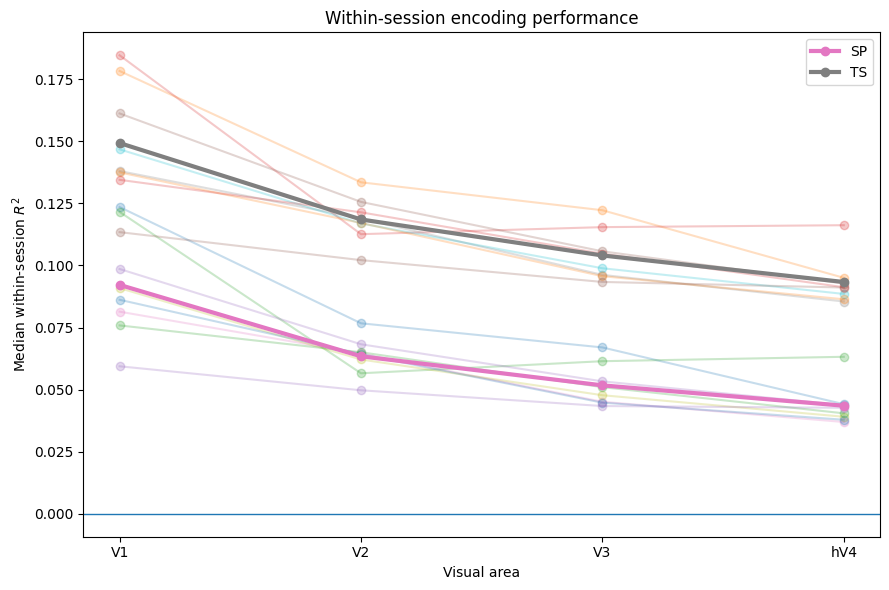

In [9]:
# =============================================================================
# FIGURE 1 — WITHIN-SESSION R2
# =============================================================================

roi_x = np.arange(
    len(ROIS)
)

plt.figure(
    figsize=(9, 6)
)

for subject in SUBJECTS:

    sub = (
        summary_df[
            summary_df["subject"] == subject
        ]
        .set_index("roi")
        .reindex(ROIS)
    )

    plt.plot(
        roi_x,
        sub["SP_R2"],
        marker="o",
        alpha=0.25
    )

    plt.plot(
        roi_x,
        sub["TS_R2"],
        marker="o",
        alpha=0.25
    )


group_summary = (
    summary_df
    .groupby("roi")
    .mean(numeric_only=True)
    .reindex(ROIS)
)


plt.plot(
    roi_x,
    group_summary["SP_R2"],
    marker="o",
    linewidth=3,
    label="SP"
)

plt.plot(
    roi_x,
    group_summary["TS_R2"],
    marker="o",
    linewidth=3,
    label="TS"
)

plt.axhline(
    0,
    linewidth=1
)

plt.xticks(
    roi_x,
    ROIS
)

plt.xlabel(
    "Visual area"
)

plt.ylabel(
    "Median within-session $R^2$"
)

plt.title(
    "Within-session encoding performance"
)

plt.legend()

plt.tight_layout()
plt.show()

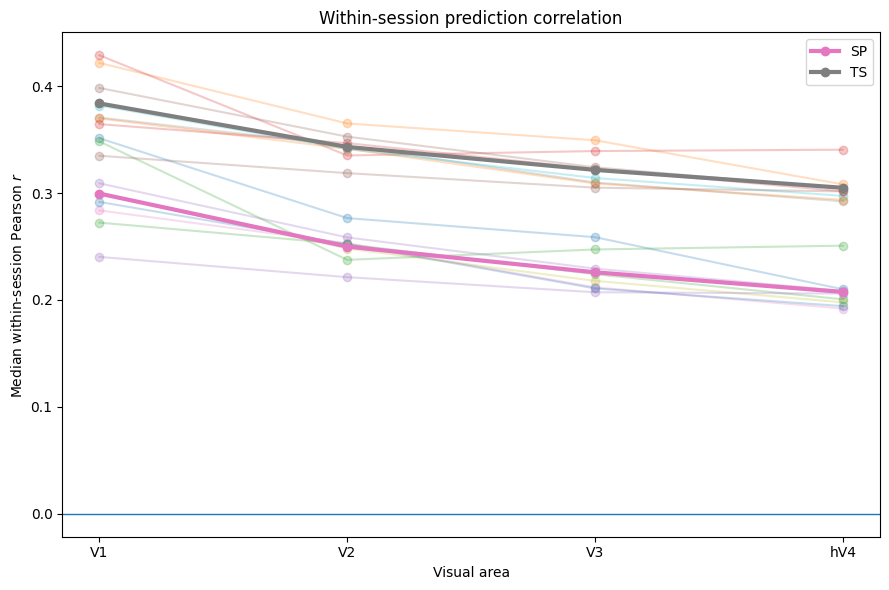

In [10]:
# =============================================================================
# FIGURE 2 — WITHIN-SESSION PEARSON
# =============================================================================

plt.figure(
    figsize=(9, 6)
)

for subject in SUBJECTS:

    sub = (
        summary_df[
            summary_df["subject"] == subject
        ]
        .set_index("roi")
        .reindex(ROIS)
    )

    plt.plot(
        roi_x,
        sub["SP_Pearson"],
        marker="o",
        alpha=0.25
    )

    plt.plot(
        roi_x,
        sub["TS_Pearson"],
        marker="o",
        alpha=0.25
    )


plt.plot(
    roi_x,
    group_summary["SP_Pearson"],
    marker="o",
    linewidth=3,
    label="SP"
)

plt.plot(
    roi_x,
    group_summary["TS_Pearson"],
    marker="o",
    linewidth=3,
    label="TS"
)

plt.axhline(
    0,
    linewidth=1
)

plt.xticks(
    roi_x,
    ROIS
)

plt.xlabel(
    "Visual area"
)

plt.ylabel(
    "Median within-session Pearson $r$"
)

plt.title(
    "Within-session prediction correlation"
)

plt.legend()

plt.tight_layout()
plt.show()

In [11]:
# =============================================================================
# GROUP SUMMARY
# =============================================================================

group_table = (
    summary_df
    .groupby("roi")
    [
        [
            "SP_R2",
            "TS_R2",
            "TS_minus_SP_R2",
            "SP_Pearson",
            "TS_Pearson",
            "TS_minus_SP_Pearson"
        ]
    ]
    .agg(
        ["mean", "std"]
    )
    .reindex(ROIS)
)

print("\n")
print("=" * 100)
print("GROUP SUMMARY — ACROSS 8 SUBJECTS")
print("=" * 100)

display(group_table)



GROUP SUMMARY — ACROSS 8 SUBJECTS


SP_R2               TS_R2           TS_minus_SP_R2            \
         mean       std      mean       std           mean       std   
roi                                                                    
V1   0.092161  0.021980  0.149272  0.023942       0.057111  0.004119   
V2   0.063408  0.007931  0.118504  0.009180       0.055096  0.001826   
V3   0.051714  0.008520  0.104014  0.010255       0.052300  0.001842   
hV4  0.043514  0.008394  0.093324  0.009772       0.049810  0.001612   

    SP_Pearson           TS_Pearson           TS_minus_SP_Pearson            
          mean       std       mean       std                mean       std  
roi                                                                          
V1    0.299530  0.037233   0.383827  0.031220            0.084297  0.007970  
V2    0.249924  0.015940   0.343150  0.013409            0.093226  0.003388  
V3    0.225894  0.018469   0.321675  0.015679            0.095781  0.003018  
hV4   0.207487  0.018686   0.304917  0.015346            0.097430  0.003698

# SP 4 levels vs SP 6 levels, across all 8 subjects × V1/V2/V3/hV4 × within-session R² and Pearson.

In [12]:
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# =============================================================================
# CONFIG
# =============================================================================

SP4_ROOT = Path(
    "/content/drive/MyDrive/V1_Drift/repDrift_expand"
)

SP6_ROOT = Path(
    "/content/drive/MyDrive/V1_Drift/repDrift_expand_6levels"
)

SUBJECTS = list(range(1, 9))
ROIS = ["V1", "V2", "V3", "hV4"]

N_SESSIONS = 30


# =============================================================================
# LOAD SUBJECT
# =============================================================================

def load_sp_subject(root, subject):

    fn = root / f"regressSessCombineROI_sub{subject}.pkl"

    if not fn.exists():
        raise FileNotFoundError(
            f"File not found:\n{fn}"
        )

    with open(fn, "rb") as f:
        data = pickle.load(f)

    return fn, data


# =============================================================================
# EXTRACT R2 WITHIN SESSION
# =============================================================================

def extract_sp_r2_within(arr, n_sessions=30):
    """
    roiNsdOriR2within

    Expected:
        (31, voxels)

    where:
        first 30 rows = sessions
        final row     = appended across-session mean/summary

    Returns:
        (30, voxels)
    """

    arr = np.asarray(arr)
    arr = np.squeeze(arr)

    if arr.ndim != 2:
        raise ValueError(
            f"Unexpected roiNsdOriR2within shape: {arr.shape}"
        )

    # sessions x voxels
    if arr.shape[0] in [n_sessions, n_sessions + 1]:

        out = arr[:n_sessions, :]

    # defensive possibility: voxels x sessions
    elif arr.shape[1] in [n_sessions, n_sessions + 1]:

        out = arr[:, :n_sessions].T

    else:

        raise ValueError(
            f"Could not identify session dimension in R2 array: {arr.shape}"
        )

    return out


# =============================================================================
# EXTRACT PEARSON WITHIN SESSION
# =============================================================================

def extract_sp_corr_within(arr, n_sessions=30):
    """
    roiNsdOriCorr observed format:

        (31, voxels, 30)

    axis 0 = train/model session (+ summary row)
    axis 1 = voxel
    axis 2 = test/evaluation session

    Within-session Pearson = diagonal across train/test sessions.

    Returns:
        (30, voxels)
    """

    arr = np.asarray(arr)
    arr = np.squeeze(arr)

    if arr.ndim != 3:
        raise ValueError(
            f"Unexpected roiNsdOriCorr shape: {arr.shape}"
        )

    if (
        arr.shape[0] in [n_sessions, n_sessions + 1]
        and
        arr.shape[2] == n_sessions
    ):

        arr = arr[:n_sessions, :, :]

        out = np.stack(
            [
                arr[s, :, s]
                for s in range(n_sessions)
            ],
            axis=0
        )

    else:

        raise ValueError(
            f"Unexpected roiNsdOriCorr dimensions: {arr.shape}"
        )

    return out


# =============================================================================
# RUN
# =============================================================================

rows = []

raw_data = {}


for subject in SUBJECTS:

    print("\n")
    print("=" * 100)
    print(f"SUBJECT {subject}")
    print("=" * 100)

    # -------------------------------------------------------------------------
    # LOAD BOTH MODELS
    # -------------------------------------------------------------------------

    sp4_file, sp4 = load_sp_subject(
        SP4_ROOT,
        subject
    )

    sp6_file, sp6 = load_sp_subject(
        SP6_ROOT,
        subject
    )

    print("4 levels:", sp4_file)
    print("6 levels:", sp6_file)


    # -------------------------------------------------------------------------
    # CHECK COMBINED ROI STRUCTURE
    # -------------------------------------------------------------------------

    n4_r2 = len(
        sp4["roiNsdOriR2within"]
    )

    n4_cc = len(
        sp4["roiNsdOriCorr"]
    )

    n6_r2 = len(
        sp6["roiNsdOriR2within"]
    )

    n6_cc = len(
        sp6["roiNsdOriCorr"]
    )

    print(
        f"4-level ROI entries: R2={n4_r2}, Pearson={n4_cc}"
    )

    print(
        f"6-level ROI entries: R2={n6_r2}, Pearson={n6_cc}"
    )

    if not (
        n4_r2 == 4
        and n4_cc == 4
        and n6_r2 == 4
        and n6_cc == 4
    ):

        raise ValueError(
            "Expected exactly 4 combined ROI entries "
            "(V1, V2, V3, hV4)."
        )


    # =========================================================================
    # ROI LOOP
    # =========================================================================

    for roi_idx, roi in enumerate(ROIS):

        print("\n" + "-" * 80)
        print(f"S{subject:02d} — {roi}")
        print("-" * 80)


        # =====================================================================
        # 4 LEVELS — R2
        # =====================================================================

        r2_4_raw = np.asarray(
            sp4["roiNsdOriR2within"][roi_idx]
        )

        r2_4 = extract_sp_r2_within(
            r2_4_raw,
            N_SESSIONS
        )


        # =====================================================================
        # 6 LEVELS — R2
        # =====================================================================

        r2_6_raw = np.asarray(
            sp6["roiNsdOriR2within"][roi_idx]
        )

        r2_6 = extract_sp_r2_within(
            r2_6_raw,
            N_SESSIONS
        )


        # =====================================================================
        # 4 LEVELS — PEARSON
        # =====================================================================

        cc_4_raw = np.asarray(
            sp4["roiNsdOriCorr"][roi_idx]
        )

        cc_4 = extract_sp_corr_within(
            cc_4_raw,
            N_SESSIONS
        )


        # =====================================================================
        # 6 LEVELS — PEARSON
        # =====================================================================

        cc_6_raw = np.asarray(
            sp6["roiNsdOriCorr"][roi_idx]
        )

        cc_6 = extract_sp_corr_within(
            cc_6_raw,
            N_SESSIONS
        )


        # =====================================================================
        # PRINT SHAPES
        # =====================================================================

        print(
            "4-level R2:",
            r2_4.shape,
            "| 6-level R2:",
            r2_6.shape
        )

        print(
            "4-level Pearson:",
            cc_4.shape,
            "| 6-level Pearson:",
            cc_6.shape
        )


        # =====================================================================
        # IMPORTANT VOXEL COUNT CHECK
        # =====================================================================

        if r2_4.shape[1] != r2_6.shape[1]:

            print(
                f"WARNING: different voxel counts! "
                f"4-level={r2_4.shape[1]}, "
                f"6-level={r2_6.shape[1]}"
            )

        if cc_4.shape[1] != cc_6.shape[1]:

            print(
                f"WARNING Pearson voxel count differs! "
                f"4-level={cc_4.shape[1]}, "
                f"6-level={cc_6.shape[1]}"
            )


        # =====================================================================
        # STORE RAW ARRAYS
        # =====================================================================

        raw_data[(subject, roi)] = {

            "R2_4levels": r2_4,
            "R2_6levels": r2_6,

            "Pearson_4levels": cc_4,
            "Pearson_6levels": cc_6
        }


        # =====================================================================
        # SESSION LOOP
        # =====================================================================

        for sess in range(N_SESSIONS):

            r2_4_s = r2_4[sess, :]
            r2_6_s = r2_6[sess, :]

            cc_4_s = cc_4[sess, :]
            cc_6_s = cc_6[sess, :]


            rows.append({

                "subject": subject,
                "roi": roi,
                "session": sess + 1,


                # -------------------------------------------------------------
                # R2
                # -------------------------------------------------------------

                "R2_4levels_median":
                    np.nanmedian(r2_4_s),

                "R2_6levels_median":
                    np.nanmedian(r2_6_s),

                "R2_4levels_mean":
                    np.nanmean(r2_4_s),

                "R2_6levels_mean":
                    np.nanmean(r2_6_s),

                "R2_6_minus_4":
                    np.nanmedian(r2_6_s)
                    -
                    np.nanmedian(r2_4_s),


                # -------------------------------------------------------------
                # PEARSON
                # -------------------------------------------------------------

                "Pearson_4levels_median":
                    np.nanmedian(cc_4_s),

                "Pearson_6levels_median":
                    np.nanmedian(cc_6_s),

                "Pearson_4levels_mean":
                    np.nanmean(cc_4_s),

                "Pearson_6levels_mean":
                    np.nanmean(cc_6_s),

                "Pearson_6_minus_4":
                    np.nanmedian(cc_6_s)
                    -
                    np.nanmedian(cc_4_s),


                # -------------------------------------------------------------
                # FINITE COUNTS
                # -------------------------------------------------------------

                "nvox_R2_4levels":
                    np.sum(np.isfinite(r2_4_s)),

                "nvox_R2_6levels":
                    np.sum(np.isfinite(r2_6_s)),

                "nvox_Pearson_4levels":
                    np.sum(np.isfinite(cc_4_s)),

                "nvox_Pearson_6levels":
                    np.sum(np.isfinite(cc_6_s)),
            })


# =============================================================================
# SESSION-LEVEL DATAFRAME
# =============================================================================

within_df = pd.DataFrame(
    rows
)

print("\n")
print("=" * 100)
print("SESSION-LEVEL RESULTS")
print("=" * 100)

print(
    "Expected rows:",
    8 * 4 * 30
)

print(
    "Actual rows:",
    len(within_df)
)

assert len(within_df) == 8 * 4 * 30

display(within_df)



SUBJECT 1
4 levels: /content/drive/MyDrive/V1_Drift/repDrift_expand/regressSessCombineROI_sub1.pkl
6 levels: /content/drive/MyDrive/V1_Drift/repDrift_expand_6levels/regressSessCombineROI_sub1.pkl
4-level ROI entries: R2=4, Pearson=4
6-level ROI entries: R2=4, Pearson=4

--------------------------------------------------------------------------------
S01 — V1
--------------------------------------------------------------------------------
4-level R2: (30, 1350) | 6-level R2: (30, 1350)
4-level Pearson: (30, 1350) | 6-level Pearson: (30, 1350)

--------------------------------------------------------------------------------
S01 — V2
--------------------------------------------------------------------------------
4-level R2: (30, 1433) | 6-level R2: (30, 1433)
4-level Pearson: (30, 1433) | 6-level Pearson: (30, 1433)

--------------------------------------------------------------------------------
S01 — V3
--------------------------------------------------------------------------------


,subject,roi,session,R2_4levels_median,R2_6levels_median,R2_4levels_mean,R2_6levels_mean,R2_6_minus_4,Pearson_4levels_median,Pearson_6levels_median,Pearson_4levels_mean,Pearson_6levels_mean,Pearson_6_minus_4,nvox_R2_4levels,nvox_R2_6levels,nvox_Pearson_4levels,nvox_Pearson_6levels
0,1,V1,1,0.134795,0.127920,0.143714,0.138312,-0.006876,0.367487,0.358260,0.360900,0.357555,-0.009227,1350,1350,1345,1345
1,1,V1,2,0.118202,0.116863,0.131602,0.128742,-0.001339,0.344166,0.342120,0.346287,0.346142,-0.002046,1350,1350,1345,1345
2,1,V1,3,0.125352,0.122738,0.140846,0.138293,-0.002614,0.354246,0.350600,0.355555,0.356954,-0.003646,1350,1350,1345,1345
3,1,V1,4,0.131989,0.125453,0.143021,0.137826,-0.006537,0.364258,0.354433,0.359597,0.356492,-0.009825,1350,1350,1345,1345
4,1,V1,5,0.109875,0.104830,0.121884,0.119268,-0.005045,0.332058,0.324240,0.333565,0.333007,-0.007818,1350,1350,1345,1345
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
955,8,hV4,26,0.044805,0.056075,0.051985,0.063127,0.011270,0.211671,0.236802,0.219657,0.244876,0.025131,495,495,495,495
956,8,hV4,27,0.039650,0.052339,0.050239,0.063325,0.012689,0.199123,0.228777,0.214394,0.243526,0.029654,495,495,495,495
957,8,hV4,28,0.040227,0.052678,0.044743,0.057298,0.012451,0.200567,0.229516,0.205157,0.234192,0.028949,495,495,495,495
958,8,hV4,29,0.037062,0.049305,0.043645,0.055688,0.012243,0.192515,0.222047,0.200859,0.229047,0.029532,495,495,495,495


In [13]:
# =============================================================================
# SUBJECT × ROI SUMMARY
# =============================================================================

summary_df = (
    within_df
    .groupby(
        ["subject", "roi"],
        as_index=False
    )
    .agg(

        R2_4levels=(
            "R2_4levels_median",
            "mean"
        ),

        R2_6levels=(
            "R2_6levels_median",
            "mean"
        ),

        Pearson_4levels=(
            "Pearson_4levels_median",
            "mean"
        ),

        Pearson_6levels=(
            "Pearson_6levels_median",
            "mean"
        )
    )
)


summary_df["R2_6_minus_4"] = (
    summary_df["R2_6levels"]
    -
    summary_df["R2_4levels"]
)

summary_df["Pearson_6_minus_4"] = (
    summary_df["Pearson_6levels"]
    -
    summary_df["Pearson_4levels"]
)


print("\n")
print("=" * 100)
print("SUBJECT × ROI SUMMARY")
print("Mean across 30 session-wise voxel medians")
print("=" * 100)

display(summary_df)



SUBJECT × ROI SUMMARY
Mean across 30 session-wise voxel medians


,subject,roi,R2_4levels,R2_6levels,Pearson_4levels,Pearson_6levels,R2_6_minus_4,Pearson_6_minus_4
0,1,V1,0.123509,0.119839,0.351270,0.346000,-0.003670,-0.005270
1,1,V2,0.076694,0.085662,0.276592,0.292441,0.008968,0.015849
2,1,V3,0.066983,0.077381,0.258738,0.278199,0.010398,0.019461
3,1,hV4,0.044146,0.056026,0.210013,0.236709,0.011880,0.026697
4,2,V1,0.121557,0.124420,0.348280,0.352642,0.002862,0.004361
5,2,V2,0.056576,0.067458,0.237526,0.259557,0.010882,0.022032
6,2,V3,0.061440,0.072658,0.247252,0.269138,0.011219,0.021886
7,2,hV4,0.063212,0.074325,0.250797,0.272160,0.011113,0.021364
8,3,V1,0.098566,0.104191,0.309132,0.319386,0.005625,0.010253
9,3,V2,0.068254,0.078084,0.258516,0.277535,0.009830,0.019018


In [14]:
# =============================================================================
# MATRICES
# =============================================================================

def show_matrix(value, title):

    table = (
        summary_df
        .pivot(
            index="subject",
            columns="roi",
            values=value
        )
        .reindex(
            columns=ROIS
        )
    )

    print("\n" + "=" * 80)
    print(title)
    print("=" * 80)

    display(table)

    return table


# R2
r2_4_table = show_matrix(
    "R2_4levels",
    "SP 4 LEVELS — WITHIN-SESSION R²"
)

r2_6_table = show_matrix(
    "R2_6levels",
    "SP 6 LEVELS — WITHIN-SESSION R²"
)

r2_diff_table = show_matrix(
    "R2_6_minus_4",
    "SP 6 LEVELS - 4 LEVELS — WITHIN-SESSION R²"
)


# PEARSON
cc_4_table = show_matrix(
    "Pearson_4levels",
    "SP 4 LEVELS — WITHIN-SESSION PEARSON"
)

cc_6_table = show_matrix(
    "Pearson_6levels",
    "SP 6 LEVELS — WITHIN-SESSION PEARSON"
)

cc_diff_table = show_matrix(
    "Pearson_6_minus_4",
    "SP 6 LEVELS - 4 LEVELS — WITHIN-SESSION PEARSON"
)


SP 4 LEVELS — WITHIN-SESSION R²


roi,V1,V2,V3,hV4
subject,,,,
1,0.123509,0.076694,0.066983,0.044146
2,0.121557,0.056576,0.061440,0.063212
3,0.098566,0.068254,0.053319,0.043734
4,0.081383,0.064558,0.045104,0.036952
5,0.090865,0.062124,0.047742,0.039074
6,0.086169,0.064290,0.044747,0.037865
7,0.075847,0.065039,0.050992,0.040455
8,0.059389,0.049726,0.043387,0.042678



SP 6 LEVELS — WITHIN-SESSION R²


roi,V1,V2,V3,hV4
subject,,,,
1,0.119839,0.085662,0.077381,0.056026
2,0.124420,0.067458,0.072658,0.074325
3,0.104191,0.078084,0.064605,0.055799
4,0.090217,0.074946,0.056585,0.048906
5,0.101251,0.073899,0.059868,0.051994
6,0.094023,0.074774,0.056358,0.049404
7,0.082794,0.074758,0.062329,0.051986
8,0.069348,0.060456,0.055068,0.053919



SP 6 LEVELS - 4 LEVELS — WITHIN-SESSION R²


...

roi,V1,V2,V3,hV4
subject,,,,
1,0.351270,0.276592,0.258738,0.210013
2,0.348280,0.237526,0.247252,0.250797
3,0.309132,0.258516,0.229331,0.208531
4,0.283754,0.252982,0.211807,0.191959
5,0.299451,0.248138,0.217897,0.197737
6,0.291706,0.252127,0.210828,0.194241
7,0.272361,0.252179,0.224063,0.200626
8,0.240285,0.221334,0.207233,0.205991



SP 6 LEVELS — WITHIN-SESSION PEARSON


roi,V1,V2,V3,hV4
subject,,,,
1,0.346000,0.292441,0.278199,0.236709
2,0.352642,0.259557,0.269138,0.272160
3,0.319386,0.277535,0.253201,0.235868
4,0.299229,0.272977,0.237512,0.220921
5,0.316806,0.271230,0.244255,0.228160
6,0.305309,0.272455,0.236903,0.222093
7,0.285731,0.271365,0.248420,0.227779
8,0.261245,0.244911,0.233967,0.231789



SP 6 LEVELS - 4 LEVELS — WITHIN-SESSION PEARSON


roi,V1,V2,V3,hV4
subject,,,,
1,-0.005270,0.015849,0.019461,0.026697
2,0.004361,0.022032,0.021886,0.021364
3,0.010253,0.019018,0.023870,0.027337
4,0.015475,0.019996,0.025705,0.028962
5,0.017355,0.023093,0.026358,0.030423
6,0.013603,0.020328,0.026075,0.027852
7,0.013369,0.019186,0.024357,0.027153
8,0.020960,0.023577,0.026734,0.025798


In [15]:
# =============================================================================
# GROUP MEANS
# =============================================================================

group_summary = (
    summary_df
    .groupby("roi")
    .mean(numeric_only=True)
    .reindex(ROIS)
)

roi_x = np.arange(
    len(ROIS)
)

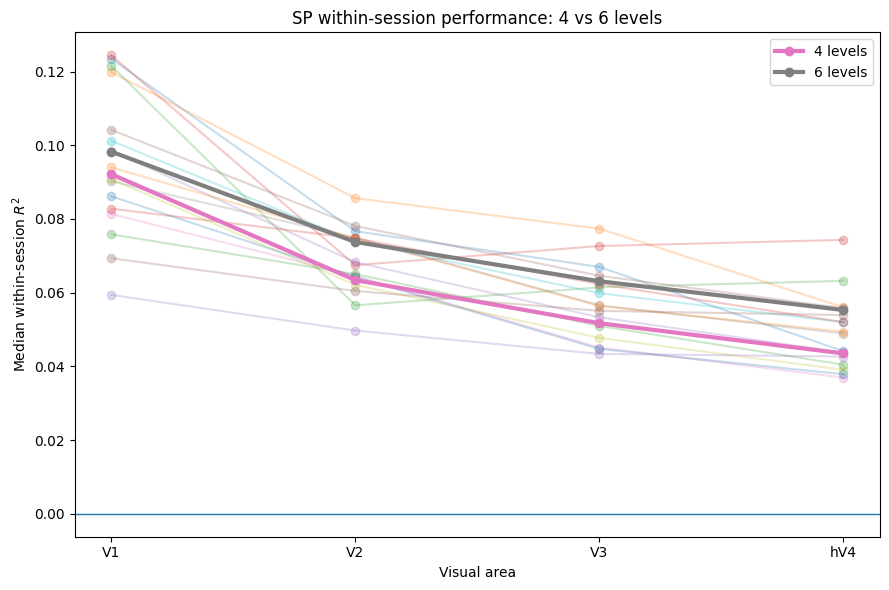

In [18]:
plt.figure(
    figsize=(9, 6)
)

# individual subjects
for subject in SUBJECTS:

    sub = (
        summary_df[
            summary_df["subject"] == subject
        ]
        .set_index("roi")
        .reindex(ROIS)
    )

    plt.plot(
        roi_x,
        sub["R2_4levels"],
        marker="o",
        alpha=0.25
    )

    plt.plot(
        roi_x,
        sub["R2_6levels"],
        marker="o",
        alpha=0.25
    )


# group means
plt.plot(
    roi_x,
    group_summary["R2_4levels"],
    marker="o",
    linewidth=3,
    label="4 levels"
)

plt.plot(
    roi_x,
    group_summary["R2_6levels"],
    marker="o",
    linewidth=3,
    label="6 levels"
)

plt.axhline(
    0,
    linewidth=1
)

plt.xticks(
    roi_x,
    ROIS
)

plt.xlabel(
    "Visual area"
)

plt.ylabel(
    "Median within-session $R^2$"
)

plt.title(
    "SP within-session performance: 4 vs 6 levels"
)

plt.legend()

plt.tight_layout()
plt.show()

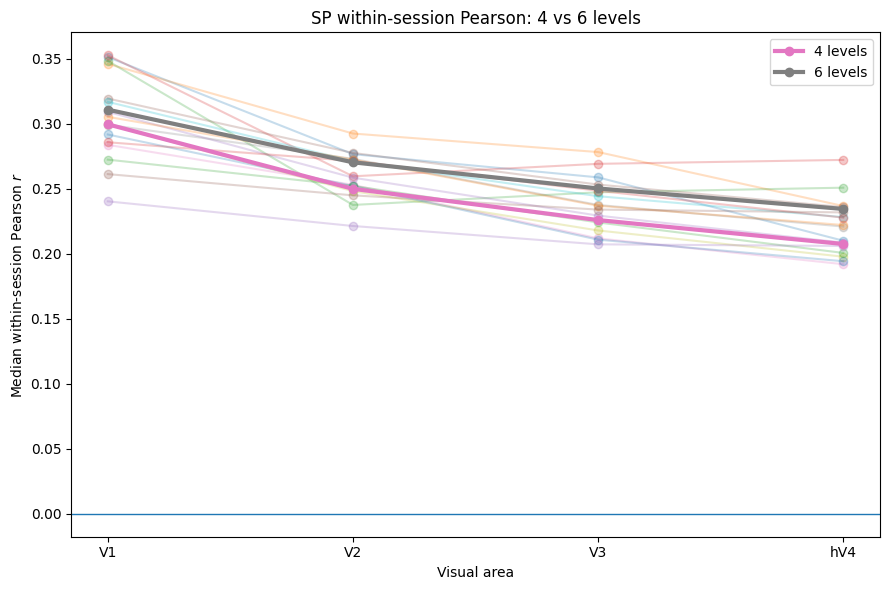

In [16]:
plt.figure(
    figsize=(9, 6)
)

for subject in SUBJECTS:

    sub = (
        summary_df[
            summary_df["subject"] == subject
        ]
        .set_index("roi")
        .reindex(ROIS)
    )

    plt.plot(
        roi_x,
        sub["Pearson_4levels"],
        marker="o",
        alpha=0.25
    )

    plt.plot(
        roi_x,
        sub["Pearson_6levels"],
        marker="o",
        alpha=0.25
    )


plt.plot(
    roi_x,
    group_summary["Pearson_4levels"],
    marker="o",
    linewidth=3,
    label="4 levels"
)

plt.plot(
    roi_x,
    group_summary["Pearson_6levels"],
    marker="o",
    linewidth=3,
    label="6 levels"
)

plt.axhline(
    0,
    linewidth=1
)

plt.xticks(
    roi_x,
    ROIS
)

plt.xlabel(
    "Visual area"
)

plt.ylabel(
    "Median within-session Pearson $r$"
)

plt.title(
    "SP within-session Pearson: 4 vs 6 levels"
)

plt.legend()

plt.tight_layout()
plt.show()

In [17]:
# =============================================================================
# GROUP SUMMARY ACROSS SUBJECTS
# =============================================================================

group_table = (
    summary_df
    .groupby("roi")
    [
        [
            "R2_4levels",
            "R2_6levels",
            "R2_6_minus_4",
            "Pearson_4levels",
            "Pearson_6levels",
            "Pearson_6_minus_4"
        ]
    ]
    .agg(
        ["mean", "std"]
    )
    .reindex(ROIS)
)

print("\n")
print("=" * 100)
print("GROUP SUMMARY — 4 LEVELS VS 6 LEVELS")
print("=" * 100)

display(group_table)



GROUP SUMMARY — 4 LEVELS VS 6 LEVELS


R2_4levels           R2_6levels           R2_6_minus_4            \
          mean       std       mean       std         mean       std   
roi                                                                    
V1    0.092161  0.021980   0.098260  0.018330     0.006100  0.004640   
V2    0.063408  0.007931   0.073755  0.007373     0.010347  0.000850   
V3    0.051714  0.008520   0.063106  0.008116     0.011392  0.000494   
hV4   0.043514  0.008394   0.055295  0.008126     0.011780  0.000570   

    Pearson_4levels           Pearson_6levels           Pearson_6_minus_4  \
               mean       std            mean       std              mean   
roi                                                                         
V1         0.299530  0.037233        0.310793  0.030114          0.011263   
V2         0.249924  0.015940        0.270309  0.013713          0.020385   
V3         0.225894  0.018469        0.250199  0.015997          0.024306   
hV4        0.207487  0.018686        0.234435  0.016284          0.026948   

               
          std  
roi            
V1   0.008288  
V2   0.002515  
V3   0.002528  
hV4  0.002665

# Compare TS model pca0 vspca95

In [74]:
from pathlib import Path
import h5py
import numpy as np
import pandas as pd


# =============================================================================
# CONFIG
# =============================================================================

TS_ROOT = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits"
)

SUBJECTS = list(range(1, 9))
ROIS = ["V1", "V2", "V3", "hV4"]

N_SESSIONS = 30


# =============================================================================
# FIND TS FILE
# =============================================================================

def get_ts_file(subject, roi, pca_pct_var):

    subject_name = f"S{subject:02d}"

    folder = (
        TS_ROOT
        / subject_name
        / "FAST_CROSS_SESSION"
    )

    exact_name = (
        f"{subject_name}_{roi}_"
        f"texture_pyramid_OLS_4ori_4sf_"
        f"pcaHL_{roi}_pca{pca_pct_var}_"
        f"use_nsd_grid5_pRFs_"
        f"30x30_cross_session.h5py"
    )

    fn = folder / exact_name

    if fn.exists():
        return fn

    # -------------------------------------------------------------------------
    # fallback search
    # -------------------------------------------------------------------------

    candidates = list(
        folder.glob(
            f"*{roi}*pcaHL*{roi}*pca{pca_pct_var}*"
            f"30x30_cross_session.h5py"
        )
    )

    if len(candidates) == 1:
        return candidates[0]

    elif len(candidates) == 0:
        raise FileNotFoundError(
            f"No TS pca{pca_pct_var} file found "
            f"for S{subject:02d} {roi}\n"
            f"Expected:\n{fn}"
        )

    else:
        raise RuntimeError(
            f"Multiple TS pca{pca_pct_var} files found "
            f"for S{subject:02d} {roi}:\n"
            + "\n".join(str(x) for x in candidates)
        )


# =============================================================================
# EXTRACT WITHIN-SESSION DIAGONAL
# =============================================================================

def extract_ts_diagonal(arr, n_sessions=30):
    """
    TS val_r2 / val_cc structure:

        train_session x test_session x voxel

    or

        train_session x test_session x voxel x model

    Returns:
        (30, voxels)
    """

    arr = np.asarray(arr)

    # Remove final singleton model dimension
    if arr.ndim == 4:
        arr = arr[..., 0]

    arr = np.squeeze(arr)

    if arr.ndim != 3:
        raise ValueError(
            f"Unexpected TS array shape: {arr.shape}"
        )

    if (
        arr.shape[0] < n_sessions
        or arr.shape[1] < n_sessions
    ):
        raise ValueError(
            f"Array does not contain "
            f"{n_sessions}x{n_sessions} sessions: "
            f"{arr.shape}"
        )

    out = np.stack(
        [
            arr[s, s, :]
            for s in range(n_sessions)
        ],
        axis=0
    )

    return out


# =============================================================================
# RUN
# =============================================================================

rows = []

raw_data = {}


for subject in SUBJECTS:

    print("\n")
    print("=" * 100)
    print(f"SUBJECT {subject}")
    print("=" * 100)

    for roi in ROIS:

        print("\n" + "-" * 80)
        print(f"S{subject:02d} — {roi}")
        print("-" * 80)


        # =====================================================================
        # FIND BOTH FILES
        # =====================================================================

        pca0_file = get_ts_file(
            subject,
            roi,
            pca_pct_var=0
        )

        pca95_file = get_ts_file(
            subject,
            roi,
            pca_pct_var=95
        )

        print("pcaHL0 :", pca0_file.name)
        print("pcaHL95:", pca95_file.name)


        # =====================================================================
        # LOAD PCA0
        # =====================================================================

        with h5py.File(pca0_file, "r") as f:

            r2_0_raw = np.asarray(
                f["val_r2"]
            )

            cc_0_raw = np.asarray(
                f["val_cc"]
            )

            voxel_index_0 = np.asarray(
                f["voxel_index"]
            ).squeeze().astype(int)


        # =====================================================================
        # LOAD PCA95
        # =====================================================================

        with h5py.File(pca95_file, "r") as f:

            r2_95_raw = np.asarray(
                f["val_r2"]
            )

            cc_95_raw = np.asarray(
                f["val_cc"]
            )

            voxel_index_95 = np.asarray(
                f["voxel_index"]
            ).squeeze().astype(int)


        # =====================================================================
        # EXTRACT DIAGONALS
        # =====================================================================

        r2_0 = extract_ts_diagonal(
            r2_0_raw,
            N_SESSIONS
        )

        cc_0 = extract_ts_diagonal(
            cc_0_raw,
            N_SESSIONS
        )

        r2_95 = extract_ts_diagonal(
            r2_95_raw,
            N_SESSIONS
        )

        cc_95 = extract_ts_diagonal(
            cc_95_raw,
            N_SESSIONS
        )


        # =====================================================================
        # PRINT SHAPES
        # =====================================================================

        print(
            "pcaHL0 R2:",
            r2_0.shape,
            "| pcaHL95 R2:",
            r2_95.shape
        )

        print(
            "pcaHL0 Pearson:",
            cc_0.shape,
            "| pcaHL95 Pearson:",
            cc_95.shape
        )


        # =====================================================================
        # IMPORTANT VOXEL ALIGNMENT CHECK
        # =====================================================================

        print(
            "Voxel counts:",
            len(voxel_index_0),
            len(voxel_index_95)
        )

        same_order = np.array_equal(
            voxel_index_0,
            voxel_index_95
        )

        same_set = np.array_equal(
            np.sort(voxel_index_0),
            np.sort(voxel_index_95)
        )

        print(
            "Exact voxel order:",
            same_order
        )

        print(
            "Same voxel set:",
            same_set
        )


        # =====================================================================
        # REORDER PCA0 IF NEEDED
        # =====================================================================

        if not same_order:

            if not same_set:

                raise ValueError(
                    f"S{subject:02d} {roi}: "
                    "pca0 and pca95 do not contain the same voxel set."
                )

            lookup_0 = {
                voxel: i
                for i, voxel in enumerate(voxel_index_0)
            }

            reorder = np.asarray(
                [
                    lookup_0[v]
                    for v in voxel_index_95
                ]
            )

            r2_0 = r2_0[:, reorder]
            cc_0 = cc_0[:, reorder]

            voxel_index_0 = voxel_index_0[reorder]

            assert np.array_equal(
                voxel_index_0,
                voxel_index_95
            )

            print(
                "pcaHL0 reordered to match pcaHL95."
            )


        # =====================================================================
        # FINAL SHAPE CHECK
        # =====================================================================

        if r2_0.shape != r2_95.shape:
            raise ValueError(
                f"R2 shape mismatch: "
                f"{r2_0.shape} vs {r2_95.shape}"
            )

        if cc_0.shape != cc_95.shape:
            raise ValueError(
                f"Pearson shape mismatch: "
                f"{cc_0.shape} vs {cc_95.shape}"
            )


        # =====================================================================
        # STORE RAW ARRAYS
        # =====================================================================

        raw_data[(subject, roi)] = {

            "R2_pca0": r2_0,
            "R2_pca95": r2_95,

            "Pearson_pca0": cc_0,
            "Pearson_pca95": cc_95,

            "voxel_index": voxel_index_95,

            "pca0_file": str(pca0_file),
            "pca95_file": str(pca95_file),
        }


        # =====================================================================
        # SESSION LOOP
        # =====================================================================

        for sess in range(N_SESSIONS):

            r2_0_s = r2_0[sess, :]
            r2_95_s = r2_95[sess, :]

            cc_0_s = cc_0[sess, :]
            cc_95_s = cc_95[sess, :]


            rows.append({

                "subject": subject,
                "roi": roi,
                "session": sess + 1,


                # -------------------------------------------------------------
                # R2
                # -------------------------------------------------------------

                "R2_pca0_median":
                    np.nanmedian(r2_0_s),

                "R2_pca95_median":
                    np.nanmedian(r2_95_s),

                "R2_pca0_mean":
                    np.nanmean(r2_0_s),

                "R2_pca95_mean":
                    np.nanmean(r2_95_s),

                "R2_pca95_minus_pca0":
                    np.nanmedian(r2_95_s)
                    -
                    np.nanmedian(r2_0_s),


                # -------------------------------------------------------------
                # PEARSON
                # -------------------------------------------------------------

                "Pearson_pca0_median":
                    np.nanmedian(cc_0_s),

                "Pearson_pca95_median":
                    np.nanmedian(cc_95_s),

                "Pearson_pca0_mean":
                    np.nanmean(cc_0_s),

                "Pearson_pca95_mean":
                    np.nanmean(cc_95_s),

                "Pearson_pca95_minus_pca0":
                    np.nanmedian(cc_95_s)
                    -
                    np.nanmedian(cc_0_s),


                # -------------------------------------------------------------
                # FINITE COUNTS
                # -------------------------------------------------------------

                "nvox_R2_pca0":
                    np.sum(np.isfinite(r2_0_s)),

                "nvox_R2_pca95":
                    np.sum(np.isfinite(r2_95_s)),

                "nvox_Pearson_pca0":
                    np.sum(np.isfinite(cc_0_s)),

                "nvox_Pearson_pca95":
                    np.sum(np.isfinite(cc_95_s)),
            })


# =============================================================================
# SESSION-LEVEL DATAFRAME
# =============================================================================

within_pca_df = pd.DataFrame(
    rows
)

print("\n")
print("=" * 100)
print("PCA0 VS PCA95 — SESSION-LEVEL RESULTS")
print("=" * 100)

print(
    "Expected rows:",
    8 * 4 * 30
)

print(
    "Actual rows:",
    len(within_pca_df)
)

assert len(within_pca_df) == 8 * 4 * 30

display(within_pca_df)



SUBJECT 1

--------------------------------------------------------------------------------
S01 — V1
--------------------------------------------------------------------------------
pcaHL0 : S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca0_use_nsd_grid5_pRFs_30x30_cross_session.h5py
pcaHL95: S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py
pcaHL0 R2: (30, 1350) | pcaHL95 R2: (30, 1350)
pcaHL0 Pearson: (30, 1350) | pcaHL95 Pearson: (30, 1350)
Voxel counts: 1350 1350
Exact voxel order: True
Same voxel set: True

--------------------------------------------------------------------------------
S01 — V2
--------------------------------------------------------------------------------
pcaHL0 : S01_V2_texture_pyramid_OLS_4ori_4sf_pcaHL_V2_pca0_use_nsd_grid5_pRFs_30x30_cross_session.h5py
pcaHL95: S01_V2_texture_pyramid_OLS_4ori_4sf_pcaHL_V2_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py
pcaHL0 R2: (30, 1433) | pcaHL95 R2: (30, 1433)
pcaHL0 Pea

,subject,roi,session,R2_pca0_median,R2_pca95_median,R2_pca0_mean,R2_pca95_mean,R2_pca95_minus_pca0,Pearson_pca0_median,Pearson_pca95_median,Pearson_pca0_mean,Pearson_pca95_mean,Pearson_pca95_minus_pca0,nvox_R2_pca0,nvox_R2_pca95,nvox_Pearson_pca0,nvox_Pearson_pca95
0,1,V1,1,0.186834,0.191548,0.193057,0.197295,0.004715,0.432242,0.437662,0.427880,0.432928,0.005420,1350,1350,1350,1350
1,1,V1,2,0.174298,0.179036,0.183713,0.188354,0.004739,0.417489,0.423127,0.417815,0.423387,0.005637,1350,1350,1350,1350
2,1,V1,3,0.174936,0.179197,0.190031,0.194305,0.004261,0.418253,0.423316,0.423176,0.428311,0.005063,1350,1350,1350,1350
3,1,V1,4,0.178815,0.183369,0.189924,0.193852,0.004554,0.422865,0.428216,0.423885,0.428623,0.005351,1350,1350,1350,1350
4,1,V1,5,0.162259,0.165522,0.172326,0.176340,0.003263,0.402814,0.406844,0.405680,0.410761,0.004031,1350,1350,1350,1350
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
955,8,hV4,26,0.087091,0.091358,0.092547,0.095886,0.004267,0.295111,0.302254,0.300530,0.306061,0.007143,495,495,495,495
956,8,hV4,27,0.087302,0.090147,0.094192,0.097616,0.002845,0.295470,0.300245,0.302492,0.308096,0.004775,495,495,495,495
957,8,hV4,28,0.082460,0.086146,0.088478,0.091903,0.003686,0.287159,0.293507,0.294359,0.300112,0.006348,495,495,495,495
958,8,hV4,29,0.082121,0.084764,0.086289,0.089428,0.002643,0.286567,0.291143,0.290384,0.295751,0.004576,495,495,495,495


In [75]:
# =============================================================================
# SUBJECT × ROI SUMMARY
# =============================================================================

summary_pca_df = (
    within_pca_df
    .groupby(
        ["subject", "roi"],
        as_index=False
    )
    .agg(

        R2_pca0=(
            "R2_pca0_median",
            "mean"
        ),

        R2_pca95=(
            "R2_pca95_median",
            "mean"
        ),

        Pearson_pca0=(
            "Pearson_pca0_median",
            "mean"
        ),

        Pearson_pca95=(
            "Pearson_pca95_median",
            "mean"
        )
    )
)


summary_pca_df["R2_pca95_minus_pca0"] = (
    summary_pca_df["R2_pca95"]
    -
    summary_pca_df["R2_pca0"]
)

summary_pca_df["Pearson_pca95_minus_pca0"] = (
    summary_pca_df["Pearson_pca95"]
    -
    summary_pca_df["Pearson_pca0"]
)


print("\n")
print("=" * 100)
print("SUBJECT × ROI SUMMARY")
print("Mean across 30 session-wise voxel medians")
print("=" * 100)

display(summary_pca_df)



SUBJECT × ROI SUMMARY
Mean across 30 session-wise voxel medians


,subject,roi,R2_pca0,R2_pca95,Pearson_pca0,Pearson_pca95,R2_pca95_minus_pca0,Pearson_pca95_minus_pca0
0,1,V1,0.174028,0.178295,0.416664,0.421755,0.004267,0.005092
1,1,V2,0.129454,0.133466,0.359540,0.365089,0.004012,0.005549
2,1,V3,0.118486,0.122224,0.344014,0.349400,0.003738,0.005386
3,1,hV4,0.091473,0.095011,0.302357,0.308159,0.003538,0.005802
4,2,V1,0.180439,0.184618,0.424002,0.428894,0.004178,0.004893
5,2,V2,0.108647,0.112582,0.329221,0.335145,0.003935,0.005924
6,2,V3,0.111868,0.115417,0.334011,0.339295,0.003549,0.005284
7,2,hV4,0.112452,0.116190,0.335024,0.340574,0.003738,0.005551
8,3,V1,0.156937,0.161193,0.392859,0.398317,0.004256,0.005458
9,3,V2,0.121533,0.125575,0.346916,0.352745,0.004042,0.005829


In [76]:
# =============================================================================
# MATRICES
# =============================================================================

def show_pca_matrix(value, title):

    table = (
        summary_pca_df
        .pivot(
            index="subject",
            columns="roi",
            values=value
        )
        .reindex(
            columns=ROIS
        )
    )

    print("\n" + "=" * 80)
    print(title)
    print("=" * 80)

    display(table)

    return table


# R2
r2_pca0_table = show_pca_matrix(
    "R2_pca0",
    "TS pcaHL0 — WITHIN-SESSION R²"
)

r2_pca95_table = show_pca_matrix(
    "R2_pca95",
    "TS pcaHL95 — WITHIN-SESSION R²"
)

r2_pca_diff_table = show_pca_matrix(
    "R2_pca95_minus_pca0",
    "TS pcaHL95 - pcaHL0 — WITHIN-SESSION R²"
)


# PEARSON
cc_pca0_table = show_pca_matrix(
    "Pearson_pca0",
    "TS pcaHL0 — WITHIN-SESSION PEARSON"
)

cc_pca95_table = show_pca_matrix(
    "Pearson_pca95",
    "TS pcaHL95 — WITHIN-SESSION PEARSON"
)

cc_pca_diff_table = show_pca_matrix(
    "Pearson_pca95_minus_pca0",
    "TS pcaHL95 - pcaHL0 — WITHIN-SESSION PEARSON"
)


TS pcaHL0 — WITHIN-SESSION R²


roi,V1,V2,V3,hV4
subject,,,,
1,0.174028,0.129454,0.118486,0.091473
2,0.180439,0.108647,0.111868,0.112452
3,0.156937,0.121533,0.102015,0.089175
4,0.134176,0.115043,0.092592,0.082003
5,0.142761,0.112923,0.095307,0.085128
6,0.133738,0.113501,0.092073,0.082934
7,0.130770,0.117633,0.100784,0.087681
8,0.109639,0.098591,0.089861,0.087747



TS pcaHL95 — WITHIN-SESSION R²


roi,V1,V2,V3,hV4
subject,,,,
1,0.178295,0.133466,0.122224,0.095011
2,0.184618,0.112582,0.115417,0.116190
3,0.161193,0.125575,0.105680,0.092699
4,0.138008,0.118880,0.096191,0.085472
5,0.146735,0.116922,0.098857,0.088522
6,0.137461,0.117087,0.095665,0.086375
7,0.134466,0.121386,0.104726,0.091223
8,0.113400,0.102134,0.093351,0.091101



TS pcaHL95 - pcaHL0 — WITHIN-SESSION R²


...

roi,V1,V2,V3,hV4
subject,,,,
1,0.416664,0.359540,0.344014,0.302357
2,0.424002,0.329221,0.334011,0.335024
3,0.392859,0.346916,0.318402,0.298260
4,0.365398,0.338574,0.303998,0.286239
5,0.376597,0.335274,0.308365,0.291596
6,0.364707,0.336146,0.303093,0.287782
7,0.359299,0.341242,0.316381,0.295683
8,0.329179,0.312995,0.299265,0.295942



TS pcaHL95 — WITHIN-SESSION PEARSON


roi,V1,V2,V3,hV4
subject,,,,
1,0.421755,0.365089,0.349400,0.308159
2,0.428894,0.335145,0.339295,0.340574
3,0.398317,0.352745,0.324137,0.304125
4,0.370614,0.344199,0.309875,0.292239
5,0.381858,0.341226,0.314089,0.297356
6,0.369793,0.341445,0.308962,0.293695
7,0.364478,0.346714,0.322586,0.301634
8,0.334904,0.318641,0.305053,0.301555



TS pcaHL95 - pcaHL0 — WITHIN-SESSION PEARSON


roi,V1,V2,V3,hV4
subject,,,,
1,0.005092,0.005549,0.005386,0.005802
2,0.004893,0.005924,0.005284,0.005551
3,0.005458,0.005829,0.005735,0.005864
4,0.005216,0.005624,0.005876,0.006000
5,0.005262,0.005952,0.005724,0.005760
6,0.005087,0.005299,0.005869,0.005913
7,0.005180,0.005472,0.006204,0.005950
8,0.005725,0.005646,0.005788,0.005614


In [77]:
# =============================================================================
# GROUP MEANS
# =============================================================================

group_pca_summary = (
    summary_pca_df
    .groupby("roi")
    .mean(numeric_only=True)
    .reindex(ROIS)
)

roi_x = np.arange(
    len(ROIS)
)

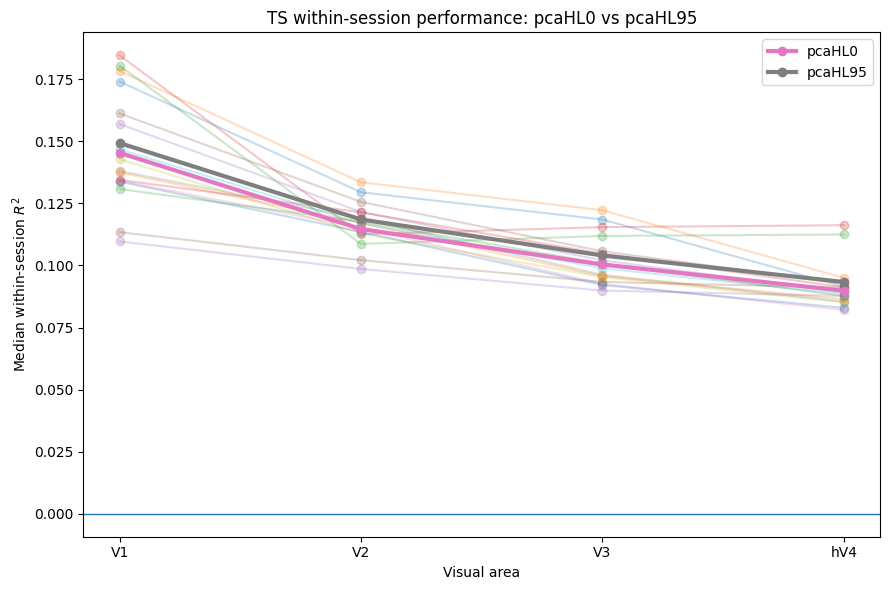

In [78]:
plt.figure(
    figsize=(9, 6)
)

# individual subjects
for subject in SUBJECTS:

    sub = (
        summary_pca_df[
            summary_pca_df["subject"] == subject
        ]
        .set_index("roi")
        .reindex(ROIS)
    )

    plt.plot(
        roi_x,
        sub["R2_pca0"],
        marker="o",
        alpha=0.25
    )

    plt.plot(
        roi_x,
        sub["R2_pca95"],
        marker="o",
        alpha=0.25
    )


# group means
plt.plot(
    roi_x,
    group_pca_summary["R2_pca0"],
    marker="o",
    linewidth=3,
    label="pcaHL0"
)

plt.plot(
    roi_x,
    group_pca_summary["R2_pca95"],
    marker="o",
    linewidth=3,
    label="pcaHL95"
)

plt.axhline(
    0,
    linewidth=1
)

plt.xticks(
    roi_x,
    ROIS
)

plt.xlabel(
    "Visual area"
)

plt.ylabel(
    "Median within-session $R^2$"
)

plt.title(
    "TS within-session performance: pcaHL0 vs pcaHL95"
)

plt.legend()

plt.tight_layout()
plt.show()

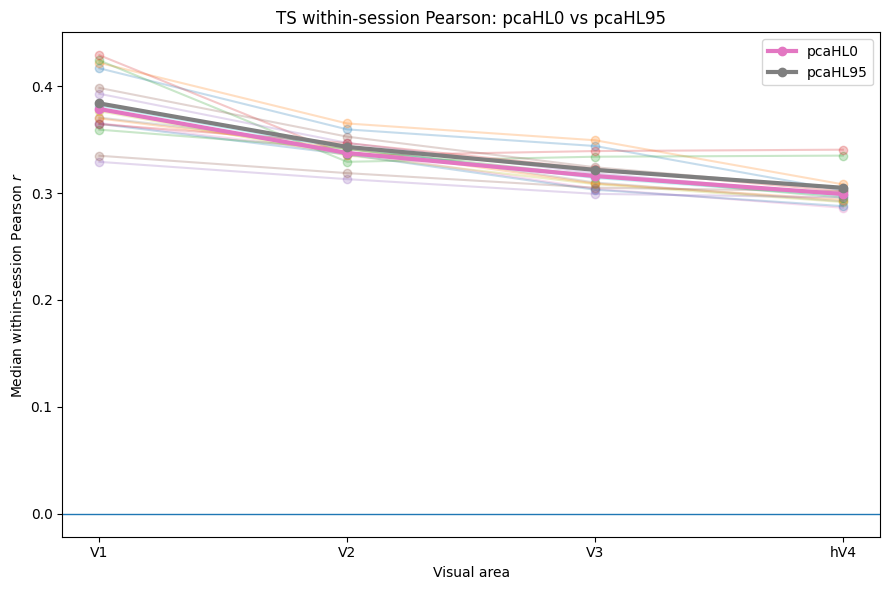

In [79]:
plt.figure(
    figsize=(9, 6)
)

# individual subjects
for subject in SUBJECTS:

    sub = (
        summary_pca_df[
            summary_pca_df["subject"] == subject
        ]
        .set_index("roi")
        .reindex(ROIS)
    )

    plt.plot(
        roi_x,
        sub["Pearson_pca0"],
        marker="o",
        alpha=0.25
    )

    plt.plot(
        roi_x,
        sub["Pearson_pca95"],
        marker="o",
        alpha=0.25
    )


# group means
plt.plot(
    roi_x,
    group_pca_summary["Pearson_pca0"],
    marker="o",
    linewidth=3,
    label="pcaHL0"
)

plt.plot(
    roi_x,
    group_pca_summary["Pearson_pca95"],
    marker="o",
    linewidth=3,
    label="pcaHL95"
)

plt.axhline(
    0,
    linewidth=1
)

plt.xticks(
    roi_x,
    ROIS
)

plt.xlabel(
    "Visual area"
)

plt.ylabel(
    "Median within-session Pearson $r$"
)

plt.title(
    "TS within-session Pearson: pcaHL0 vs pcaHL95"
)

plt.legend()

plt.tight_layout()
plt.show()

In [80]:
# =============================================================================
# GROUP SUMMARY ACROSS SUBJECTS
# =============================================================================

group_pca_table = (
    summary_pca_df
    .groupby("roi")
    [
        [
            "R2_pca0",
            "R2_pca95",
            "R2_pca95_minus_pca0",
            "Pearson_pca0",
            "Pearson_pca95",
            "Pearson_pca95_minus_pca0"
        ]
    ]
    .agg(
        ["mean", "std"]
    )
    .reindex(ROIS)
)

print("\n")
print("=" * 100)
print("GROUP SUMMARY — pcaHL0 VS pcaHL95")
print("=" * 100)

display(group_pca_table)



GROUP SUMMARY — pcaHL0 VS pcaHL95


R2_pca0            R2_pca95           R2_pca95_minus_pca0            \
         mean       std      mean       std                mean       std   
roi                                                                         
V1   0.145311  0.023731  0.149272  0.023942            0.003961  0.000242   
V2   0.114666  0.009054  0.118504  0.009180            0.003838  0.000195   
V3   0.100373  0.010203  0.104014  0.010255            0.003640  0.000144   
hV4  0.089824  0.009672  0.093324  0.009772            0.003500  0.000118   

    Pearson_pca0           Pearson_pca95           Pearson_pca95_minus_pca0  \
            mean       std          mean       std                     mean   
roi                                                                           
V1      0.378588  0.031396      0.383827  0.031220                 0.005239   
V2      0.337489  0.013445      0.343150  0.013409                 0.005662   
V3      0.315941  0.015875      0.321675  0.015679                 0.005733   
hV4     0.299110  0.015461      0.304917  0.015346                 0.005807   

               
          std  
roi            
V1   0.000255  
V2   0.000228  
V3   0.000289  
hV4  0.000159

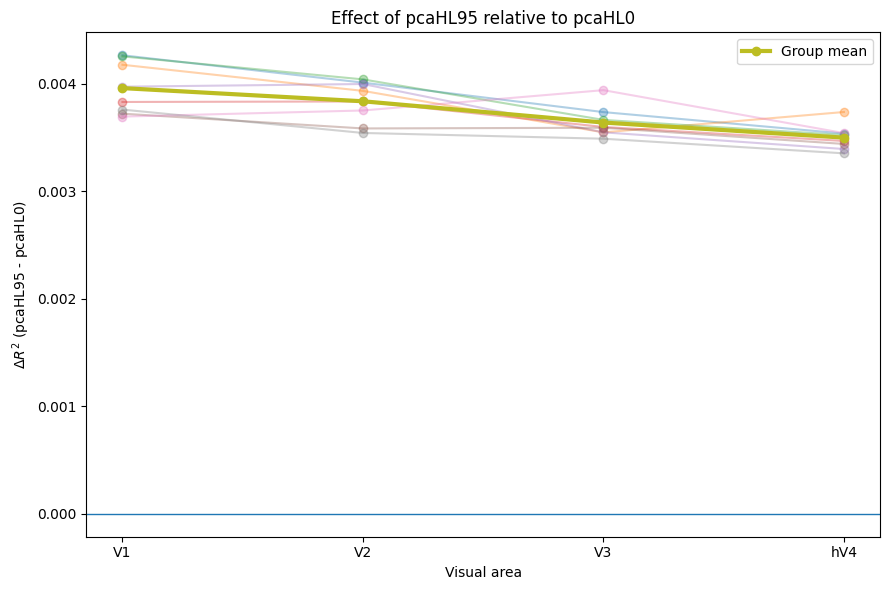

In [81]:
# =============================================================================
# DIFFERENCE PLOT — R2
# =============================================================================

plt.figure(
    figsize=(9, 6)
)

for subject in SUBJECTS:

    sub = (
        summary_pca_df[
            summary_pca_df["subject"] == subject
        ]
        .set_index("roi")
        .reindex(ROIS)
    )

    plt.plot(
        roi_x,
        sub["R2_pca95_minus_pca0"],
        marker="o",
        alpha=0.35
    )


plt.plot(
    roi_x,
    group_pca_summary["R2_pca95_minus_pca0"],
    marker="o",
    linewidth=3,
    label="Group mean"
)

plt.axhline(
    0,
    linewidth=1
)

plt.xticks(
    roi_x,
    ROIS
)

plt.xlabel(
    "Visual area"
)

plt.ylabel(
    r"$\Delta R^2$ (pcaHL95 - pcaHL0)"
)

plt.title(
    "Effect of pcaHL95 relative to pcaHL0"
)

plt.legend()

plt.tight_layout()
plt.show()

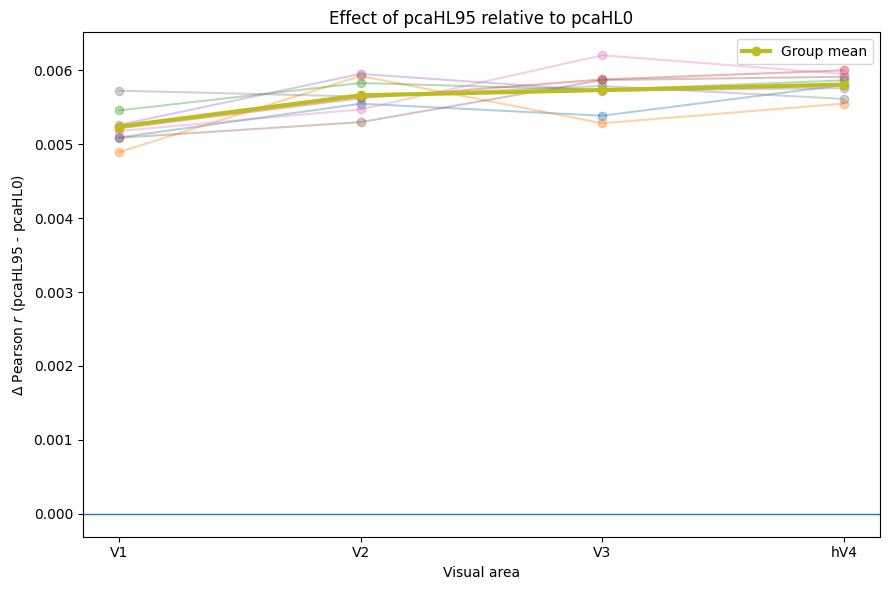

In [82]:
# =============================================================================
# DIFFERENCE PLOT — PEARSON
# =============================================================================

plt.figure(
    figsize=(9, 6)
)

for subject in SUBJECTS:

    sub = (
        summary_pca_df[
            summary_pca_df["subject"] == subject
        ]
        .set_index("roi")
        .reindex(ROIS)
    )

    plt.plot(
        roi_x,
        sub["Pearson_pca95_minus_pca0"],
        marker="o",
        alpha=0.35
    )


plt.plot(
    roi_x,
    group_pca_summary["Pearson_pca95_minus_pca0"],
    marker="o",
    linewidth=3,
    label="Group mean"
)

plt.axhline(
    0,
    linewidth=1
)

plt.xticks(
    roi_x,
    ROIS
)

plt.xlabel(
    "Visual area"
)

plt.ylabel(
    r"$\Delta$ Pearson $r$ (pcaHL95 - pcaHL0)"
)

plt.title(
    "Effect of pcaHL95 relative to pcaHL0"
)

plt.legend()

plt.tight_layout()
plt.show()

# compare pcaall to pcaHL


Loading:
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION/S01_V1_texture_pyramid_OLS_4ori_4sf_pcaAll_V1_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py
R2 shape: (30, 30, 1350)
Pearson shape: (30, 30, 1350)

Loading:
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION/S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py
R2 shape: (30, 30, 1350)
Pearson shape: (30, 30, 1350)

SHAPES
pcaAll95 R2: (30, 1350)
pcaHL95  R2: (30, 1350)
pcaAll95 Pearson: (30, 1350)
pcaHL95  Pearson: (30, 1350)

WITHIN-SESSION PERFORMANCE — S01 V1


,metric,pcaAll95_mean_session_median,pcaHL95_mean_session_median,pcaAll_minus_pcaHL
0,R2,0.009936,0.178295,-0.168359
1,Pearson,0.099418,0.421755,-0.322337



Session-wise:


,session,R2_pcaAll95,R2_pcaHL95,Pearson_pcaAll95,Pearson_pcaHL95,delta_R2,delta_Pearson
0,1,0.012407,0.191548,0.111387,0.437662,-0.179141,-0.326276
1,2,0.011111,0.179036,0.105410,0.423127,-0.167925,-0.317716
2,3,0.010652,0.179197,0.103206,0.423316,-0.168545,-0.320110
3,4,0.011804,0.183369,0.108645,0.428216,-0.171566,-0.319572
4,5,0.010003,0.165522,0.100017,0.406844,-0.155519,-0.306827
5,6,0.009864,0.203624,0.099320,0.451247,-0.193760,-0.351927
6,7,0.009850,0.180740,0.099249,0.425135,-0.170889,-0.325886
7,8,0.008458,0.187799,0.091967,0.433358,-0.179341,-0.341391
8,9,0.010412,0.179427,0.102041,0.423588,-0.169015,-0.321547
9,10,0.009420,0.202901,0.097054,0.450445,-0.193481,-0.353390



DIRECTION CHECK
Sessions pcaAll95 > pcaHL95 (R2): 0 / 30
Sessions pcaAll95 > pcaHL95 (Pearson): 0 / 30


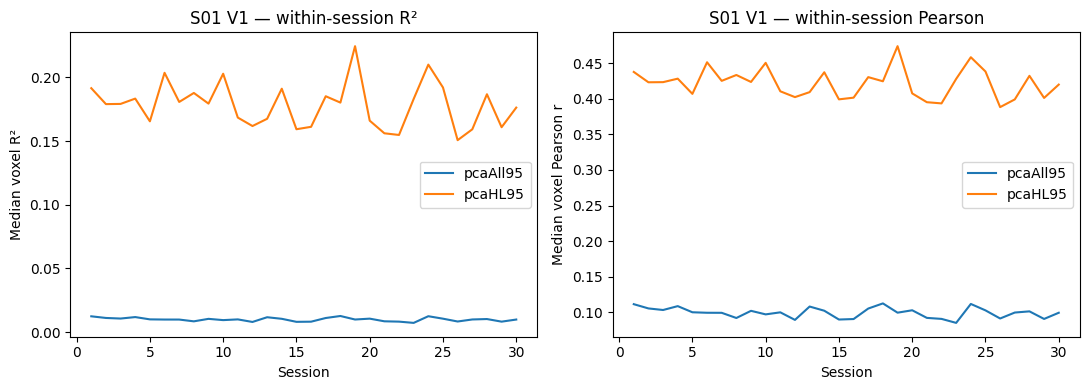

In [2]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# FILES
# ============================================================

BASE = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits/"
    "S01/FAST_CROSS_SESSION"
)

PCA_ALL_FILE = (
    BASE /
    "S01_V1_texture_pyramid_OLS_4ori_4sf_"
    "pcaAll_V1_pca95_use_nsd_grid5_pRFs_"
    "30x30_cross_session.h5py"
)

PCA_HL_FILE = (
    BASE /
    "S01_V1_texture_pyramid_OLS_4ori_4sf_"
    "pcaHL_V1_pca95_use_nsd_grid5_pRFs_"
    "30x30_cross_session.h5py"
)

NSESSIONS = 30


# ============================================================
# LOAD WITHIN-SESSION DIAGONAL
# ============================================================

def load_within_session(fn):

    print("\nLoading:")
    print(fn)

    with h5py.File(fn, "r") as f:

        r2 = np.asarray(f["val_r2"], dtype=float)
        cc = np.asarray(f["val_cc"], dtype=float)

        # remove final singleton dimension
        if r2.ndim == 4:
            r2 = r2[..., 0]

        if cc.ndim == 4:
            cc = cc[..., 0]

        print("R2 shape:", r2.shape)
        print("Pearson shape:", cc.shape)

        # train session == test session
        r2_within = np.stack(
            [r2[s, s, :] for s in range(NSESSIONS)],
            axis=0
        )

        cc_within = np.stack(
            [cc[s, s, :] for s in range(NSESSIONS)],
            axis=0
        )

    return r2_within, cc_within


# ============================================================
# LOAD BOTH MODELS
# ============================================================

all_r2, all_cc = load_within_session(PCA_ALL_FILE)
hl_r2, hl_cc = load_within_session(PCA_HL_FILE)


print("\n" + "=" * 80)
print("SHAPES")
print("=" * 80)

print("pcaAll95 R2:", all_r2.shape)
print("pcaHL95  R2:", hl_r2.shape)
print("pcaAll95 Pearson:", all_cc.shape)
print("pcaHL95  Pearson:", hl_cc.shape)


# ============================================================
# SESSION-WISE MEDIAN ACROSS VOXELS
# ============================================================

all_r2_sess = np.nanmedian(all_r2, axis=1)
hl_r2_sess  = np.nanmedian(hl_r2, axis=1)

all_cc_sess = np.nanmedian(all_cc, axis=1)
hl_cc_sess  = np.nanmedian(hl_cc, axis=1)


# ============================================================
# SUMMARY
# ============================================================

summary = pd.DataFrame({
    "metric": ["R2", "Pearson"],

    "pcaAll95_mean_session_median": [
        np.nanmean(all_r2_sess),
        np.nanmean(all_cc_sess)
    ],

    "pcaHL95_mean_session_median": [
        np.nanmean(hl_r2_sess),
        np.nanmean(hl_cc_sess)
    ],
})

summary["pcaAll_minus_pcaHL"] = (
    summary["pcaAll95_mean_session_median"]
    -
    summary["pcaHL95_mean_session_median"]
)

print("\n" + "=" * 80)
print("WITHIN-SESSION PERFORMANCE — S01 V1")
print("=" * 80)

display(summary)


# ============================================================
# SESSION-BY-SESSION DIFFERENCES
# ============================================================

session_df = pd.DataFrame({
    "session": np.arange(1, NSESSIONS + 1),

    "R2_pcaAll95": all_r2_sess,
    "R2_pcaHL95": hl_r2_sess,

    "Pearson_pcaAll95": all_cc_sess,
    "Pearson_pcaHL95": hl_cc_sess,
})

session_df["delta_R2"] = (
    session_df["R2_pcaAll95"]
    -
    session_df["R2_pcaHL95"]
)

session_df["delta_Pearson"] = (
    session_df["Pearson_pcaAll95"]
    -
    session_df["Pearson_pcaHL95"]
)

print("\nSession-wise:")
display(session_df)


print("\n" + "=" * 80)
print("DIRECTION CHECK")
print("=" * 80)

print(
    "Sessions pcaAll95 > pcaHL95 (R2):",
    np.sum(session_df["delta_R2"] > 0),
    "/",
    NSESSIONS
)

print(
    "Sessions pcaAll95 > pcaHL95 (Pearson):",
    np.sum(session_df["delta_Pearson"] > 0),
    "/",
    NSESSIONS
)


# ============================================================
# PLOT
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 4)
)

# R2
axes[0].plot(
    session_df["session"],
    session_df["R2_pcaAll95"],
    label="pcaAll95"
)

axes[0].plot(
    session_df["session"],
    session_df["R2_pcaHL95"],
    label="pcaHL95"
)

axes[0].set_title("S01 V1 — within-session R²")
axes[0].set_xlabel("Session")
axes[0].set_ylabel("Median voxel R²")
axes[0].legend()


# Pearson
axes[1].plot(
    session_df["session"],
    session_df["Pearson_pcaAll95"],
    label="pcaAll95"
)

axes[1].plot(
    session_df["session"],
    session_df["Pearson_pcaHL95"],
    label="pcaHL95"
)

axes[1].set_title("S01 V1 — within-session Pearson")
axes[1].set_xlabel("Session")
axes[1].set_ylabel("Median voxel Pearson r")
axes[1].legend()

plt.tight_layout()
plt.show()

In [3]:
import h5py
import numpy as np
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits/"
    "S01/FAST_CROSS_SESSION"
)

FILES = {
    "pcaAll95": (
        BASE /
        "S01_V1_texture_pyramid_OLS_4ori_4sf_"
        "pcaAll_V1_pca95_use_nsd_grid5_pRFs_"
        "30x30_cross_session.h5py"
    ),

    "pcaHL95": (
        BASE /
        "S01_V1_texture_pyramid_OLS_4ori_4sf_"
        "pcaHL_V1_pca95_use_nsd_grid5_pRFs_"
        "30x30_cross_session.h5py"
    ),
}


print("=" * 100)
print("FEATURE / COMPONENT COUNT CHECK")
print("=" * 100)

for model_name, fn in FILES.items():

    print("\n" + "#" * 100)
    print(model_name)
    print("#" * 100)
    print(fn)

    with h5py.File(fn, "r") as f:

        print("\nDatasets:")

        for key in f.keys():

            obj = f[key]

            if hasattr(obj, "shape"):
                print(
                    f"{key:35s} "
                    f"shape={obj.shape}"
                )

        print("\nRelevant attributes:")

        for key in [
            "pca_type",
            "pyr_pca_type",
            "pca_pct_var",
            "group_all_hl_feats",
            "do_pyr_varpart",
            "n_ori_pyr",
            "n_sf_pyr",
            "ridge",
            "fitting_type",
        ]:

            if key in f.attrs:
                print(
                    f"{key:25s}: "
                    f"{f.attrs[key]}"
                )

        # ----------------------------------------------------
        # Main thing we care about:
        # best_weights shape
        # Expected approximately:
        #
        # session × voxel × feature × lambda/model
        # ----------------------------------------------------

        if "best_weights" in f:

            w = f["best_weights"]

            print("\nBEST WEIGHTS")
            print("shape:", w.shape)

            if len(w.shape) >= 3:

                n_predictors = w.shape[2]

                print(
                    "Number of predictors in regression:",
                    n_predictors
                )

        else:

            print(
                "\nNo best_weights dataset found."
            )

        # ----------------------------------------------------
        # Also inspect partial-version information
        # ----------------------------------------------------

        if "partial_version_names" in f:

            print("\npartial_version_names:")

            vals = np.asarray(
                f["partial_version_names"]
            )

            print(
                "shape:",
                vals.shape
            )

            print(
                vals
            )


print("\n" + "=" * 100)
print("DONE")
print("=" * 100)

FEATURE / COMPONENT COUNT CHECK

####################################################################################################
pcaAll95
####################################################################################################
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION/S01_V1_texture_pyramid_OLS_4ori_4sf_pcaAll_V1_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py

Datasets:
best_biases                         shape=(30, 1350, 1)
best_lambdas                        shape=(30, 1350, 1)
best_losses                         shape=(30, 1350, 1)
best_prf_models                     shape=(30, 1350, 1)
best_weights                        shape=(30, 1350, 5, 1)
brain_nii_shape                     shape=(3,)
completed_train_sessions            shape=(30,)
fixed_best_model_each_voxel         shape=(1350,)
partial_version_names               shape=(1,)
prf_models                          shape=(1456, 3)
val_cc                              shape=(

# compare to prf_r2

In [22]:
# =============================================================================
# FULL ANALYSIS PIPELINE
# TS vs SP4, SP6 vs SP4, and relation to pRF R2
# =============================================================================

from pathlib import Path
import pickle
import h5py
import nibabel as nib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr


# =============================================================================
# CONFIG
# =============================================================================

SP4_ROOT = Path(
    "/content/drive/MyDrive/V1_Drift/repDrift_expand"
)

SP6_ROOT = Path(
    "/content/drive/MyDrive/V1_Drift/repDrift_expand_6levels"
)

TS_ROOT = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits"
)

PRF_ROOT = Path(
    "/content/drive/MyDrive/V1_Drift/NSD"
)

SUBJECTS = list(range(1, 9))

ROIS = [
    "V1",
    "V2",
    "V3",
    "hV4",
]

N_SESSIONS = 30


# =============================================================================
# LOAD SP SUBJECT
# =============================================================================

def load_sp_subject(root, subject):

    fn = (
        root
        / f"regressSessCombineROI_sub{subject}.pkl"
    )

    if not fn.exists():
        raise FileNotFoundError(
            f"SP file not found:\n{fn}"
        )

    with open(fn, "rb") as f:
        data = pickle.load(f)

    return fn, data


# =============================================================================
# EXTRACT SP WITHIN-SESSION R2
# =============================================================================

def extract_sp_r2_within(arr, n_sessions=30):

    arr = np.asarray(arr)
    arr = np.squeeze(arr)

    if arr.ndim != 2:
        raise ValueError(
            f"Unexpected SP roiNsdOriR2within shape: {arr.shape}"
        )

    # Expected:
    # 30/31 sessions × voxels
    if arr.shape[0] in [
        n_sessions,
        n_sessions + 1,
    ]:

        out = arr[:n_sessions, :]

    # Defensive alternative:
    # voxels × 30/31 sessions
    elif arr.shape[1] in [
        n_sessions,
        n_sessions + 1,
    ]:

        out = arr[:, :n_sessions].T

    else:

        raise ValueError(
            f"Could not identify session dimension "
            f"in SP R2 array: {arr.shape}"
        )

    return out


# =============================================================================
# FIND TS CROSS-SESSION FILE
# =============================================================================

def get_ts_file(subject, roi):

    subject_name = f"S{subject:02d}"

    folder = (
        TS_ROOT
        / subject_name
        / "FAST_CROSS_SESSION"
    )

    exact_name = (
        f"{subject_name}_{roi}_"
        f"texture_pyramid_OLS_4ori_4sf_"
        f"pcaHL_{roi}_pca95_"
        f"use_nsd_grid5_pRFs_"
        f"30x30_cross_session.h5py"
    )

    exact_file = (
        folder
        / exact_name
    )

    if exact_file.exists():

        return exact_file

    # Fallback search
    candidates = list(
        folder.glob(
            f"{subject_name}_{roi}_"
            f"*pcaHL*{roi}*pca95*"
            f"30x30_cross_session.h5py"
        )
    )

    if len(candidates) == 0:

        raise FileNotFoundError(
            f"No TS file found for "
            f"S{subject:02d} {roi}"
        )

    if len(candidates) > 1:

        print(
            f"\nMultiple TS files found for "
            f"S{subject:02d} {roi}:"
        )

        for fn in candidates:
            print(fn)

        raise RuntimeError(
            "More than one TS candidate found."
        )

    return candidates[0]


# =============================================================================
# EXTRACT TS WITHIN-SESSION R2
# =============================================================================

def extract_ts_r2_within(arr, n_sessions=30):

    arr = np.asarray(arr)

    # val_r2 often:
    # train × test × voxel × 1
    if arr.ndim == 4:

        arr = arr[..., 0]

    if arr.ndim != 3:

        raise ValueError(
            f"Unexpected TS val_r2 shape: {arr.shape}"
        )

    if (
        arr.shape[0] < n_sessions
        or
        arr.shape[1] < n_sessions
    ):

        raise ValueError(
            f"TS matrix does not contain "
            f"{n_sessions} sessions: {arr.shape}"
        )

    # Within-session diagonal:
    # train session s → test session s
    out = np.stack(
        [
            arr[s, s, :]
            for s in range(n_sessions)
        ],
        axis=0,
    )

    return out


# =============================================================================
# LOAD TS WITHIN-SESSION R2 + EXACT voxel_index
# =============================================================================

def load_ts_r2_and_voxel_index(
    subject,
    roi,
    n_sessions=30,
):
    """
    Load TS within-session R2 and the voxel_index stored in the SAME
    cross-session HDF5 file.

    This guarantees that voxel_index is in the same order as val_r2.

    Returns
    -------
    ts_r2 : array, shape (sessions, voxels)
    voxel_index : array, shape (voxels,)
    ts_file : Path
    """

    ts_file = get_ts_file(
        subject,
        roi,
    )

    with h5py.File(
        ts_file,
        "r",
    ) as f:

        # -------------------------------------------------------------
        # R2
        # -------------------------------------------------------------

        val_r2 = np.asarray(
            f["val_r2"]
        )

        ts_r2 = extract_ts_r2_within(
            val_r2,
            n_sessions,
        )


        # -------------------------------------------------------------
        # voxel_index
        # -------------------------------------------------------------

        if "voxel_index" not in f:

            raise KeyError(
                f"'voxel_index' missing from TS file:\n{ts_file}"
            )

        voxel_index = (
            np.asarray(
                f["voxel_index"]
            )
            .squeeze()
            .astype(int)
        )


    # -----------------------------------------------------------------
    # Strict alignment check
    # -----------------------------------------------------------------

    if len(voxel_index) != ts_r2.shape[1]:

        raise ValueError(
            f"\nTS voxel alignment mismatch "
            f"S{subject:02d} {roi}\n"
            f"TS R2 voxels = {ts_r2.shape[1]}\n"
            f"voxel_index  = {len(voxel_index)}\n"
            f"File: {ts_file}"
        )


    return (
        ts_r2,
        voxel_index,
        ts_file,
    )

# =============================================================================
# LOAD pRF R2
# =============================================================================

def load_prf_r2(
    voxel_index,
    subject,
    prf_root,
):

    r2_path = (
        prf_root
        / f"subj{subject:02d}"
        / "func1pt8mm"
        / "prf_R2.nii.gz"
    )

    if not r2_path.exists():

        raise FileNotFoundError(
            f"Missing pRF R2 file:\n{r2_path}"
        )

    r2_data = (
        nib.load(r2_path)
        .get_fdata()
    )

    r2_flat = (
        r2_data
        .reshape(-1)
    )

    if voxel_index.max() >= len(r2_flat):

        raise IndexError(
            f"voxel_index max = {voxel_index.max()} "
            f"but pRF map contains only "
            f"{len(r2_flat)} voxels."
        )

    # NSD pRF R2 stored in percent
    prf_r2 = (
        r2_flat[
            voxel_index
        ]
        .astype(float)
        / 100.0
    )

    # invalid values
    prf_r2[
        prf_r2 < 0
    ] = np.nan

    prf_r2 = np.clip(
        prf_r2,
        0,
        1,
    )

    return prf_r2


# =============================================================================
# BUILD COMPLETE VOXEL-LEVEL TABLE
# =============================================================================

all_parts = []


for subject in SUBJECTS:

    print("\n")
    print("=" * 100)
    print(f"SUBJECT {subject}")
    print("=" * 100)


    # =========================================================================
    # LOAD SP4 + SP6
    # =========================================================================

    sp4_file, sp4 = load_sp_subject(
        SP4_ROOT,
        subject,
    )

    sp6_file, sp6 = load_sp_subject(
        SP6_ROOT,
        subject,
    )

    print(
        "SP4:",
        sp4_file.name
    )

    print(
        "SP6:",
        sp6_file.name
    )


    # =========================================================================
    # VERIFY FOUR COMBINED ROIS
    # =========================================================================

    if len(
        sp4["roiNsdOriR2within"]
    ) != 4:

        raise ValueError(
            f"S{subject:02d} SP4 does not contain "
            f"4 combined ROI entries."
        )

    if len(
        sp6["roiNsdOriR2within"]
    ) != 4:

        raise ValueError(
            f"S{subject:02d} SP6 does not contain "
            f"4 combined ROI entries."
        )


    # =========================================================================
    # ROI LOOP
    # =========================================================================

    for roi_idx, roi in enumerate(
        ROIS
    ):

        print("\n")
        print("-" * 80)
        print(
            f"S{subject:02d} — {roi}"
        )
        print("-" * 80)


        # =====================================================================
        # SP4 WITHIN-SESSION R2
        # =====================================================================

        sp4_r2 = extract_sp_r2_within(
            sp4[
                "roiNsdOriR2within"
            ][roi_idx],
            N_SESSIONS,
        )


        # =====================================================================
        # SP6 WITHIN-SESSION R2
        # =====================================================================

        sp6_r2 = extract_sp_r2_within(
            sp6[
                "roiNsdOriR2within"
            ][roi_idx],
            N_SESSIONS,
        )


        # =====================================================================
        # TS WITHIN-SESSION R2 + EXACT VOXEL INDEX
        # =====================================================================

        ts_r2, voxel_index, ts_file = (
            load_ts_r2_and_voxel_index(
                subject,
                roi,
                N_SESSIONS,
            )
        )

        # =====================================================================
        # pRF R2
        # =====================================================================

        prf_r2 = load_prf_r2(
            voxel_index,
            subject,
            PRF_ROOT,
        )


        # =====================================================================
        # SHAPE CHECK
        # =====================================================================

        n_sp4 = sp4_r2.shape[1]
        n_sp6 = sp6_r2.shape[1]
        n_ts = ts_r2.shape[1]
        n_idx = len(voxel_index)
        n_prf = len(prf_r2)


        print(
            "SP4:",
            sp4_r2.shape
        )

        print(
            "SP6:",
            sp6_r2.shape
        )

        print(
            "TS :",
            ts_r2.shape
        )

        print(
            "voxel_index:",
            n_idx
        )

        print(
            "pRF R2:",
            n_prf
        )


        if not (
            n_sp4
            ==
            n_sp6
            ==
            n_ts
            ==
            n_idx
            ==
            n_prf
        ):

            raise ValueError(
                f"\nVOXEL COUNT MISMATCH "
                f"S{subject:02d} {roi}\n"
                f"SP4 = {n_sp4}\n"
                f"SP6 = {n_sp6}\n"
                f"TS  = {n_ts}\n"
                f"voxel_index = {n_idx}\n"
                f"pRF = {n_prf}\n"
            )


        # =====================================================================
        # DIFFERENCE INSIDE EACH SESSION
        # =====================================================================

        ts_minus_sp4_session = (
            ts_r2
            -
            sp4_r2
        )

        sp6_minus_sp4_session = (
            sp6_r2
            -
            sp4_r2
        )


        # =====================================================================
        # MEAN ACROSS 30 SESSIONS FOR EACH VOXEL
        # =====================================================================

        sp4_vox = np.nanmean(
            sp4_r2,
            axis=0,
        )

        sp6_vox = np.nanmean(
            sp6_r2,
            axis=0,
        )

        ts_vox = np.nanmean(
            ts_r2,
            axis=0,
        )


        ts_minus_sp4_vox = np.nanmean(
            ts_minus_sp4_session,
            axis=0,
        )

        sp6_minus_sp4_vox = np.nanmean(
            sp6_minus_sp4_session,
            axis=0,
        )


        # =====================================================================
        # SAVE VOXEL TABLE
        # =====================================================================

        this_df = pd.DataFrame({

            "subject":
                subject,

            "roi":
                roi,

            "voxel":
                np.arange(n_idx),

            "voxel_index":
                voxel_index,

            "prf_r2":
                prf_r2,

            "SP4_R2":
                sp4_vox,

            "SP6_R2":
                sp6_vox,

            "TS_R2":
                ts_vox,

            "TS_minus_SP4":
                ts_minus_sp4_vox,

            "SP6_minus_SP4":
                sp6_minus_sp4_vox,
        })


        all_parts.append(
            this_df
        )


# =============================================================================
# FINAL TABLE
# =============================================================================

model_difference_df = pd.concat(
    all_parts,
    ignore_index=True,
)


print("\n")
print("=" * 100)
print("FINAL VOXEL-LEVEL TABLE")
print("=" * 100)

print(
    "Rows:",
    len(model_difference_df)
)

display(
    model_difference_df.head(20)
)



SUBJECT 1
SP4: regressSessCombineROI_sub1.pkl
SP6: regressSessCombineROI_sub1.pkl


--------------------------------------------------------------------------------
S01 — V1
--------------------------------------------------------------------------------
SP4: (30, 1350)
SP6: (30, 1350)
TS : (30, 1350)
voxel_index: 1350
pRF R2: 1350


--------------------------------------------------------------------------------
S01 — V2
--------------------------------------------------------------------------------
SP4: (30, 1433)
SP6: (30, 1433)
TS : (30, 1433)
voxel_index: 1433
pRF R2: 1433


--------------------------------------------------------------------------------
S01 — V3
--------------------------------------------------------------------------------
SP4: (30, 1187)
SP6: (30, 1187)
TS : (30, 1187)
voxel_index: 1187
pRF R2: 1187


--------------------------------------------------------------------------------
S01 — hV4
-------------------------------------------------------------------

,subject,roi,voxel,voxel_index,prf_r2,SP4_R2,SP6_R2,TS_R2,TS_minus_SP4,SP6_minus_SP4
0,1,V1,0,267967,0.031360,0.029530,0.041756,0.066596,0.037066,0.012226
1,1,V1,1,268049,0.187017,0.037839,0.047237,0.091721,0.053882,0.009398
2,1,V1,2,268131,0.149973,0.033565,0.045337,0.076613,0.043048,0.011772
3,1,V1,3,268132,0.190644,0.085283,0.084483,0.082564,-0.002719,-0.000800
4,1,V1,4,268293,0.221667,0.131971,0.124057,0.089655,-0.042317,-0.007914
5,1,V1,5,268294,0.172546,0.129201,0.121921,0.088221,-0.040979,-0.007280
6,1,V1,6,276597,NaN,0.057185,0.061998,0.107534,0.050348,0.004812
7,1,V1,7,276598,NaN,0.064945,0.069306,0.078775,0.013831,0.004362
8,1,V1,8,276599,NaN,0.104004,0.097042,0.074995,-0.029009,-0.006962
9,1,V1,9,276676,0.224797,0.118483,0.110393,0.140403,0.021919,-0.008091


In [23]:
# =============================================================================
# SAVE
# =============================================================================

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/V1_Drift/plots/model_comparison"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

model_difference_df.to_csv(
    OUTPUT_DIR
    / "voxel_level_TS_SP4_SP6_prfR2.csv",
    index=False,
)

print(
    "Saved:",
    OUTPUT_DIR
    / "voxel_level_TS_SP4_SP6_prfR2.csv"
)

Saved: /content/drive/MyDrive/V1_Drift/plots/model_comparison/voxel_level_TS_SP4_SP6_prfR2.csv


In [24]:
# =============================================================================
# SPEARMAN PER SUBJECT × ROI
# =============================================================================

corr_rows = []


for subject in SUBJECTS:

    for roi in ROIS:

        d = model_difference_df[
            (model_difference_df["subject"] == subject)
            &
            (model_difference_df["roi"] == roi)
        ].copy()


        # ---------------------------------------------------------------------
        # pRF R2 vs TS-SP4
        # ---------------------------------------------------------------------

        valid = (
            np.isfinite(
                d["prf_r2"]
            )
            &
            np.isfinite(
                d["TS_minus_SP4"]
            )
        )

        if valid.sum() >= 3:

            rho_ts, p_ts = spearmanr(
                d.loc[
                    valid,
                    "prf_r2",
                ],
                d.loc[
                    valid,
                    "TS_minus_SP4",
                ],
            )

        else:

            rho_ts = np.nan
            p_ts = np.nan


        # ---------------------------------------------------------------------
        # pRF R2 vs SP6-SP4
        # ---------------------------------------------------------------------

        valid = (
            np.isfinite(
                d["prf_r2"]
            )
            &
            np.isfinite(
                d["SP6_minus_SP4"]
            )
        )

        if valid.sum() >= 3:

            rho_64, p_64 = spearmanr(
                d.loc[
                    valid,
                    "prf_r2",
                ],
                d.loc[
                    valid,
                    "SP6_minus_SP4",
                ],
            )

        else:

            rho_64 = np.nan
            p_64 = np.nan


        # ---------------------------------------------------------------------
        # TS-SP4 vs SP6-SP4
        # ---------------------------------------------------------------------

        valid = (
            np.isfinite(
                d["TS_minus_SP4"]
            )
            &
            np.isfinite(
                d["SP6_minus_SP4"]
            )
        )

        if valid.sum() >= 3:

            rho_models, p_models = spearmanr(
                d.loc[
                    valid,
                    "TS_minus_SP4",
                ],
                d.loc[
                    valid,
                    "SP6_minus_SP4",
                ],
            )

        else:

            rho_models = np.nan
            p_models = np.nan


        corr_rows.append({

            "subject":
                subject,

            "roi":
                roi,

            "rho_prf_TS_minus_SP4":
                rho_ts,

            "p_prf_TS_minus_SP4":
                p_ts,

            "rho_prf_SP6_minus_SP4":
                rho_64,

            "p_prf_SP6_minus_SP4":
                p_64,

            "rho_TSminusSP4_vs_SP6minusSP4":
                rho_models,

            "p_TSminusSP4_vs_SP6minusSP4":
                p_models,
        })


subject_corr_df = pd.DataFrame(
    corr_rows
)


display(
    subject_corr_df
)

,subject,roi,rho_prf_TS_minus_SP4,p_prf_TS_minus_SP4,rho_prf_SP6_minus_SP4,p_prf_SP6_minus_SP4,rho_TSminusSP4_vs_SP6minusSP4,p_TSminusSP4_vs_SP6minusSP4
0,1,V1,0.474309,7.804520e-75,0.028219,3.061666e-01,0.539806,6.003317e-103
1,1,V2,0.529545,9.889120e-100,0.107556,6.718109e-05,0.457424,5.187854e-75
2,1,V3,0.541329,9.628155e-90,0.089114,2.321052e-03,0.301785,2.041134e-26
3,1,hV4,0.255539,6.339955e-11,-0.029990,4.506024e-01,0.040709,2.866503e-01
4,2,V1,0.620334,1.585712e-111,0.008540,7.833535e-01,0.530858,3.862872e-81
5,2,V2,0.553856,3.157610e-81,-0.038328,2.266060e-01,0.334647,1.532487e-29
6,2,V3,0.542276,5.163502e-81,0.034472,2.653321e-01,0.354702,7.206464e-34
7,2,hV4,0.123110,8.568343e-03,-0.139352,2.893369e-03,-0.068538,1.325443e-01
8,3,V1,0.587960,1.418166e-112,0.014074,6.260738e-01,0.504495,6.251601e-82
9,3,V2,0.518433,1.072770e-76,0.081629,6.753119e-03,0.186972,1.953437e-10


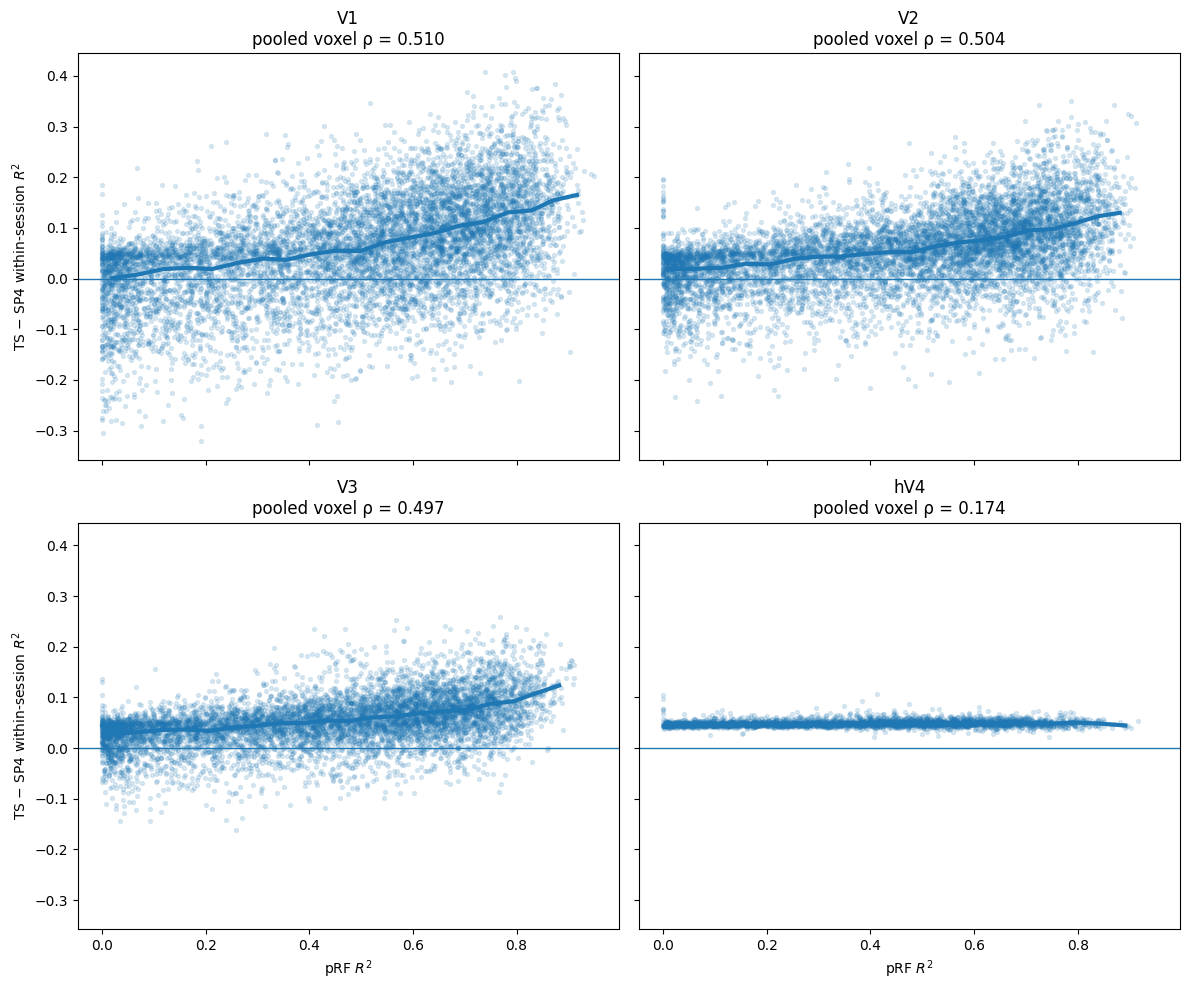

In [84]:
def add_binned_median_line(
    ax,
    x,
    y,
    n_bins=20,
):
    """
    Add a median trend line by binning x and taking the median y
    within each x-bin.
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    valid = (
        np.isfinite(x)
        &
        np.isfinite(y)
    )

    x = x[valid]
    y = y[valid]

    if len(x) == 0:
        return

    # Equal-width bins across the observed x range
    bin_edges = np.linspace(
        np.nanmin(x),
        np.nanmax(x),
        n_bins + 1,
    )

    bin_centers = []
    median_y = []

    for i in range(n_bins):

        # Include right edge only for final bin
        if i == n_bins - 1:
            mask = (
                (x >= bin_edges[i])
                &
                (x <= bin_edges[i + 1])
            )
        else:
            mask = (
                (x >= bin_edges[i])
                &
                (x < bin_edges[i + 1])
            )

        if np.sum(mask) == 0:
            continue

        # Use median x of the actual voxels in that bin
        bin_centers.append(
            np.nanmedian(x[mask])
        )

        median_y.append(
            np.nanmedian(y[mask])
        )

    ax.plot(
        bin_centers,
        median_y,
        linewidth=3,
        label="Binned median",
    )

# =============================================================================
# FIGURE 1
# pRF R2 vs TS - SP4
# individual voxels + median trend
# =============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 10),
    sharex=True,
    sharey=True,
)

axes = axes.ravel()


for i, (ax, roi) in enumerate(zip(axes, ROIS)):

    d = model_difference_df[
        model_difference_df["roi"] == roi
    ]

    valid = (
        np.isfinite(d["prf_r2"])
        &
        np.isfinite(d["TS_minus_SP4"])
    )

    x = d.loc[valid, "prf_r2"].values
    y = d.loc[valid, "TS_minus_SP4"].values

    rho, _ = spearmanr(x, y)

    ax.scatter(
        x,
        y,
        s=8,
        alpha=0.15,
        label="Voxels",
    )

    add_binned_median_line(
        ax,
        x,
        y,
        n_bins=20,
    )

    ax.axhline(
        0,
        linewidth=1,
    )

    ax.set_title(
        f"{roi}\n"
        f"pooled voxel ρ = {rho:.3f}"
    )

    # X-axis title only on bottom row
    if i >= 2:
        ax.set_xlabel(
            "pRF $R^2$"
        )

    # Y-axis title only on left column
    if i % 2 == 0:
        ax.set_ylabel(
            "TS − SP4 within-session $R^2$"
        )


plt.tight_layout()
plt.show()

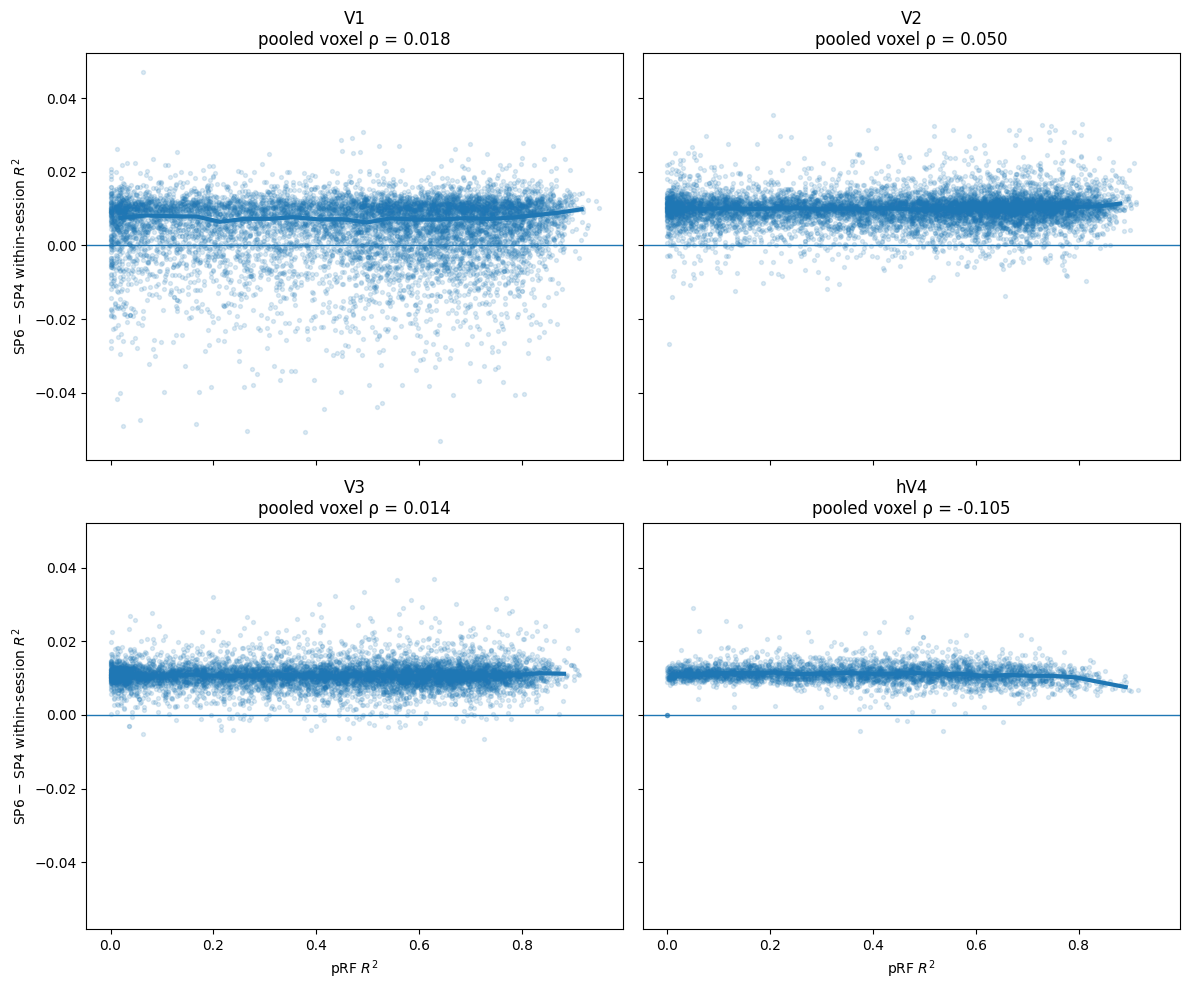

In [85]:
# =============================================================================
# FIGURE 2
# pRF R2 vs SP6 - SP4
# individual voxels + median trend
# =============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 10),
    sharex=True,
    sharey=True,
)

axes = axes.ravel()


for i, (ax, roi) in enumerate(zip(axes, ROIS)):

    d = model_difference_df[
        model_difference_df["roi"] == roi
    ]

    valid = (
        np.isfinite(d["prf_r2"])
        &
        np.isfinite(d["SP6_minus_SP4"])
    )

    x = d.loc[
        valid,
        "prf_r2",
    ].values

    y = d.loc[
        valid,
        "SP6_minus_SP4",
    ].values


    rho, _ = spearmanr(
        x,
        y,
    )


    # Individual voxels
    ax.scatter(
        x,
        y,
        s=8,
        alpha=0.15,
    )


    # Median trend
    add_binned_median_line(
        ax,
        x,
        y,
        n_bins=20,
    )


    ax.axhline(
        0,
        linewidth=1,
    )

    ax.set_title(
        f"{roi}\n"
        f"pooled voxel ρ = {rho:.3f}"
    )


    # X-axis title only on bottom row
    if i >= 2:
        ax.set_xlabel(
            "pRF $R^2$"
        )


    # Y-axis title only on left column
    if i % 2 == 0:
        ax.set_ylabel(
            "SP6 − SP4 within-session $R^2$"
        )


plt.tight_layout()
plt.show()

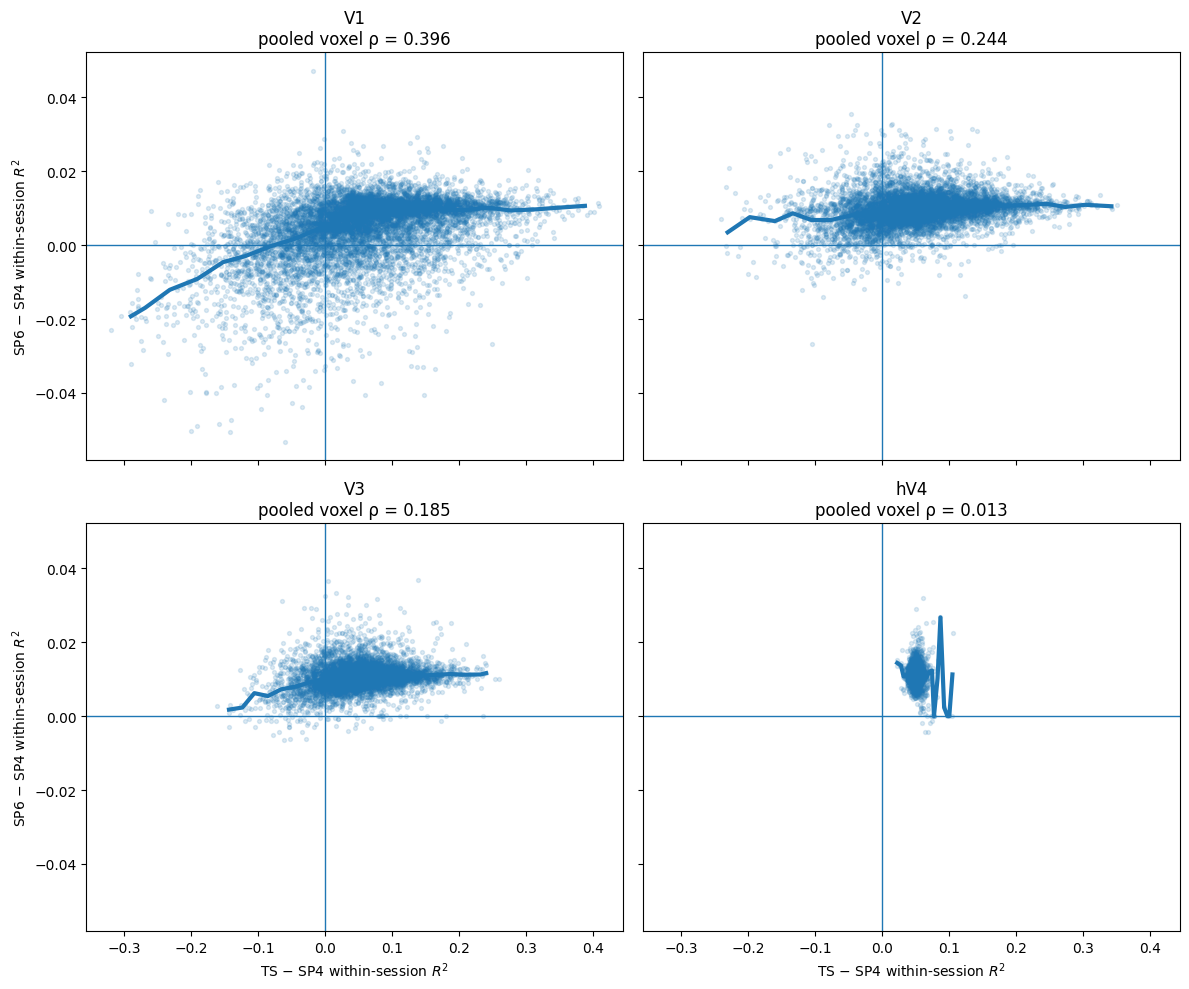

In [86]:
# =============================================================================
# FIGURE 3
# X = TS - SP4
# Y = SP6 - SP4
# individual voxels + median trend
# =============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 10),
    sharex=True,
    sharey=True,
)

axes = axes.ravel()


for i, (ax, roi) in enumerate(zip(axes, ROIS)):

    d = model_difference_df[
        model_difference_df["roi"] == roi
    ]

    valid = (
        np.isfinite(d["TS_minus_SP4"])
        &
        np.isfinite(d["SP6_minus_SP4"])
    )

    x = d.loc[
        valid,
        "TS_minus_SP4",
    ].values

    y = d.loc[
        valid,
        "SP6_minus_SP4",
    ].values


    rho, _ = spearmanr(
        x,
        y,
    )


    # Individual voxels
    ax.scatter(
        x,
        y,
        s=8,
        alpha=0.15,
    )


    # Median trend
    add_binned_median_line(
        ax,
        x,
        y,
        n_bins=20,
    )


    ax.axhline(
        0,
        linewidth=1,
    )

    ax.axvline(
        0,
        linewidth=1,
    )

    ax.set_title(
        f"{roi}\n"
        f"pooled voxel ρ = {rho:.3f}"
    )


    # X-axis title only on bottom row
    if i >= 2:
        ax.set_xlabel(
            "TS − SP4 within-session $R^2$"
        )


    # Y-axis title only on left column
    if i % 2 == 0:
        ax.set_ylabel(
            "SP6 − SP4 within-session $R^2$"
        )


plt.tight_layout()
plt.show()

In [28]:
# =============================================================================
# GROUP SUMMARY OF SUBJECT-LEVEL CORRELATIONS
# =============================================================================

group_corr_summary = (
    subject_corr_df
    .groupby(
        "roi"
    )
    [
        [
            "rho_prf_TS_minus_SP4",
            "rho_prf_SP6_minus_SP4",
            "rho_TSminusSP4_vs_SP6minusSP4",
        ]
    ]
    .agg(
        ["mean", "std", "median"]
    )
    .reindex(
        ROIS
    )
)


display(
    group_corr_summary
)

rho_prf_TS_minus_SP4                     rho_prf_SP6_minus_SP4            \
                    mean       std    median                  mean       std   
roi                                                                            
V1              0.530845  0.055990  0.526338             -0.020562  0.045448   
V2              0.521661  0.048351  0.536476              0.027319  0.057402   
V3              0.517400  0.064105  0.540044              0.009350  0.046062   
hV4             0.210911  0.118884  0.249353             -0.113107  0.082803   

              rho_TSminusSP4_vs_SP6minusSP4                      
       median                          mean       std    median  
roi                                                              
V1  -0.002632                      0.433647  0.105680  0.448776  
V2   0.026852                      0.232279  0.128182  0.198407  
V3   0.014266                      0.175967  0.116809  0.155920  
hV4 -0.119370                      0.015304  0.091476  0.020997

# pRF R2 vs ABSOLUTE MODEL PERFORMANCE

In [32]:
# =============================================================================
# pRF R2 vs ABSOLUTE MODEL PERFORMANCE
#
# Goal:
# 1. pRF R2 vs TS R2
# 2. pRF R2 vs SP4 R2
#
# Individual voxels + binned median trend
# =============================================================================

from scipy.stats import spearmanr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# =============================================================================
# HELPER: BINNED MEDIAN LINE
# =============================================================================

def add_binned_median_line(
    ax,
    x,
    y,
    n_bins=20,
):
    """
    Divide the x-axis into equal-width bins and plot the median
    y-value of the voxels within each bin.
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    valid = (
        np.isfinite(x)
        &
        np.isfinite(y)
    )

    x = x[valid]
    y = y[valid]

    if len(x) == 0:
        return

    bin_edges = np.linspace(
        np.nanmin(x),
        np.nanmax(x),
        n_bins + 1,
    )

    median_x = []
    median_y = []

    for i in range(n_bins):

        if i == n_bins - 1:

            mask = (
                (x >= bin_edges[i])
                &
                (x <= bin_edges[i + 1])
            )

        else:

            mask = (
                (x >= bin_edges[i])
                &
                (x < bin_edges[i + 1])
            )

        if np.sum(mask) == 0:
            continue

        median_x.append(
            np.nanmedian(x[mask])
        )

        median_y.append(
            np.nanmedian(y[mask])
        )

    ax.plot(
        median_x,
        median_y,
        linewidth=3,
        label="Binned median",
    )

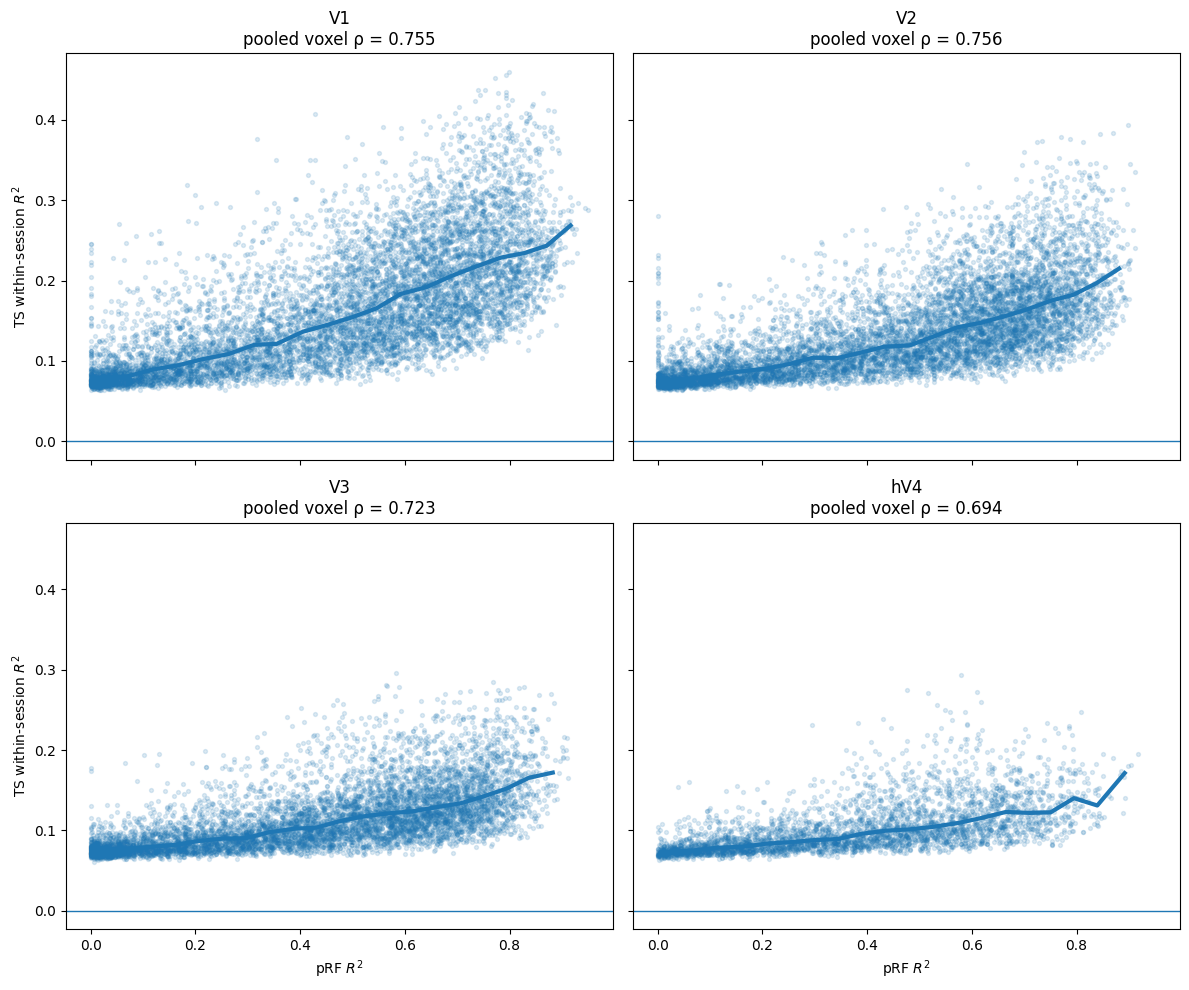

In [87]:
# =============================================================================
# FIGURE 1
# pRF R2 vs TS R2
# =============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 10),
    sharex=True,
    sharey=True,
)

axes = axes.ravel()


for i, (ax, roi) in enumerate(zip(axes, ROIS)):

    d = model_difference_df[
        model_difference_df["roi"] == roi
    ].copy()

    valid = (
        np.isfinite(d["prf_r2"])
        &
        np.isfinite(d["TS_R2"])
    )

    x = d.loc[
        valid,
        "prf_r2"
    ].values

    y = d.loc[
        valid,
        "TS_R2"
    ].values


    # -------------------------------------------------------------------------
    # Pooled voxel correlation
    # descriptive only
    # -------------------------------------------------------------------------

    rho, _ = spearmanr(
        x,
        y,
    )


    # -------------------------------------------------------------------------
    # Individual voxels
    # -------------------------------------------------------------------------

    ax.scatter(
        x,
        y,
        s=8,
        alpha=0.15,
    )


    # -------------------------------------------------------------------------
    # Binned median
    # -------------------------------------------------------------------------

    add_binned_median_line(
        ax,
        x,
        y,
        n_bins=20,
    )


    ax.axhline(
        0,
        linewidth=1,
    )


    ax.set_title(
        f"{roi}\n"
        f"pooled voxel ρ = {rho:.3f}"
    )


    # X-axis title only on bottom row
    if i >= 2:
        ax.set_xlabel(
            "pRF $R^2$"
        )


    # Y-axis title only on left column
    if i % 2 == 0:
        ax.set_ylabel(
            "TS within-session $R^2$"
        )


plt.tight_layout()
plt.show()

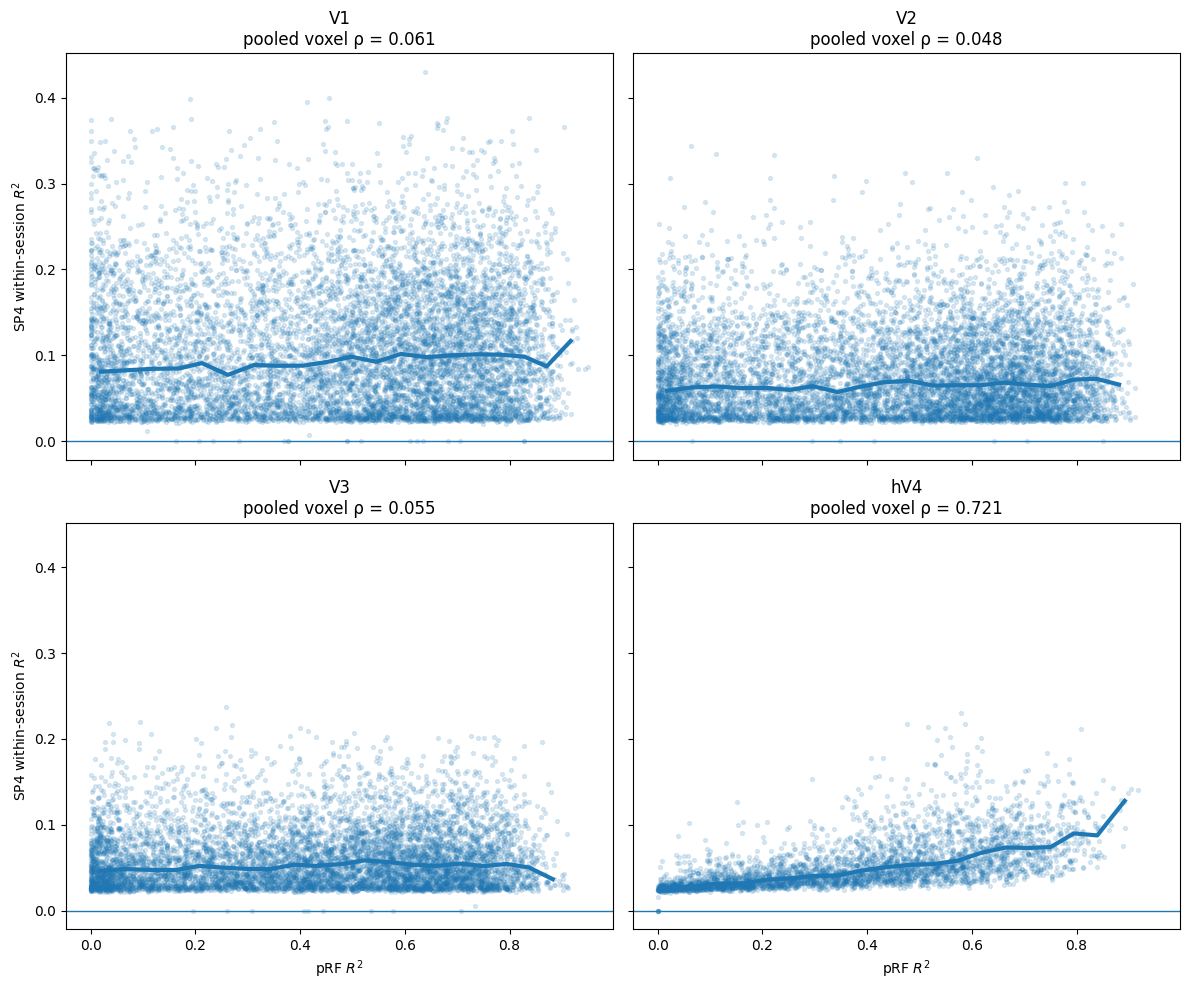

In [88]:
# =============================================================================
# FIGURE 2
# pRF R2 vs SP4 R2
# =============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 10),
    sharex=True,
    sharey=True,
)

axes = axes.ravel()


for i, (ax, roi) in enumerate(zip(axes, ROIS)):

    d = model_difference_df[
        model_difference_df["roi"] == roi
    ].copy()

    valid = (
        np.isfinite(d["prf_r2"])
        &
        np.isfinite(d["SP4_R2"])
    )

    x = d.loc[
        valid,
        "prf_r2"
    ].values

    y = d.loc[
        valid,
        "SP4_R2"
    ].values


    # -------------------------------------------------------------------------
    # Pooled voxel correlation
    # -------------------------------------------------------------------------

    rho, _ = spearmanr(
        x,
        y,
    )


    # -------------------------------------------------------------------------
    # Individual voxels
    # -------------------------------------------------------------------------

    ax.scatter(
        x,
        y,
        s=8,
        alpha=0.15,
    )


    # -------------------------------------------------------------------------
    # Binned median
    # -------------------------------------------------------------------------

    add_binned_median_line(
        ax,
        x,
        y,
        n_bins=20,
    )


    ax.axhline(
        0,
        linewidth=1,
    )


    ax.set_title(
        f"{roi}\n"
        f"pooled voxel ρ = {rho:.3f}"
    )


    # X-axis title only on bottom row
    if i >= 2:
        ax.set_xlabel(
            "pRF $R^2$"
        )


    # Y-axis title only on left column
    if i % 2 == 0:
        ax.set_ylabel(
            "SP4 within-session $R^2$"
        )


plt.tight_layout()
plt.show()

In [35]:
# =============================================================================
# SUBJECT-LEVEL CORRELATIONS
# pRF R2 vs TS R2
# pRF R2 vs SP4 R2
# =============================================================================

rows = []


for subject in SUBJECTS:

    for roi in ROIS:

        d = model_difference_df[
            (model_difference_df["subject"] == subject)
            &
            (model_difference_df["roi"] == roi)
        ].copy()


        # =====================================================================
        # pRF vs TS
        # =====================================================================

        valid_ts = (
            np.isfinite(d["prf_r2"])
            &
            np.isfinite(d["TS_R2"])
        )

        if valid_ts.sum() >= 3:

            rho_ts, p_ts = spearmanr(
                d.loc[
                    valid_ts,
                    "prf_r2"
                ],
                d.loc[
                    valid_ts,
                    "TS_R2"
                ],
            )

        else:

            rho_ts = np.nan
            p_ts = np.nan


        # =====================================================================
        # pRF vs SP4
        # =====================================================================

        valid_sp = (
            np.isfinite(d["prf_r2"])
            &
            np.isfinite(d["SP4_R2"])
        )

        if valid_sp.sum() >= 3:

            rho_sp4, p_sp4 = spearmanr(
                d.loc[
                    valid_sp,
                    "prf_r2"
                ],
                d.loc[
                    valid_sp,
                    "SP4_R2"
                ],
            )

        else:

            rho_sp4 = np.nan
            p_sp4 = np.nan


        rows.append({

            "subject":
                subject,

            "roi":
                roi,

            "rho_prf_TS":
                rho_ts,

            "p_prf_TS":
                p_ts,

            "rho_prf_SP4":
                rho_sp4,

            "p_prf_SP4":
                p_sp4,

            # Difference between the two correlations
            "rho_TS_minus_SP4":
                rho_ts - rho_sp4,
        })


absolute_model_corr_df = pd.DataFrame(
    rows
)


display(
    absolute_model_corr_df
)

,subject,roi,rho_prf_TS,p_prf_TS,rho_prf_SP4,p_prf_SP4,rho_TS_minus_SP4
0,1,V1,0.772736,7.188717e-262,0.090875,9.612947e-04,0.681860
1,1,V2,0.797420,5.790777e-302,0.019533,4.703711e-01,0.777887
2,1,V3,0.760097,3.722681e-220,0.018761,5.221859e-01,0.741336
3,1,hV4,0.786354,1.589908e-134,0.799523,2.873070e-142,-0.013170
4,2,V1,0.833321,3.213932e-269,-0.027629,3.736315e-01,0.860951
5,2,V2,0.810892,9.085173e-234,0.069521,2.815946e-02,0.741371
6,2,V3,0.784974,2.565186e-219,0.088663,4.108005e-03,0.696312
7,2,hV4,0.739799,5.547962e-80,0.769972,1.969284e-90,-0.030172
8,3,V1,0.846871,0.000000e+00,0.076830,7.727693e-03,0.770042
9,3,V2,0.822522,2.271727e-271,0.125205,3.123550e-05,0.697316


In [36]:
# =============================================================================
# GROUP SUMMARY
# =============================================================================

absolute_model_corr_summary = (
    absolute_model_corr_df
    .groupby("roi")
    [
        [
            "rho_prf_TS",
            "rho_prf_SP4",
            "rho_TS_minus_SP4",
        ]
    ]
    .agg(
        [
            "mean",
            "std",
            "median",
        ]
    )
    .reindex(
        ROIS
    )
)


display(
    absolute_model_corr_summary
)

rho_prf_TS                     rho_prf_SP4                      \
          mean       std    median        mean       std    median   
roi                                                                  
V1    0.807998  0.041935  0.823949    0.063131  0.053970  0.082453   
V2    0.785805  0.042431  0.797620    0.047450  0.046907  0.031474   
V3    0.749796  0.044575  0.763570    0.034777  0.067718  0.048826   
hV4   0.748037  0.100818  0.779400    0.770978  0.094420  0.795206   

    rho_TS_minus_SP4                      
                mean       std    median  
roi                                       
V1          0.744866  0.081699  0.733962  
V2          0.738355  0.065877  0.757378  
V3          0.715019  0.093441  0.714820  
hV4        -0.022941  0.011251 -0.017969

In [37]:
# =============================================================================
# PARTIAL SPEARMAN CORRELATION
#
# Question:
# Are TS and SP6 performances related across voxels
# after controlling for SP4 performance?
#
# Computed separately for each subject × ROI.
# =============================================================================

import numpy as np
import pandas as pd

from scipy.stats import rankdata, pearsonr


def partial_spearman(x, y, control):
    """
    Partial Spearman correlation between x and y,
    controlling for one variable.

    Procedure:
    1. Rank-transform x, y, and control.
    2. Regress ranked x on ranked control.
    3. Regress ranked y on ranked control.
    4. Correlate the two residual vectors.
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    control = np.asarray(control, dtype=float)

    valid = (
        np.isfinite(x)
        &
        np.isfinite(y)
        &
        np.isfinite(control)
    )

    x = x[valid]
    y = y[valid]
    control = control[valid]

    if len(x) < 3:
        return np.nan, np.nan, 0

    # Rank transform = Spearman
    x_rank = rankdata(x)
    y_rank = rankdata(y)
    c_rank = rankdata(control)

    # Add intercept
    X = np.column_stack([
        np.ones(len(c_rank)),
        c_rank,
    ])

    # Remove relationship with SP4
    beta_x = np.linalg.lstsq(
        X,
        x_rank,
        rcond=None,
    )[0]

    beta_y = np.linalg.lstsq(
        X,
        y_rank,
        rcond=None,
    )[0]

    residual_x = (
        x_rank
        -
        X @ beta_x
    )

    residual_y = (
        y_rank
        -
        X @ beta_y
    )

    # Correlation after removing SP4
    rho, p = pearsonr(
        residual_x,
        residual_y,
    )

    return rho, p, len(x)

In [38]:
# =============================================================================
# RUN PER SUBJECT × ROI
# =============================================================================

partial_rows = []


for subject in SUBJECTS:

    for roi in ROIS:

        d = model_difference_df[
            (model_difference_df["subject"] == subject)
            &
            (model_difference_df["roi"] == roi)
        ].copy()


        rho, p, n = partial_spearman(
            x=d["TS_R2"],
            y=d["SP6_R2"],
            control=d["SP4_R2"],
        )


        partial_rows.append({

            "subject": subject,
            "roi": roi,

            "partial_rho_TS_SP6_given_SP4":
                rho,

            "p_value":
                p,

            "n_voxels":
                n,
        })


partial_corr_df = pd.DataFrame(
    partial_rows
)


display(
    partial_corr_df
)

,subject,roi,partial_rho_TS_SP6_given_SP4,p_value,n_voxels
0,1,V1,0.066249,1.490992e-02,1350
1,1,V2,0.063490,1.622892e-02,1433
2,1,V3,0.037825,1.928187e-01,1187
3,1,hV4,0.191697,4.140462e-07,687
4,2,V1,-0.019788,5.116957e-01,1102
5,2,V2,-0.006972,8.193793e-01,1075
6,2,V3,0.069712,2.093679e-02,1097
7,2,hV4,0.207638,4.189798e-06,483
8,3,V1,0.085736,2.376390e-03,1254
9,3,V2,0.047587,1.081481e-01,1141


In [39]:
# =============================================================================
# SUMMARY ACROSS SUBJECTS
# =============================================================================

partial_corr_summary = (
    partial_corr_df
    .groupby("roi")
    ["partial_rho_TS_SP6_given_SP4"]
    .agg(
        [
            "mean",
            "std",
            "median",
            "min",
            "max",
        ]
    )
    .reindex(ROIS)
)


display(
    partial_corr_summary
)

,mean,std,median,min,max
roi,,,,,
V1,0.015381,0.065456,0.005907,-0.058333,0.106057
V2,0.047217,0.025908,0.048558,-0.006972,0.080781
V3,0.043254,0.031589,0.045909,-0.028647,0.070022
hV4,0.173466,0.080937,0.187103,0.012877,0.298832


In [89]:
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
from scipy.stats import spearmanr


# =============================================================================
# CONFIG
# =============================================================================

TS_ROOT = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits"
)

SUBJECTS = list(range(1, 9))
ROIS = ["V1", "V2", "V3", "hV4"]
N_SESSIONS = 30


# =============================================================================
# FIND pcaHL0 CROSS-SESSION FILE
# =============================================================================

def get_ts_pca0_file(subject, roi):

    subject_name = f"S{subject:02d}"

    folder = (
        TS_ROOT
        / subject_name
        / "FAST_CROSS_SESSION"
    )

    exact_name = (
        f"{subject_name}_{roi}_"
        f"texture_pyramid_OLS_4ori_4sf_"
        f"pcaHL_{roi}_pca0_"
        f"use_nsd_grid5_pRFs_"
        f"30x30_cross_session.h5py"
    )

    fn = folder / exact_name

    if fn.exists():
        return fn


    # fallback
    candidates = list(
        folder.glob(
            f"*{roi}*pcaHL*{roi}*pca0*30x30_cross_session.h5py"
        )
    )

    if len(candidates) == 1:
        return candidates[0]

    elif len(candidates) == 0:
        raise FileNotFoundError(
            f"No pcaHL0 cross-session file found "
            f"for S{subject:02d} {roi}"
        )

    else:
        raise RuntimeError(
            f"Multiple pcaHL0 files found for "
            f"S{subject:02d} {roi}:\n"
            +
            "\n".join(str(x) for x in candidates)
        )


# =============================================================================
# EXTRACT WITHIN-SESSION DIAGONAL
# =============================================================================

def extract_ts_diagonal(arr, n_sessions=30):

    arr = np.asarray(arr)

    # remove singleton model dimension
    if arr.ndim == 4:
        arr = arr[..., 0]

    arr = np.squeeze(arr)

    if arr.ndim != 3:
        raise ValueError(
            f"Unexpected TS array shape: {arr.shape}"
        )

    out = np.stack(
        [
            arr[s, s, :]
            for s in range(n_sessions)
        ],
        axis=0
    )

    return out

In [90]:
# =============================================================================
# BUILD pcaHL0 VOXEL-LEVEL DATAFRAME
# =============================================================================

pca0_rows = []


for subject in SUBJECTS:

    for roi in ROIS:

        print(
            f"Loading S{subject:02d} {roi}"
        )

        fn = get_ts_pca0_file(
            subject,
            roi
        )

        with h5py.File(fn, "r") as f:

            val_r2 = np.asarray(
                f["val_r2"]
            )

            val_cc = np.asarray(
                f["val_cc"]
            )

            voxel_index = (
                np.asarray(
                    f["voxel_index"]
                )
                .squeeze()
                .astype(int)
            )


        # -------------------------------------------------------------
        # 30 × voxels
        # -------------------------------------------------------------

        r2_sessions = extract_ts_diagonal(
            val_r2,
            N_SESSIONS
        )

        cc_sessions = extract_ts_diagonal(
            val_cc,
            N_SESSIONS
        )


        print(
            "  R2:",
            r2_sessions.shape,
            "| Pearson:",
            cc_sessions.shape,
            "| voxels:",
            len(voxel_index)
        )


        if r2_sessions.shape[1] != len(voxel_index):
            raise ValueError(
                f"R2 / voxel_index mismatch "
                f"S{subject:02d} {roi}"
            )

        if cc_sessions.shape[1] != len(voxel_index):
            raise ValueError(
                f"Pearson / voxel_index mismatch "
                f"S{subject:02d} {roi}"
            )


        # -------------------------------------------------------------
        # Mean within-session performance across 30 sessions
        # one value per voxel
        # -------------------------------------------------------------

        r2_voxel = np.nanmean(
            r2_sessions,
            axis=0
        )

        cc_voxel = np.nanmean(
            cc_sessions,
            axis=0
        )


        for v, r2, cc in zip(
            voxel_index,
            r2_voxel,
            cc_voxel
        ):

            pca0_rows.append({

                "subject": subject,
                "roi": roi,
                "voxel_index": int(v),

                "TS_pca0_R2": r2,
                "TS_pca0_Pearson": cc,
            })


pca0_voxel_df = pd.DataFrame(
    pca0_rows
)

print("\nTotal pcaHL0 voxel rows:")
print(len(pca0_voxel_df))

display(
    pca0_voxel_df.head()
)

Loading S01 V1
  R2: (30, 1350) | Pearson: (30, 1350) | voxels: 1350
Loading S01 V2
  R2: (30, 1433) | Pearson: (30, 1433) | voxels: 1433
Loading S01 V3
  R2: (30, 1187) | Pearson: (30, 1187) | voxels: 1187
Loading S01 hV4
  R2: (30, 687) | Pearson: (30, 687) | voxels: 687
Loading S02 V1
  R2: (30, 1102) | Pearson: (30, 1102) | voxels: 1102
Loading S02 V2
  R2: (30, 1075) | Pearson: (30, 1075) | voxels: 1075
Loading S02 V3
  R2: (30, 1097) | Pearson: (30, 1097) | voxels: 1097
Loading S02 hV4
  R2: (30, 483) | Pearson: (30, 483) | voxels: 483
Loading S03 V1
  R2: (30, 1254) | Pearson: (30, 1254) | voxels: 1254
Loading S03 V2
  R2: (30, 1141) | Pearson: (30, 1141) | voxels: 1141
Loading S03 V3
  R2: (30, 928) | Pearson: (30, 928) | voxels: 928
Loading S03 hV4
  R2: (30, 426) | Pearson: (30, 426) | voxels: 426
Loading S04 V1
  R2: (30, 877) | Pearson: (30, 877) | voxels: 877
Loading S04 V2
  R2: (30, 863) | Pearson: (30, 863) | voxels: 863
Loading S04 V3
  R2: (30, 808) | Pearson: (30, 80

,subject,roi,voxel_index,TS_pca0_R2,TS_pca0_Pearson
0,1,V1,267967,0.063988,0.251584
1,1,V1,268049,0.088217,0.295727
2,1,V1,268131,0.073224,0.269066
3,1,V1,268132,0.078408,0.278772
4,1,V1,268293,0.086218,0.291900


In [91]:
# =============================================================================
# MERGE pcaHL0 INTO model_difference_df
# =============================================================================

print(
    "model_difference_df before merge:",
    model_difference_df.shape
)


model_difference_df = model_difference_df.merge(

    pca0_voxel_df,

    on=[
        "subject",
        "roi",
        "voxel_index"
    ],

    how="left",

    validate="one_to_one"
)


print(
    "model_difference_df after merge:",
    model_difference_df.shape
)


# =============================================================================
# CHECK MATCHING
# =============================================================================

print("\nMissing pcaHL0 R2:")
print(
    model_difference_df[
        "TS_pca0_R2"
    ].isna().sum()
)

print(
    "\nMissing pcaHL0 Pearson:"
)

print(
    model_difference_df[
        "TS_pca0_Pearson"
    ].isna().sum()
)

model_difference_df before merge: (29574, 10)
model_difference_df after merge: (29574, 12)

Missing pcaHL0 R2:
0

Missing pcaHL0 Pearson:
0


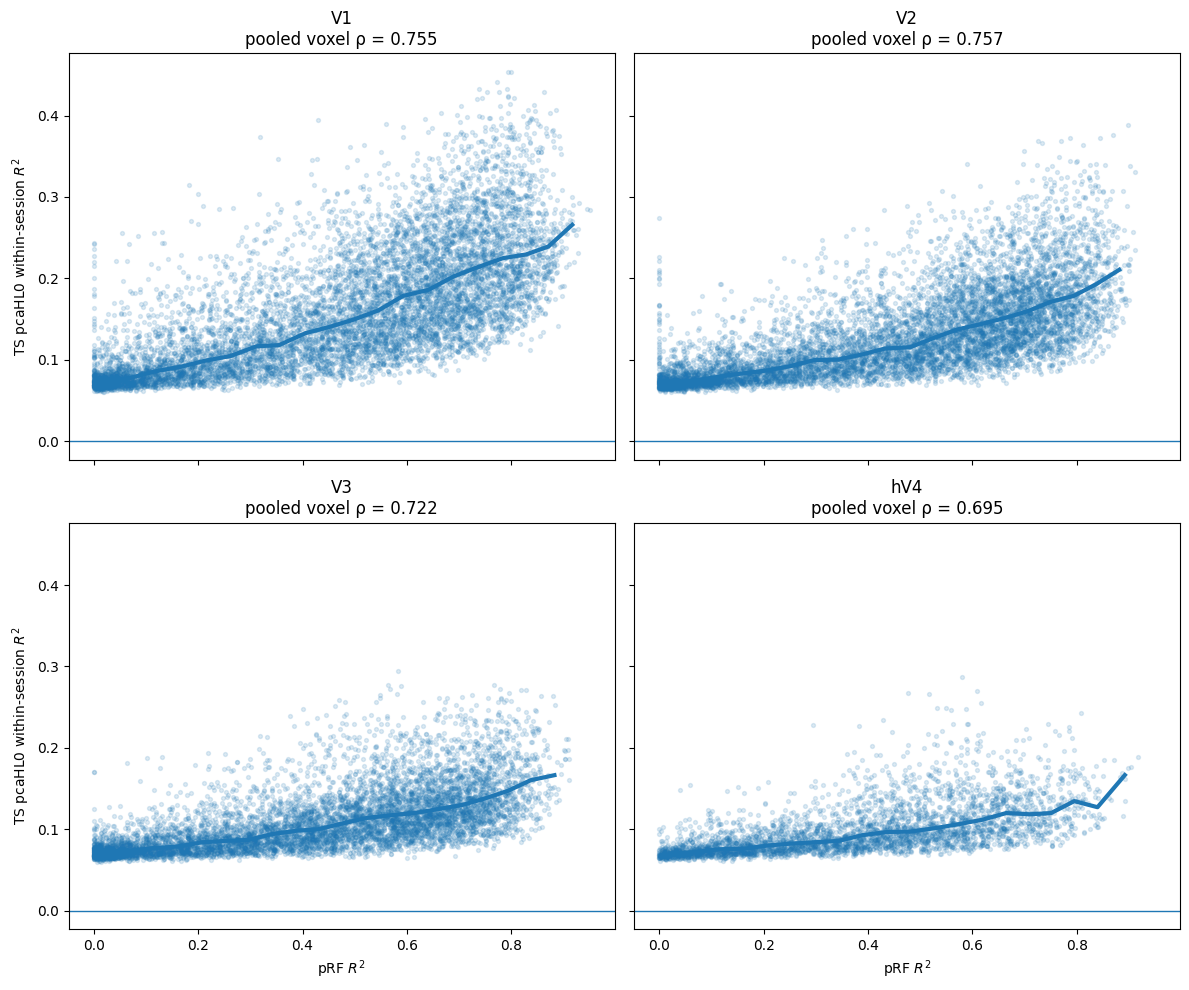

In [92]:
# =============================================================================
# FIGURE
# pRF R2 vs TS pcaHL0 R2
# =============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 10),
    sharex=True,
    sharey=True,
)

axes = axes.ravel()


for i, (ax, roi) in enumerate(
    zip(axes, ROIS)
):

    d = model_difference_df[
        model_difference_df["roi"] == roi
    ].copy()


    valid = (
        np.isfinite(
            d["prf_r2"]
        )
        &
        np.isfinite(
            d["TS_pca0_R2"]
        )
    )


    x = d.loc[
        valid,
        "prf_r2"
    ].values

    y = d.loc[
        valid,
        "TS_pca0_R2"
    ].values


    # -------------------------------------------------------------------------
    # Pooled voxel Spearman
    # -------------------------------------------------------------------------

    rho, _ = spearmanr(
        x,
        y
    )


    # -------------------------------------------------------------------------
    # Voxels
    # -------------------------------------------------------------------------

    ax.scatter(
        x,
        y,
        s=8,
        alpha=0.15,
    )


    # -------------------------------------------------------------------------
    # Binned median trend
    # -------------------------------------------------------------------------

    add_binned_median_line(
        ax,
        x,
        y,
        n_bins=20,
    )


    ax.axhline(
        0,
        linewidth=1,
    )


    ax.set_title(
        f"{roi}\n"
        f"pooled voxel ρ = {rho:.3f}"
    )


    # X label only bottom row
    if i >= 2:

        ax.set_xlabel(
            "pRF $R^2$"
        )


    # Y label only left column
    if i % 2 == 0:

        ax.set_ylabel(
            "TS pcaHL0 within-session $R^2$"
        )


plt.tight_layout()
plt.show()

In [97]:
import numpy as np
import pandas as pd

qc_rows = []

for subject in SUBJECTS:
    for roi in ROIS:

        d = model_difference_df[
            (model_difference_df["subject"] == subject) &
            (model_difference_df["roi"] == roi)
        ].copy()

        row = {
            "subject": subject,
            "roi": roi,
            "n_voxels": len(d),
        }

        # ---------------------------------------------------------
        # Check each relevant variable
        # ---------------------------------------------------------
        for col in ["prf_r2", "TS_R2", "SP4_R2"]:

            x = d[col].to_numpy(dtype=float)

            finite = np.isfinite(x)
            nan = np.isnan(x)
            inf = np.isinf(x)

            row[f"{col}_finite"] = finite.sum()
            row[f"{col}_nan"] = nan.sum()
            row[f"{col}_inf"] = inf.sum()
            row[f"{col}_pct_missing"] = 100 * (~finite).mean()

            if finite.any():
                xf = x[finite]

                row[f"{col}_min"] = np.min(xf)
                row[f"{col}_p01"] = np.percentile(xf, 1)
                row[f"{col}_median"] = np.median(xf)
                row[f"{col}_p99"] = np.percentile(xf, 99)
                row[f"{col}_max"] = np.max(xf)

                # Useful specifically for R²
                if col in ["TS_R2", "SP4_R2"]:
                    row[f"{col}_negative"] = np.sum(xf < 0)
                    row[f"{col}_pct_negative"] = 100 * np.mean(xf < 0)
                    row[f"{col}_exact_zero"] = np.sum(xf == 0)

        # ---------------------------------------------------------
        # Which model is responsible for missing voxels?
        # ---------------------------------------------------------
        ts_ok = np.isfinite(d["TS_R2"])
        sp_ok = np.isfinite(d["SP4_R2"])
        prf_ok = np.isfinite(d["prf_r2"])

        row["TS_missing_only"] = np.sum(~ts_ok & sp_ok & prf_ok)
        row["SP_missing_only"] = np.sum(ts_ok & ~sp_ok & prf_ok)
        row["pRF_missing_only"] = np.sum(ts_ok & sp_ok & ~prf_ok)

        row["all_three_valid"] = np.sum(
            ts_ok & sp_ok & prf_ok
        )

        qc_rows.append(row)


regression_qc_df = pd.DataFrame(qc_rows)

# Compact table first
display(
    regression_qc_df[
        [
            "subject", "roi", "n_voxels",

            "TS_R2_nan",
            "TS_R2_inf",
            "TS_R2_pct_missing",

            "SP4_R2_nan",
            "SP4_R2_inf",
            "SP4_R2_pct_missing",

            "prf_r2_nan",
            "prf_r2_pct_missing",

            "TS_missing_only",
            "SP_missing_only",
            "pRF_missing_only",

            "all_three_valid"
        ]
    ]
)

,subject,roi,n_voxels,TS_R2_nan,TS_R2_inf,TS_R2_pct_missing,SP4_R2_nan,SP4_R2_inf,SP4_R2_pct_missing,prf_r2_nan,prf_r2_pct_missing,TS_missing_only,SP_missing_only,pRF_missing_only,all_three_valid
0,1,V1,1350,0,0,0.0,0,0,0.0,33,2.444444,0,0,33,1317
1,1,V2,1433,0,0,0.0,0,0,0.0,65,4.535939,0,0,65,1368
2,1,V3,1187,0,0,0.0,0,0,0.0,21,1.769166,0,0,21,1166
3,1,hV4,687,0,0,0.0,0,0,0.0,52,7.569141,0,0,52,635
4,2,V1,1102,0,0,0.0,0,0,0.0,63,5.716878,0,0,63,1039
5,2,V2,1075,0,0,0.0,0,0,0.0,78,7.255814,0,0,78,997
6,2,V3,1097,0,0,0.0,0,0,0.0,51,4.649043,0,0,51,1046
7,2,hV4,483,0,0,0.0,0,0,0.0,28,5.797101,0,0,28,455
8,3,V1,1254,0,0,0.0,0,0,0.0,53,4.226475,0,0,53,1201
9,3,V2,1141,0,0,0.0,0,0,0.0,41,3.593339,0,0,41,1100


In [98]:
display(
    regression_qc_df[
        [
            "subject", "roi",

            "TS_R2_min",
            "TS_R2_p01",
            "TS_R2_median",
            "TS_R2_p99",
            "TS_R2_max",
            "TS_R2_pct_negative",

            "SP4_R2_min",
            "SP4_R2_p01",
            "SP4_R2_median",
            "SP4_R2_p99",
            "SP4_R2_max",
            "SP4_R2_pct_negative",
        ]
    ]
)

,subject,roi,TS_R2_min,TS_R2_p01,TS_R2_median,TS_R2_p99,TS_R2_max,TS_R2_pct_negative,SP4_R2_min,SP4_R2_p01,SP4_R2_median,SP4_R2_p99,SP4_R2_max,SP4_R2_pct_negative
0,1,V1,0.064529,0.070427,0.180024,0.387418,0.460108,0.0,-7.993606e-16,0.024363,0.125020,0.343448,0.430402,0.370370
1,1,V2,0.064815,0.067908,0.134223,0.312890,0.352287,0.0,3.700744e-17,0.023875,0.078304,0.251574,0.300384,0.000000
2,1,V3,0.063714,0.068329,0.122517,0.245079,0.284779,0.0,-2.960595e-17,0.023623,0.068423,0.180486,0.202044,0.084246
3,1,hV4,0.066313,0.067980,0.093924,0.219376,0.247128,0.0,-4.070818e-17,0.023426,0.043991,0.153065,0.210995,0.145560
4,2,V1,0.065821,0.068454,0.182706,0.417352,0.455669,0.0,-5.680641e-15,0.023162,0.117437,0.364590,0.399034,0.272232
5,2,V2,0.063220,0.066170,0.115033,0.303827,0.348202,0.0,-1.454392e-15,0.022247,0.059285,0.229574,0.272481,0.186047
6,2,V3,0.061139,0.066244,0.115549,0.267809,0.296472,0.0,1.480297e-17,0.022674,0.062085,0.203156,0.237601,0.000000
7,2,hV4,0.063280,0.067461,0.114793,0.256534,0.293964,0.0,2.162852e-02,0.023017,0.061263,0.203992,0.229876,0.000000
8,3,V1,0.064220,0.068703,0.160529,0.312456,0.329115,0.0,-4.884981e-16,0.024350,0.099846,0.265651,0.287693,0.079745
9,3,V2,0.063339,0.068614,0.125236,0.293817,0.378655,0.0,2.182655e-02,0.023692,0.069389,0.234072,0.282794,0.000000


In [93]:
# =============================================================================
# pRF CORRELATION:
# pcaHL0 vs pcaHL95
# =============================================================================

rows = []


for roi in ROIS:

    d = model_difference_df[
        model_difference_df["roi"] == roi
    ]


    for model_name, column in [

        ("pcaHL0", "TS_pca0_R2"),
        ("pcaHL95", "TS_R2"),

    ]:

        valid = (
            np.isfinite(d["prf_r2"])
            &
            np.isfinite(d[column])
        )

        rho, p = spearmanr(
            d.loc[valid, "prf_r2"],
            d.loc[valid, column]
        )


        rows.append({

            "roi": roi,
            "model": model_name,
            "n_voxels": int(valid.sum()),
            "rho_prf": rho,
            "p_value": p,
        })


pca_prf_comparison = pd.DataFrame(
    rows
)

display(
    pca_prf_comparison
)

,roi,model,n_voxels,rho_prf,p_value
0,V1,pcaHL0,8682,0.755193,0.0
1,V1,pcaHL95,8682,0.754559,0.0
2,V2,pcaHL0,8410,0.756552,0.0
3,V2,pcaHL95,8410,0.755845,0.0
4,V3,pcaHL0,7493,0.721845,0.0
5,V3,pcaHL95,7493,0.722571,0.0
6,hV4,pcaHL0,3677,0.695104,0.0
7,hV4,pcaHL95,3677,0.694463,0.0


# INSPECT pRF STRUCTURE IN TS AND SP4


In [45]:
# =============================================================================
# INSPECT TS GRID-5 pRF PARAMETERS
# =============================================================================

subject = 1
roi = "V1"

ts_file = get_ts_file(
    subject,
    roi,
)

with h5py.File(ts_file, "r") as f:

    prf_models = np.asarray(
        f["prf_models"]
    )

    fixed_prf = np.asarray(
        f["fixed_best_model_each_voxel"]
    ).squeeze()

    best_prf = np.asarray(
        f["best_prf_models"]
    ).squeeze()


print("prf_models shape:", prf_models.shape)

print("\nFirst 10 Grid-5 pRFs:")
print(prf_models[:10])

print("\nColumn ranges:")

for col in range(prf_models.shape[1]):

    print(
        f"column {col}:",
        "min =", np.nanmin(prf_models[:, col]),
        "| max =", np.nanmax(prf_models[:, col]),
        "| median =", np.nanmedian(prf_models[:, col]),
    )


print("\nfixed_best_model_each_voxel:")
print("shape:", fixed_prf.shape)
print("first 20:", fixed_prf[:20])
print(
    "range:",
    np.nanmin(fixed_prf),
    "to",
    np.nanmax(fixed_prf),
)


print("\nbest_prf_models:")
print("shape:", best_prf.shape)

# Check whether all sessions use exactly the fixed pRF
agreement = (
    best_prf
    ==
    fixed_prf[None, :]
)

print(
    "Fraction session × voxel matches fixed pRF:",
    np.mean(agreement)
)

prf_models shape: (1456, 3)

First 10 Grid-5 pRFs:
[[ 2.77555756e-17  0.00000000e+00  1.99999996e-02]
 [ 2.56428074e-17  1.06215996e-17  1.99999996e-02]
 [ 1.96261554e-17  1.96261554e-17  1.99999996e-02]
 [ 1.06215996e-17  2.56428074e-17  1.99999996e-02]
 [-1.21323474e-24  2.77555756e-17  1.99999996e-02]
 [-1.06215979e-17  2.56428091e-17  1.99999996e-02]
 [-1.96261554e-17  1.96261554e-17  1.99999996e-02]
 [-2.56428074e-17  1.06216004e-17  1.99999996e-02]
 [-2.77555756e-17 -2.42646949e-24  1.99999996e-02]
 [-2.56428074e-17 -1.06215996e-17  1.99999996e-02]]

Column ranges:
column 0: min = -0.8333333 | max = 0.8333333 | median = -4.411264e-25
column 1: min = -0.8333333 | max = 0.8333333 | median = -1.2132347e-24
column 2: min = 0.02 | max = 1.0 | median = 0.17575279

fixed_best_model_each_voxel:
shape: (1350,)
first 20: [968   0   0   0 304 288   0   0   0  18  18  22   0  44  17  17  22   0
  22 154]
range: 0 to 1292

best_prf_models:
shape: (30, 1350)
Fraction session × voxel matches fi

In [46]:
# =============================================================================
# TEST WHETHER TS FIXED pRF TRACKS THE ORIGINAL SP/NSD pRF
# WITHOUT ASSUMING THE SAME PHYSICAL UNITS
#
# We compare:
#   eccentricity rank
#   size rank
#
# separately for each subject × ROI.
# =============================================================================

import numpy as np
import pandas as pd
import h5py

from scipy.stats import spearmanr


def load_ts_fixed_prf_parameters(subject, roi):

    ts_file = get_ts_file(subject, roi)

    with h5py.File(ts_file, "r") as f:

        prf_models = np.asarray(
            f["prf_models"],
            dtype=float
        )

        fixed_idx = np.asarray(
            f["fixed_best_model_each_voxel"]
        ).squeeze().astype(int)

        voxel_index = np.asarray(
            f["voxel_index"]
        ).squeeze().astype(int)

    selected = prf_models[fixed_idx, :]

    ts_x = selected[:, 0]
    ts_y = selected[:, 1]
    ts_sigma = selected[:, 2]

    ts_ecc = np.sqrt(
        ts_x**2 +
        ts_y**2
    )

    return {
        "voxel_index": voxel_index,
        "x": ts_x,
        "y": ts_y,
        "ecc": ts_ecc,
        "size": ts_sigma,
        "prf_index": fixed_idx,
    }


def load_sp_prf_parameters(subject, roi):

    _, sp = load_sp_subject(
        SP4_ROOT,
        subject,
    )

    roi_idx = ROIS.index(roi)

    p = sp["allRoiPrf"][roi_idx]

    return {
        "x": np.asarray(p["x"], dtype=float),
        "y": np.asarray(p["y"], dtype=float),
        "ecc": np.asarray(p["ecc"], dtype=float),
        "size": np.asarray(p["sz"], dtype=float),
        "ang": np.asarray(p["ang"], dtype=float),
    }


rows = []

for subject in SUBJECTS:

    for roi in ROIS:

        ts = load_ts_fixed_prf_parameters(
            subject,
            roi,
        )

        sp = load_sp_prf_parameters(
            subject,
            roi,
        )

        # -----------------------------------------------------
        # Verify voxel counts
        # -----------------------------------------------------

        if len(ts["ecc"]) != len(sp["ecc"]):

            raise ValueError(
                f"S{subject} {roi}: "
                f"TS has {len(ts['ecc'])} voxels, "
                f"SP has {len(sp['ecc'])}"
            )

        # -----------------------------------------------------
        # Eccentricity
        # -----------------------------------------------------

        valid_ecc = (
            np.isfinite(ts["ecc"])
            &
            np.isfinite(sp["ecc"])
        )

        rho_ecc, p_ecc = spearmanr(
            ts["ecc"][valid_ecc],
            sp["ecc"][valid_ecc],
        )

        # -----------------------------------------------------
        # pRF size
        # -----------------------------------------------------

        valid_size = (
            np.isfinite(ts["size"])
            &
            np.isfinite(sp["size"])
        )

        rho_size, p_size = spearmanr(
            ts["size"][valid_size],
            sp["size"][valid_size],
        )

        rows.append({

            "subject": subject,
            "roi": roi,

            "n_voxels":
                len(ts["ecc"]),

            "rho_ecc_TS_vs_SP":
                rho_ecc,

            "p_ecc":
                p_ecc,

            "rho_size_TS_vs_SP":
                rho_size,

            "p_size":
                p_size,
        })


prf_correspondence_df = pd.DataFrame(rows)

display(
    prf_correspondence_df
)

,subject,roi,n_voxels,rho_ecc_TS_vs_SP,p_ecc,rho_size_TS_vs_SP,p_size
0,1,V1,1350,0.140330,2.255942e-07,0.031301,2.504405e-01
1,1,V2,1433,0.078527,2.933187e-03,0.024834,3.475095e-01
2,1,V3,1187,0.060490,3.718201e-02,0.061476,3.419275e-02
3,1,hV4,687,0.978154,0.000000e+00,0.869593,4.054670e-212
4,2,V1,1102,-0.094051,1.774864e-03,-0.060894,4.327454e-02
5,2,V2,1075,-0.022668,4.578104e-01,0.010171,7.390698e-01
6,2,V3,1097,0.055219,6.751517e-02,-0.005957,8.437603e-01
7,2,hV4,483,0.984220,0.000000e+00,0.845986,1.859175e-133
8,3,V1,1254,0.064021,2.338056e-02,-0.025544,3.661040e-01
9,3,V2,1141,0.077627,8.710043e-03,0.026084,3.787067e-01


In [47]:
prf_correspondence_summary = (
    prf_correspondence_df
    .groupby("roi")[
        [
            "rho_ecc_TS_vs_SP",
            "rho_size_TS_vs_SP",
        ]
    ]
    .agg(
        [
            "mean",
            "std",
            "median",
            "min",
            "max",
        ]
    )
    .reindex(ROIS)
)

display(
    prf_correspondence_summary
)

rho_ecc_TS_vs_SP                                          \
                mean       std    median       min       max   
roi                                                            
V1          0.045998  0.096753  0.048388 -0.094051  0.184370   
V2          0.067458  0.063151  0.078077 -0.022668  0.182845   
V3          0.073330  0.069483  0.085200 -0.039799  0.143398   
hV4         0.978075  0.007943  0.979849  0.961780  0.986804   

    rho_size_TS_vs_SP                                          
                 mean       std    median       min       max  
roi                                                            
V1          -0.004559  0.032290 -0.010552 -0.060894  0.031943  
V2           0.030550  0.046159  0.026373 -0.052163  0.114406  
V3           0.027457  0.043248  0.026516 -0.024217  0.091592  
hV4          0.829291  0.057484  0.840856  0.735005  0.896782

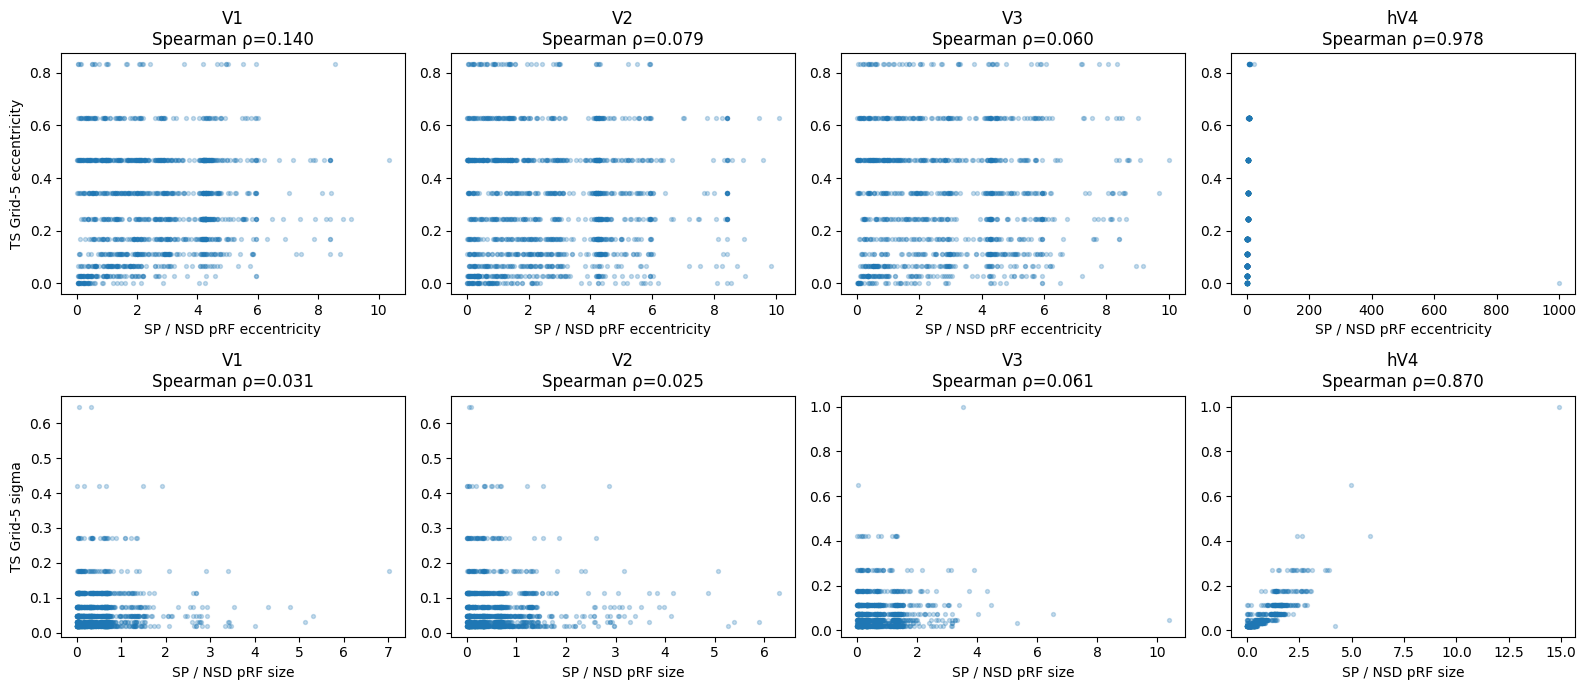

In [48]:
import matplotlib.pyplot as plt


subject = 1

fig, axes = plt.subplots(
    2,
    4,
    figsize=(16, 7),
)

for roi_idx, roi in enumerate(ROIS):

    ts = load_ts_fixed_prf_parameters(
        subject,
        roi,
    )

    sp = load_sp_prf_parameters(
        subject,
        roi,
    )

    # ---------------------------------------------------------
    # Eccentricity ranks
    # ---------------------------------------------------------

    ax = axes[0, roi_idx]

    ax.scatter(
        sp["ecc"],
        ts["ecc"],
        s=8,
        alpha=0.25,
    )

    rho, _ = spearmanr(
        sp["ecc"],
        ts["ecc"],
        nan_policy="omit",
    )

    ax.set_title(
        f"{roi}\nSpearman ρ={rho:.3f}"
    )

    ax.set_xlabel(
        "SP / NSD pRF eccentricity"
    )

    if roi_idx == 0:
        ax.set_ylabel(
            "TS Grid-5 eccentricity"
        )

    # ---------------------------------------------------------
    # Size
    # ---------------------------------------------------------

    ax = axes[1, roi_idx]

    ax.scatter(
        sp["size"],
        ts["size"],
        s=8,
        alpha=0.25,
    )

    rho, _ = spearmanr(
        sp["size"],
        ts["size"],
        nan_policy="omit",
    )

    ax.set_title(
        f"{roi}\nSpearman ρ={rho:.3f}"
    )

    ax.set_xlabel(
        "SP / NSD pRF size"
    )

    if roi_idx == 0:
        ax.set_ylabel(
            "TS Grid-5 sigma"
        )


plt.tight_layout()
plt.show()

# compare subject 1 v1 pcaHL0 with/without z score the features

In [67]:
from pathlib import Path
import numpy as np

MODEL_DIR = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/"
    "texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca0_use_nsd_grid5_pRFs"
)

files = sorted(MODEL_DIR.glob("*/all_fit_params.npy"))

print("Found", len(files), "runs\n")

for file in files:
    print("=" * 100)
    print("RUN:", file.parent.name)
    print("FILE:", file)

    obj = np.load(file, allow_pickle=True)

    if isinstance(obj, np.ndarray) and obj.dtype == object:
        obj = obj.item()

    for key in [
        "zscore_features",
        "zscore_betas_within_sess",
        "pca_pct_var",
        "pyr_pca_type",
        "ridge",
        "subject",
        "roi_name",
        "do_pyr_varpart",
    ]:
        print(f"{key}: {obj.get(key, 'NOT FOUND')}")

Found 2 runs

RUN: Aug-23-2026_0856_24
FILE: /content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca0_use_nsd_grid5_pRFs/Aug-23-2026_0856_24/all_fit_params.npy
zscore_features: False
zscore_betas_within_sess: NOT FOUND
pca_pct_var: 0
pyr_pca_type: pcaHL
ridge: False
subject: 1
roi_name: V1
do_pyr_varpart: False
RUN: Jul-14-2026_1724_04
FILE: /content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca0_use_nsd_grid5_pRFs/Jul-14-2026_1724_04/all_fit_params.npy
zscore_features: True
zscore_betas_within_sess: NOT FOUND
pca_pct_var: 0
pyr_pca_type: pcaHL
ridge: False
subject: 1
roi_name: V1
do_pyr_varpart: False


In [68]:
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/"
    "texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca0_use_nsd_grid5_pRFs"
)

RUNS = [
    BASE / "Aug-23-2026_0856_24",   # no z-score
    BASE / "Jul-14-2026_1724_04",   # z-score
]

for run in RUNS:
    print("\n" + "=" * 100)
    print("RUN:", run.name)
    print("=" * 100)

    for p in sorted(run.rglob("*")):
        if p.is_file():
            print(p.name)


RUN: Aug-23-2026_0856_24
all_fit_params.npy

RUN: Jul-14-2026_1724_04
all_fit_params.npy


In [69]:
from pathlib import Path
import numpy as np

BASE = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/"
    "texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca0_use_nsd_grid5_pRFs"
)

RUNS = {
    "raw": BASE / "Aug-23-2026_0856_24" / "all_fit_params.npy",
    "zscore": BASE / "Jul-14-2026_1724_04" / "all_fit_params.npy",
}

for label, file in RUNS.items():

    print("\n" + "=" * 100)
    print(label.upper())
    print("=" * 100)

    obj = np.load(file, allow_pickle=True)

    if isinstance(obj, np.ndarray) and obj.dtype == object:
        obj = obj.item()

    for key, value in obj.items():

        try:
            arr = np.asarray(value)

            print(
                f"{key:45s}",
                "shape =", arr.shape,
                "dtype =", arr.dtype
            )

        except Exception:
            print(
                f"{key:45s}",
                type(value)
            )


RAW
subject                                       shape = () dtype = int64
volume_space                                  shape = () dtype = bool
roi_name                                      shape = () dtype = <U2
pca_pct_var                                   shape = () dtype = int64
fitting_types                                 shape = (1,) dtype = <U15
voxel_mask                                    shape = (699192,) dtype = bool
average_image_reps                            shape = () dtype = bool
brain_nii_shape                               shape = (3,) dtype = int64
image_order                                   shape = (9209,) dtype = uint16
voxel_index                                   shape = (1, 2392) dtype = int64
voxel_roi                                     shape = (4, 2392) dtype = float64
voxel_ncsnr                                   shape = (2392,) dtype = float64
which_prf_grid                                shape = () dtype = int64
prfs_fixed_sigma                      

In [70]:
_, sp = load_sp_subject(SP4_ROOT, 1)

print("roiInd type:", type(sp["roiInd"]))

if isinstance(sp["roiInd"], (list, tuple)):
    print("roiInd length:", len(sp["roiInd"]))
    for i, x in enumerate(sp["roiInd"]):
        arr = np.asarray(x)
        print(i, arr.shape, arr.dtype, arr[:10] if arr.ndim == 1 else "")

else:
    arr = np.asarray(sp["roiInd"])
    print("roiInd shape:", arr.shape)
    print(arr)

roiInd type: <class 'list'>
roiInd length: 4
0 (1350,) int64 [268131 268293 268294 276676 276757 276758 276762 276838 276839 276840]
1 (1433,) int64 [242231 250781 250782 250783 250784 250861 250862 250863 250864 250865]
2 (1187,) int64 [216420 216421 216422 216503 216504 216505 224970 224971 225051 225052]
3 (687,) int64 [190851 190852 190933 199399 199400 199401 199482 199483 199484 199485]


In [71]:
print("visRoiData type:", type(sp["visRoiData"]))

if isinstance(sp["visRoiData"], (list, tuple)):
    print("length:", len(sp["visRoiData"]))
    for i, x in enumerate(sp["visRoiData"]):
        print(i, np.asarray(x).shape)
else:
    print("shape:", np.asarray(sp["visRoiData"]).shape)

visRoiData type: <class 'NoneType'>
shape: ()


In [72]:
import numpy as np

# ============================================================
# SP V1 voxel indices
# ============================================================

sp_v1_voxels = np.asarray(
    sp["roiInd"][0]
).astype(int)

print("SP V1 voxels:", len(sp_v1_voxels))
assert len(sp_v1_voxels) == 1350


# ============================================================
# Load RAW + ZSCORE
# ============================================================

raw_obj = np.load(
    RAW_FILE,
    allow_pickle=True
).item()

z_obj = np.load(
    ZSCORE_FILE,
    allow_pickle=True
).item()

raw_voxel_index = (
    np.asarray(raw_obj["voxel_index"])
    .squeeze()
    .astype(int)
)

z_voxel_index = (
    np.asarray(z_obj["voxel_index"])
    .squeeze()
    .astype(int)
)

print("RAW total:", len(raw_voxel_index))
print("ZSCORE total:", len(z_voxel_index))

assert np.array_equal(
    raw_voxel_index,
    z_voxel_index
)


# ============================================================
# Find exactly the SP-V1 voxels inside the 2392 TS voxels
# ============================================================

lookup = {
    voxel: i
    for i, voxel in enumerate(raw_voxel_index)
}

missing = [
    voxel
    for voxel in sp_v1_voxels
    if voxel not in lookup
]

print("Missing SP V1 voxels from TS full fit:", len(missing))

if len(missing) > 0:
    print("First missing:", missing[:20])
    raise ValueError(
        "Some SP V1 voxels are not present in the TS full-data fit."
    )

ts_positions = np.asarray(
    [lookup[v] for v in sp_v1_voxels],
    dtype=int
)

print("Matched positions:", ts_positions.shape)
assert len(ts_positions) == 1350


# ============================================================
# Extract the same exact 1350 voxels
# ============================================================

r2_raw = (
    np.asarray(raw_obj["val_r2"])
    .squeeze()[ts_positions]
    .astype(float)
)

cc_raw = (
    np.asarray(raw_obj["val_cc"])
    .squeeze()[ts_positions]
    .astype(float)
)

r2_zscore = (
    np.asarray(z_obj["val_r2"])
    .squeeze()[ts_positions]
    .astype(float)
)

cc_zscore = (
    np.asarray(z_obj["val_cc"])
    .squeeze()[ts_positions]
    .astype(float)
)

matched_voxel_index = raw_voxel_index[ts_positions]


# ============================================================
# Final alignment check
# ============================================================

print("\nFinal shapes:")
print("R2 raw:", r2_raw.shape)
print("Pearson raw:", cc_raw.shape)
print("R2 zscore:", r2_zscore.shape)
print("Pearson zscore:", cc_zscore.shape)

print(
    "Exact order matches SP roiInd:",
    np.array_equal(
        matched_voxel_index,
        sp_v1_voxels
    )
)

assert np.array_equal(
    matched_voxel_index,
    sp_v1_voxels
)

SP V1 voxels: 1350
RAW total: 2392
ZSCORE total: 2392
Missing SP V1 voxels from TS full fit: 0
Matched positions: (1350,)

Final shapes:
R2 raw: (1350,)
Pearson raw: (1350,)
R2 zscore: (1350,)
Pearson zscore: (1350,)
Exact order matches SP roiInd: True


In [73]:
from scipy.stats import spearmanr, pearsonr
import numpy as np

for label, r2, cc in [
    ("RAW", r2_raw, cc_raw),
    ("ZSCORE", r2_zscore, cc_zscore),
]:

    valid = np.isfinite(r2) & np.isfinite(cc)

    rho, p_rho = spearmanr(
        r2[valid],
        cc[valid]
    )

    r, p_r = pearsonr(
        r2[valid],
        cc[valid]
    )

    print("\n" + "=" * 60)
    print(label)
    print("=" * 60)
    print("Valid voxels:", valid.sum())
    print(f"Spearman R² vs Pearson: rho = {rho:.6f}, p = {p_rho:.3e}")
    print(f"Pearson  R² vs Pearson: r   = {r:.6f}, p = {p_r:.3e}")

    print(f"Median R²:      {np.nanmedian(r2[valid]):.6f}")
    print(f"Median Pearson: {np.nanmedian(cc[valid]):.6f}")


RAW
Valid voxels: 1350
Spearman R² vs Pearson: rho = 0.991486, p = 0.000e+00
Pearson  R² vs Pearson: r   = 0.190279, p = 1.798e-12
Median R²:      0.171168
Median Pearson: 0.417755

ZSCORE
Valid voxels: 1350
Spearman R² vs Pearson: rho = 0.991486, p = 0.000e+00
Pearson  R² vs Pearson: r   = 0.190279, p = 1.798e-12
Median R²:      0.171169
Median Pearson: 0.417755
